# UI optimization: organising a student's prompts into a forest

HCI 2026, group 19 (Arbor), Milestone 3. A judge scores where a new prompt could go; an integer
program, solved with Gurobi, decides what actually happens to the forest.

**How this notebook runs**

1. **Input** (Section 3): the 25 prompts of one study session, sorted by hand into the forest a
   person would build. This is the ideal forest.
2. **Step by step** (Section 4): the prompts arrive one at a time. For every step you see what goes
   in (the forest so far and the new prompt), what the judge answers, and what comes out (the IP's
   action and the new forest), next to the ideal answer and two alternative designs.
3. **Comparison** (Section 5): what the three approaches did per step and the forests they end with.
4. **Graphs and diagrams** (Section 6): agreement and disruption over the session, the action per
   step, and how the stability weights change the result.

It runs top to bottom from the committed data with no API key or login: the judge's answers (Claude
Haiku 5.5) are read from `data/llm_answers.jsonl`, and no model call is ever made here. Code: `forest/`
next to this notebook. Analysis notebooks: `notebooks/01` to `03`.

## 1. Problem and formulation

A study session produces many prompts. Arbor sorts them into a **forest**: **groups** (subjects)
hold **trees** of **topics**, and every prompt sits in one topic. When a prompt arrives, one of five
things happens:

| | Outcome | Meaning |
|---|---|---|
| (a) | add | into an existing topic |
| (b) | new branch | a new topic under an existing topic |
| (c) | new tree | a new topic directly under an existing group |
| (d) | new group | a new group with a new tree |
| (e) | restructure | existing prompts or topics move (also under a newly inserted topic), or empty topics are deleted |

```
new prompt + current forest -> [judge] -> scores and proposals -> [integer program, Gurobi] -> new forest + action
```

The **judge** rates the fit of the new prompt to every topic (5 exactly right ... 1 unrelated),
proposes up to 2 new topics with rated parents, and up to 6 moves of old prompts or topics. It never
decides. The **IP** decides which proposals to adopt, trading semantic fit against balance and
stability: moving what the student has seen breaks their mental map.

**Candidate links.** Variables exist only for: each old prompt's current topic; the new prompt to
every existing and proposed topic; the proposed prompt moves; each topic's current parent; the
parents listed for proposed topics; the proposed topic moves. A current link keeps the fit stored
when it was made; new links take the judge's fit, rescaled `(fit - 1) / 4`. Keeping current links
makes "change nothing, add the new prompt somewhere" always feasible.

**Variables.** $y_c$ (category exists), $q_{pc}$ (prompt in topic), $x_{c'c}$ (topic under topic),
$xg_{gc}$ (tree root in group): binary. $d_c \in \{0..D-1\}$ depth. $m_p$, $k_c$: prompt moved,
category moved or removed; $z$ any restructure. $o_c, u_c, b_c \ge 0$: too full, too sparse, too
many children. Weights $w_p = 1 + 2e^{-(t - t^{created}_p)/5}$ and $v_c$ = max $w$ in the subtree.

**Objective (maximise).**
$$\sum s_{pc} q_{pc} + \alpha \sum h_{c'c} x_{c'c} + \alpha_G \sum hg_{gc} xg_{gc}
 - \lambda \sum_{c \in C_T^{new}} y_c - \lambda_G \sum_{g \in C_G^{new}} y_g
 - \beta \sum_c (o_c + u_c + b_c) - \mu \sum_p w_p m_p - \nu \sum_c v_c k_c - F z$$

**Constraints.** C1 $\sum_c q_{pc} = 1$; C2 $q_{pc} \le y_c$; C3 $\sum x_{c'c} + \sum xg_{gc} = y_c$;
C4 $x_{c'c} \le y_{c'}$, $xg_{gc} \le y_g$; C5 $y_c \le \sum_p q_{pc} + \sum x_{cc''}$ (no empty topics);
C6 $y_g \le \sum_c xg_{gc}$ (no empty groups); C7 $d_c \ge d_{c'} + 1 - D(1 - x_{c'c})$;
C8 $d_c \le (D-1)(1 - \sum_g xg_{gc})$; C9 $\sum_p q_{pc} \le U + o_c$;
C10 $\sum_p q_{pc} + \sum x_{cc''} \ge L y_c - u_c$; C11 $\sum x_{cc''} \le B + b_c$;
C12 $\sum_c xg_{gc} \le K_T$; C13 $\sum_g y_g \le K_G$; C14 $m_p \ge 1 - q_{p,c_0(p)}$;
C15 $k_c \ge 1 - x_{\pi_0(c),c}$ (or $xg$); C16 $k_g \ge 1 - y_g$ for old groups; C17 $m_p \le z$, $k_c \le z$.

**Action.** (e) if $z = 1$; otherwise (a) if the new prompt is in an old topic, and (b), (c) or (d)
by where its new topic hangs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import viz
from forest.ip import ACTIONS, Params, load_config
from forest.model import load_ideal

cfg = load_config(ROOT / "config.yaml")
P = Params.from_config(cfg)
ideal = load_ideal()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

import numpy as np

from forest.ip import options, solve
from forest.judge import LLMJudge
from forest.simulate import run, summary

## 2. Parameters and their justification

In [2]:
why = {"L": "a topic with one prompt is barely a category", "U": "visible in the sidebar without scrolling",
       "B": "sibling lists stay scannable", "D": "deeper trees slow navigation", "K_T": "trees per group: sidebar space",
       "K_G": "groups: sidebar space", "alpha": "hierarchy matters less than prompt placement", "alpha_G": "same, for a tree in its group",
       "lam": "a new topic must gain 0.4 fit points",
       "lam_G": "plan start 1.0; below 1 + alpha_G - lam - beta = 0.8, else a new group can never be chosen",
       "beta": "per unit of imbalance", "mu": "per weighted moved prompt", "nu": "moving a topic moves its subtree",
       "F": "fixed cost of any visible reorganization"}
pd.DataFrame([{"parameter": k, "value": f"{getattr(P, k):g}", "why": v} for k, v in why.items()]).set_index("parameter")

,value,why
parameter,,
L,2,a topic with one prompt is barely a category
U,5,visible in the sidebar without scrolling
B,5,sibling lists stay scannable
D,3,deeper trees slow navigation
K_T,4,trees per group: sidebar space
K_G,4,groups: sidebar space
alpha,0.5,hierarchy matters less than prompt placement
alpha_G,0.5,"same, for a tree in its group"
lam,0.4,a new topic must gain 0.4 fit points


## 3. Input: the ideal forest
A person sorted the 25 prompts of one scripted session into groups, trees and topics
(`data/ideal_forest.yaml`, a draft by Claude Opus 5.5 that the group still reviews). The table gives
the order in which the prompts arrive, the topic each belongs to, and the outcome the session was
written to need at that step.

Neither the judge nor the IP sees this forest; it is the answer key for the comparisons in
Sections 4 to 6.

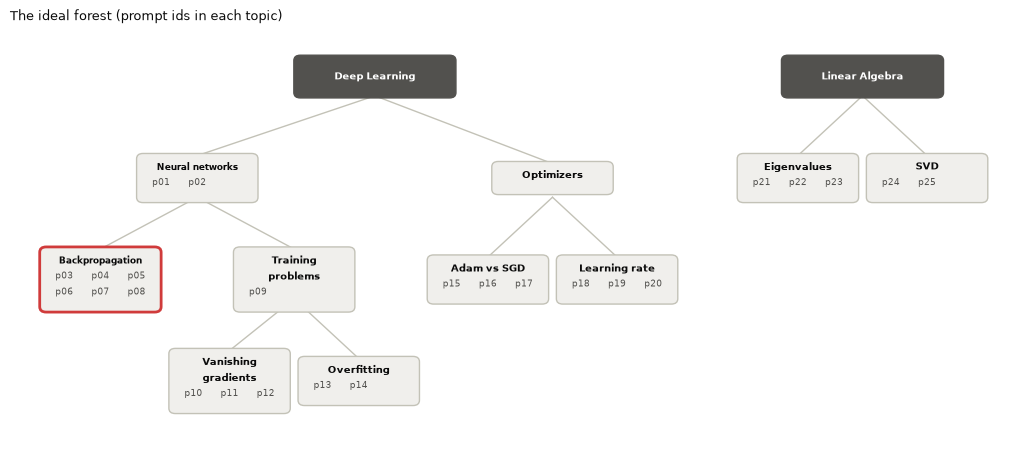

,prompt,text,ideal topic,intended
step,,,,
1,p01,What does a single neuron in a neural network actually compute?,Deep Learning > Neural networks,(d) new group
2,p03,How does the chain rule apply in backprop?,Deep Learning > Neural networks > Backpropagation,(b) new branch
3,p04,For a 2-layer MLP I wrote dL/dW1 = dL/dy * W2 * x. What am I missing?,Deep Learning > Neural networks > Backpropagation,(a) add
4,p02,Why do we need hidden layers at all? Couldn't one wide layer do the same?,Deep Learning > Neural networks,(a) add
5,p05,Why does backprop go backwards through the network instead of forwards?,Deep Learning > Neural networks > Backpropagation,(a) add
6,p10,Our net trains fine with 3 layers but with 10 layers the loss barely moves. Is that va...,Deep Learning > Neural networks > Training problems > Vanishing gradients,(b) new branch
7,p15,Should I use SGD or Adam for the exercise?,Deep Learning > Optimizers > Adam vs SGD,(c) new tree
8,p13,My training loss keeps going down but the validation loss goes up after epoch 5. What ...,Deep Learning > Neural networks > Training problems > Overfitting,(b) new branch
9,p06,"When I backprop through a max pooling layer, where does the gradient go?",Deep Learning > Neural networks > Backpropagation,(a) add


In [3]:
fig, ax = plt.subplots(figsize=(13, 5.5))
viz.draw_forest(ideal.forest, ax, P=P, title="The ideal forest (prompt ids in each topic)")
plt.show()
pd.DataFrame([{"step": i, "prompt": p, "text": ideal.forest.prompts[p].text,
               "ideal topic": ideal.forest.path(ideal.topic_of(p)),
               "intended": f"({ideal.intended[p][0]}) {ACTIONS[ideal.intended[p][0]]}"}
              for i, p in enumerate(ideal.arrival, 1)]).set_index("step")

## 4. Building the forest step by step
Every step takes an **input**, the forest so far and the new prompt, and produces an **output**: one
of the actions (a) to (e) and the new forest.

```
forest so far + new prompt -> [judge] -> fits, proposals, moves -> [IP, Gurobi] -> action + new forest
```

Three approaches get the same prompts in the same order, and each builds its own forest:

| Approach | What decides |
|---|---|
| `ip` | the judge rates, the integer program decides (this work) |
| `judge_argmax` | the LLM alone: the new prompt goes into the existing topic the judge rates highest, or into its proposed topic if that is rated strictly higher (under the parent rated highest). No costs, no balance, proposed moves ignored. It shows what the optimisation adds on top of the LLM. |
| `chronological` | no judge and no topics: a new tree for every 5 consecutive prompts ("Prompts 1-5", "Prompts 6-10", ...) in one group, like a chat sidebar sorted by time. The status quo. |

The judge is **Claude Haiku 5.5** (`claude-haiku-5-5`), called through the Claude Code CLI. Its
answers are frozen in `data/llm_answers.jsonl`; this notebook only reads them.

**For every step** there is a table (the input, the judge's answer, the IP's output with its
objective terms, the ideal answer, what the other two approaches did) and one figure, read top to
bottom:

1. **The forest the judge saw.** Each topic is shaded by the judge's fit of the new prompt, with the
   fit (1 to 5) in a badge. These are the *add* options. When the IP adds the prompt to an existing
   topic, that topic is **orange** and holds the new prompt.
2. **Every option, numbered**, grouped by where it comes from:
   - *Add to an existing topic.* The judge rates the new prompt against **every** existing topic.
     Each topic rated 2 or better is an option; nothing new is created.
   - *Create a new topic.* The judge **proposes** a topic that does not exist yet, rates the new
     prompt against it, and rates the parents it could go under. One option per parent: a new branch
     under a topic, a new tree under a group, or a new group.
   - *Restructure.* The judge proposes moving an old prompt or topic. One option per move.

   The IP solves every option on its own (that option forced, the rest as good as possible). Read a
   row left to right: what happens, the judge's fit (dots), then the IP's **gain** split into its
   terms (bars); the diamond is the sum. The shaded row is the IP's choice. ✓ placed right: the new
   prompt lands with exactly the prompts it shares a topic with in the ideal forest.
3. **One card per proposal**, numbered as in the table: every new topic the judge proposed (once per
   parent it rated, so a proposal with two parents gets two cards) and every proposed move. A card
   shows only the tree the option changes; the other trees of that group collapse into a dotted
   "+3 other trees" box, and groups the option does not touch are left out. A proposal is only a name
   the judge makes up for a topic that would hold the new prompt (step 3: "MLP Weight Gradients" for
   p04, a narrower topic than *Backpropagation*); the card shows where it would sit.
   **Green with a NEW badge** (and a green link to its parent): a topic or group the option creates.
   Green border: moved. A **red dashed card** is not possible: a hard limit rules it out, nearly
   always a fifth tree in a group that already has $K_T = 4$. It is drawn as the IP would build it
   without that limit, so the proposal stays visible; the IP never chooses it.

Every tree is drawn at the same scale: a bigger forest makes the figure taller, never the boxes
smaller.

The **gain** is how much an option changes the objective against the forest before the step (the
objective of the whole forest grows with every prompt, so only the change compares):

- **fit**: the new prompt's fit $s$; a new topic also adds $\alpha h$ for its parent link; a move
  adds the moved prompt's new fit minus its old one.
- **new categories**: $-\lambda$ per new topic, $-\lambda_G$ per new group.
- **imbalance**: $-\beta$ per prompt over $U$, per missing item under $L$, per child over $B$;
  filling a sparse topic earns $\beta$ back.
- **disruption**: $-\mu w_p$ per moved prompt, $-\nu v_c$ per moved topic, $-F$ once for any
  restructure.

*Example, step 6* (p10: "with 10 layers the loss barely moves. Is that vanishing gradients?"). Haiku
rates *Backpropagation* 4, *Hidden Layers* 3 and *Neuron Computation* 2, and proposes *Vanishing
Gradients* (fit 5) under *Backpropagation* (parent 4) or *Hidden Layers* (parent 3).

- Add to *Backpropagation*: its fit, **0.75**.
- Add to *Hidden Layers*: less fit (0.50), but 0.30 back because that topic held a single prompt
  (below L = 2): **0.80**.
- New topic under *Backpropagation*: 1.00 + 0.5 · 0.75 = 1.38 in fit, minus 0.40 for being new and
  0.30 for holding a single prompt: **0.67**.
- New topic under *Hidden Layers*: 1.00 + 0.5 · 0.50 = 1.25, minus 0.40; its single-prompt cost is
  cancelled because it fills *Hidden Layers* (a prompt and a child now): **0.85**, the IP's choice.

In [4]:
from IPython.display import Markdown, display

judge = LLMJudge(cfg, cached_only=True)   # answers from data/llm_answers.jsonl; never calls the model
if not judge.answers:
    raise RuntimeError("no frozen LLM answers in data/llm_answers.jsonl (README, 'The LLM judge')")
main = {"ip": run("ip", ideal, judge, P),
        "judge_argmax": run("judge_argmax", ideal, judge, P, save=False),
        "chronological": run("chronological", ideal, P=P, save=False)}
ip = main["ip"]
print(f"judge: {judge.name}, {len(judge.answers)} frozen answers")

judge: llm(claude-haiku-5-5), 49 frozen answers


#### Step 1 of 25

| | |
|---|---|
| **input** | new prompt **p01**: “What does a single neuron in a neural network actually compute?”<br>forest before: empty |
| **judge** | fits: no topics yet<br>proposes: new topic “Neuron Computation” (fit 5) under new group “Neural Networks” (parent fit 5); new topic “Weighted Sum and Activation” (fit 4) under “Neuron Computation” (proposed) (parent fit 4) or new group “Neural Networks” (parent fit 4)<br>moves: none |
| **output (IP)** | (d) new group: p01 → Neural Networks > Neuron Computation (new), alone ✓<br>rejected proposals: “Weighted Sum and Activation”<br>objective: fit +1.50, new categories -0.90, imbalance -0.30, disruption +0.00 → total 0.30 |
| **ideal** | (d) new group: p01 → Deep Learning > Neural networks, alone<br>why: first prompt: new group Deep Learning with the tree Neural networks |
| **judge_argmax** | (d) new group: p01 → Neural Networks > Neuron Computation (new), alone ✓ |
| **chronological** | (d) new group: p01 → Chat history > Prompts 1-5 (new), alone ✓ |

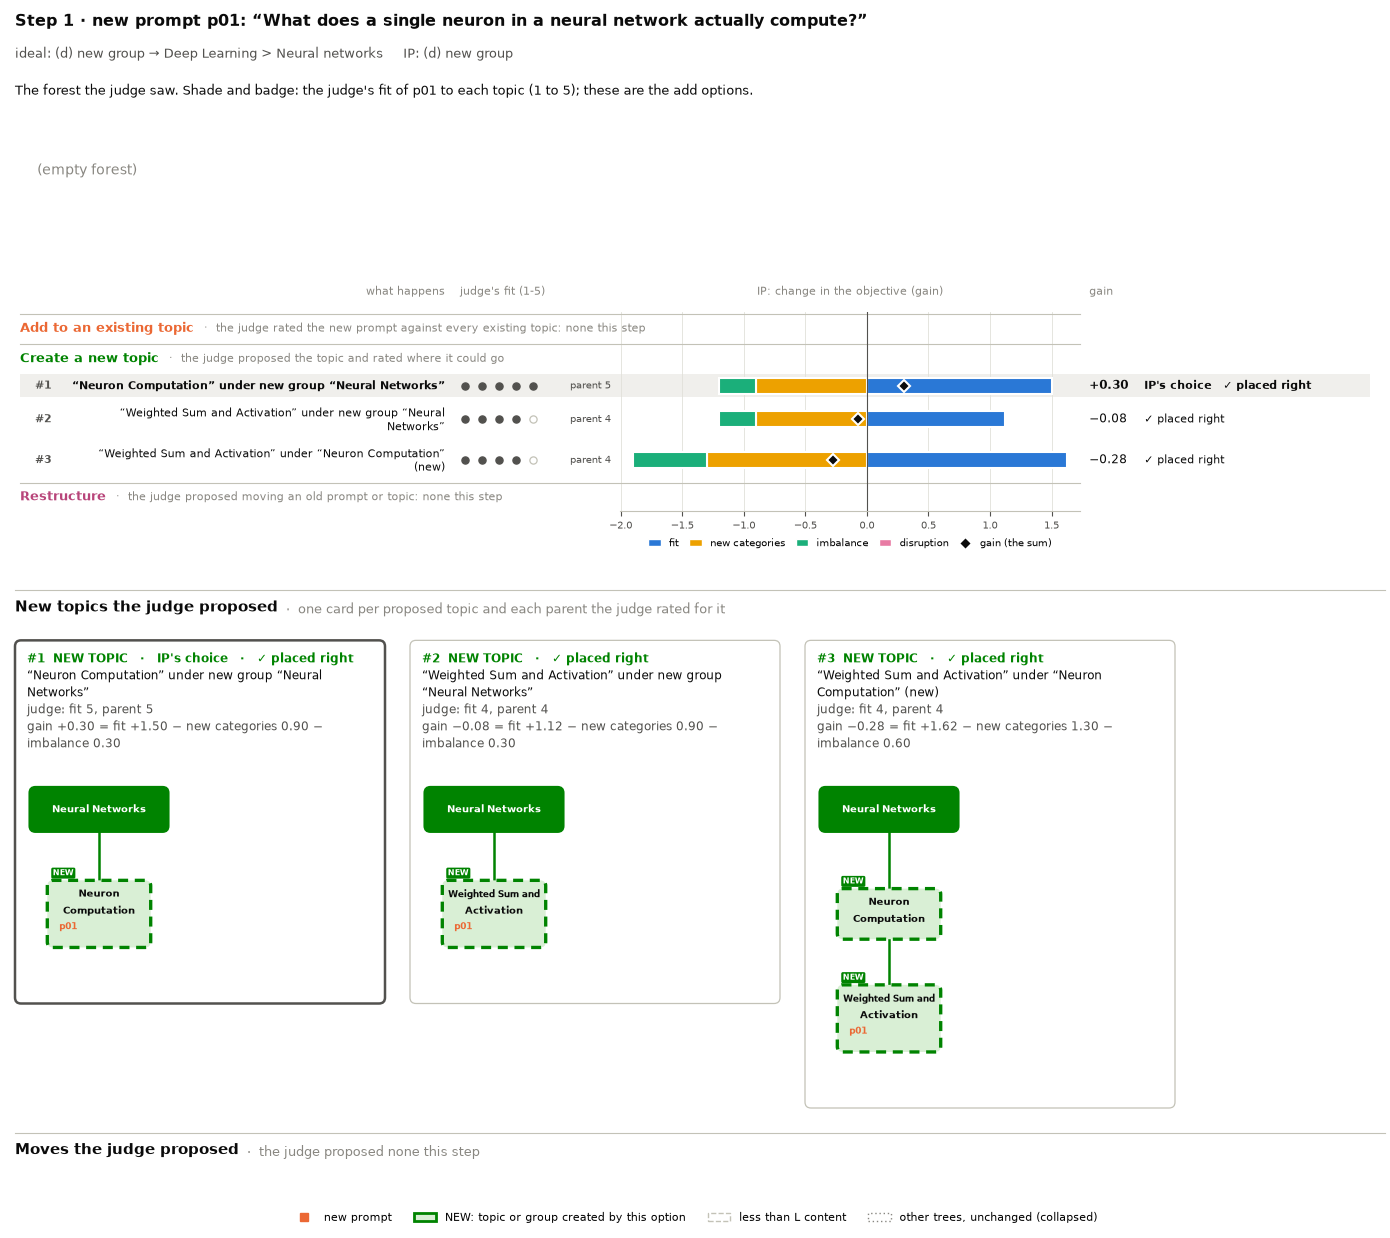

#### Step 2 of 25

| | |
|---|---|
| **input** | new prompt **p03**: “How does the chain rule apply in backprop?”<br>forest before: 1 group, 1 tree, 1 topic, 1 prompt |
| **judge** | fits: Neuron Computation (2)<br>proposes: new topic “Backpropagation” (fit 5) under Neural Networks (group) (parent fit 4); new topic “Chain Rule” (fit 4) under “Backpropagation” (proposed) (parent fit 4)<br>moves: none |
| **output (IP)** | (c) new tree: p03 → Neural Networks > Backpropagation (new), alone ✓<br>rejected proposals: “Chain Rule”<br>objective: fit +2.88, new categories -0.40, imbalance -0.60, disruption +0.00 → total 1.88 |
| **ideal** | (b) new branch: p03 → Deep Learning > Neural networks > Backpropagation, alone<br>why: Backpropagation, a branch under Neural networks |
| **judge_argmax** | (c) new tree: p03 → Neural Networks > Backpropagation (new), alone ✓ |
| **chronological** | (a) add: p03 → Chat history > Prompts 1-5, with p01 ✗ |

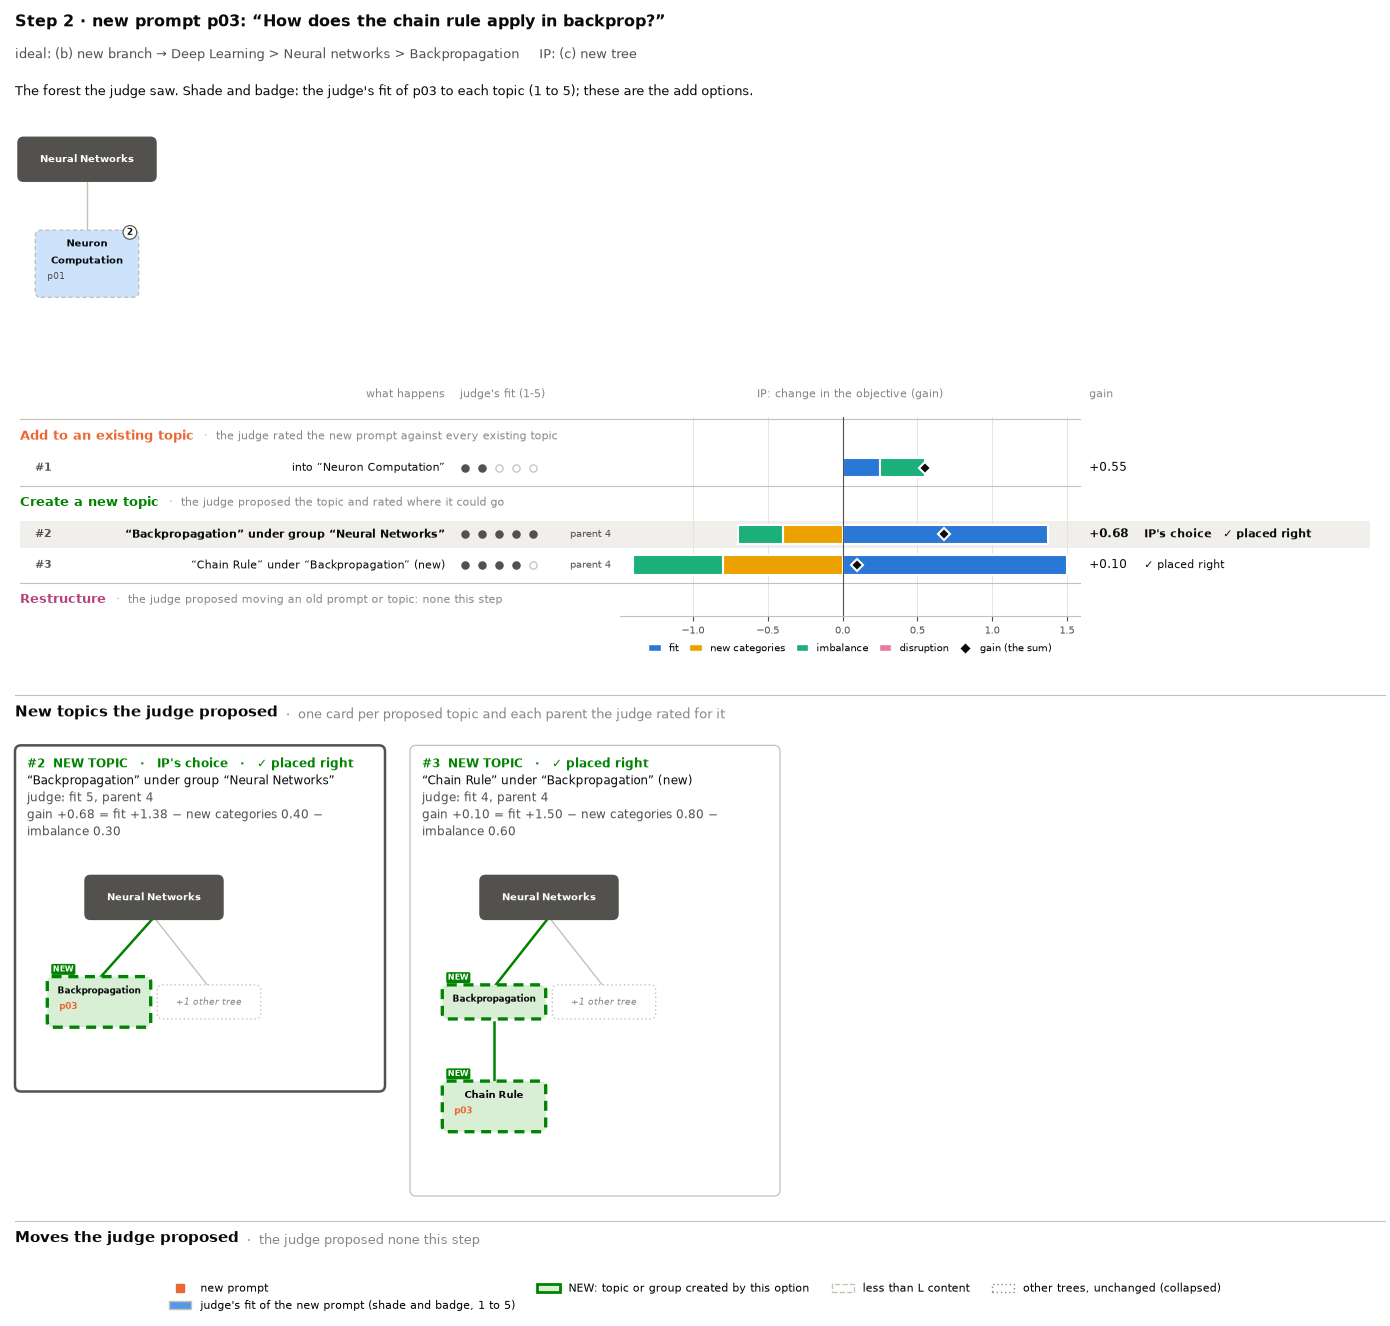

#### Step 3 of 25

| | |
|---|---|
| **input** | new prompt **p04**: “For a 2-layer MLP I wrote dL/dW1 = dL/dy * W2 * x. What am I missing?”<br>forest before: 1 group, 2 trees, 2 topics, 2 prompts |
| **judge** | fits: Backpropagation (4), Neuron Computation (2)<br>proposes: new topic “MLP Weight Gradients” (fit 5) under Backpropagation (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p04 → Neural Networks > Backpropagation, with p03 ✓<br>rejected proposals: “MLP Weight Gradients”<br>objective: fit +3.62, new categories +0.00, imbalance -0.30, disruption +0.00 → total 3.33 |
| **ideal** | (a) add: p04 → Deep Learning > Neural networks > Backpropagation, with p03 |
| **judge_argmax** | (b) new branch: p04 → Neural Networks > Backpropagation > MLP Weight Gradients (new), alone ✗ |
| **chronological** | (a) add: p04 → Chat history > Prompts 1-5, with p01, p03 ✗ |

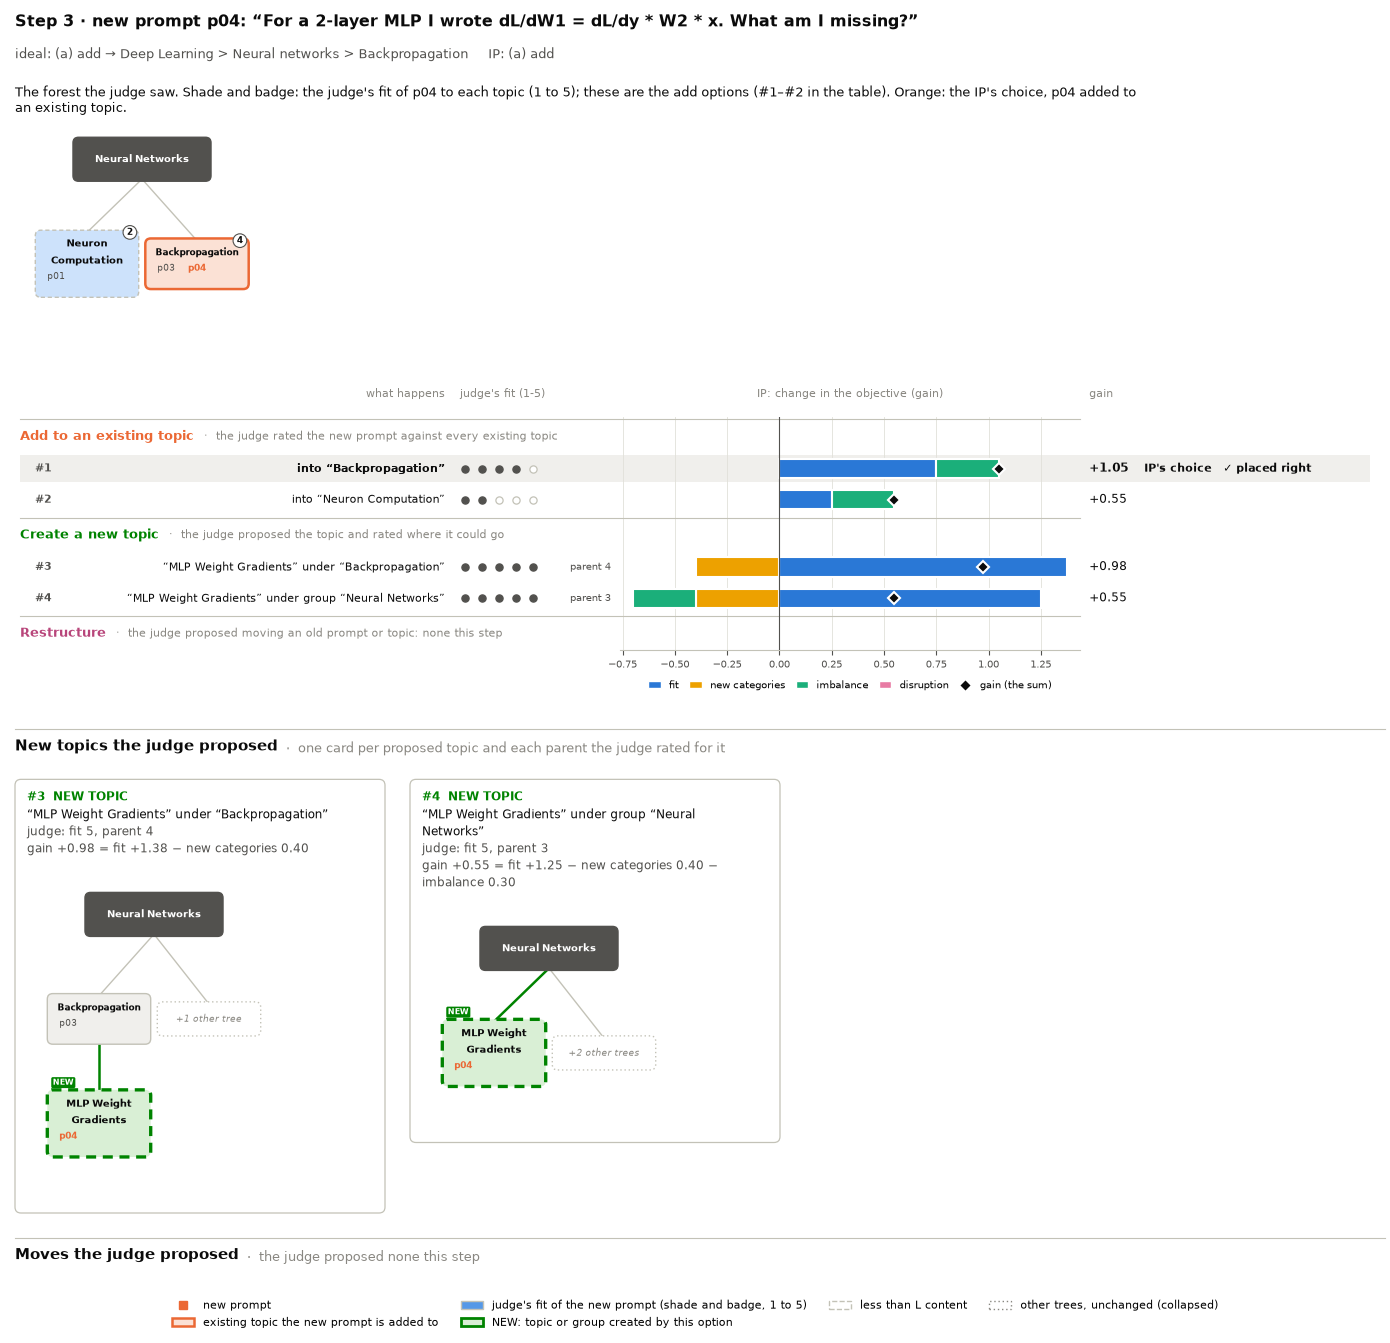

#### Step 4 of 25

| | |
|---|---|
| **input** | new prompt **p02**: “Why do we need hidden layers at all? Couldn't one wide layer do the same?”<br>forest before: 1 group, 2 trees, 2 topics, 3 prompts |
| **judge** | fits: Neuron Computation (2); 1 more at (1)<br>proposes: new topic “Hidden Layers” (fit 5) under Neural Networks (group) (parent fit 4); new topic “Depth vs Width” (fit 5) under “Hidden Layers” (proposed) (parent fit 5)<br>moves: none |
| **output (IP)** | (c) new tree: p02 → Neural Networks > Hidden Layers (new), alone ✗<br>rejected proposals: “Depth vs Width”<br>objective: fit +5.00, new categories -0.40, imbalance -0.60, disruption +0.00 → total 4.00 |
| **ideal** | (a) add: p02 → Deep Learning > Neural networks, with p01 |
| **judge_argmax** | (c) new tree: p02 → Neural Networks > Hidden Layers (new), alone ✗ |
| **chronological** | (a) add: p02 → Chat history > Prompts 1-5, with p01, p03, p04 ✗ |

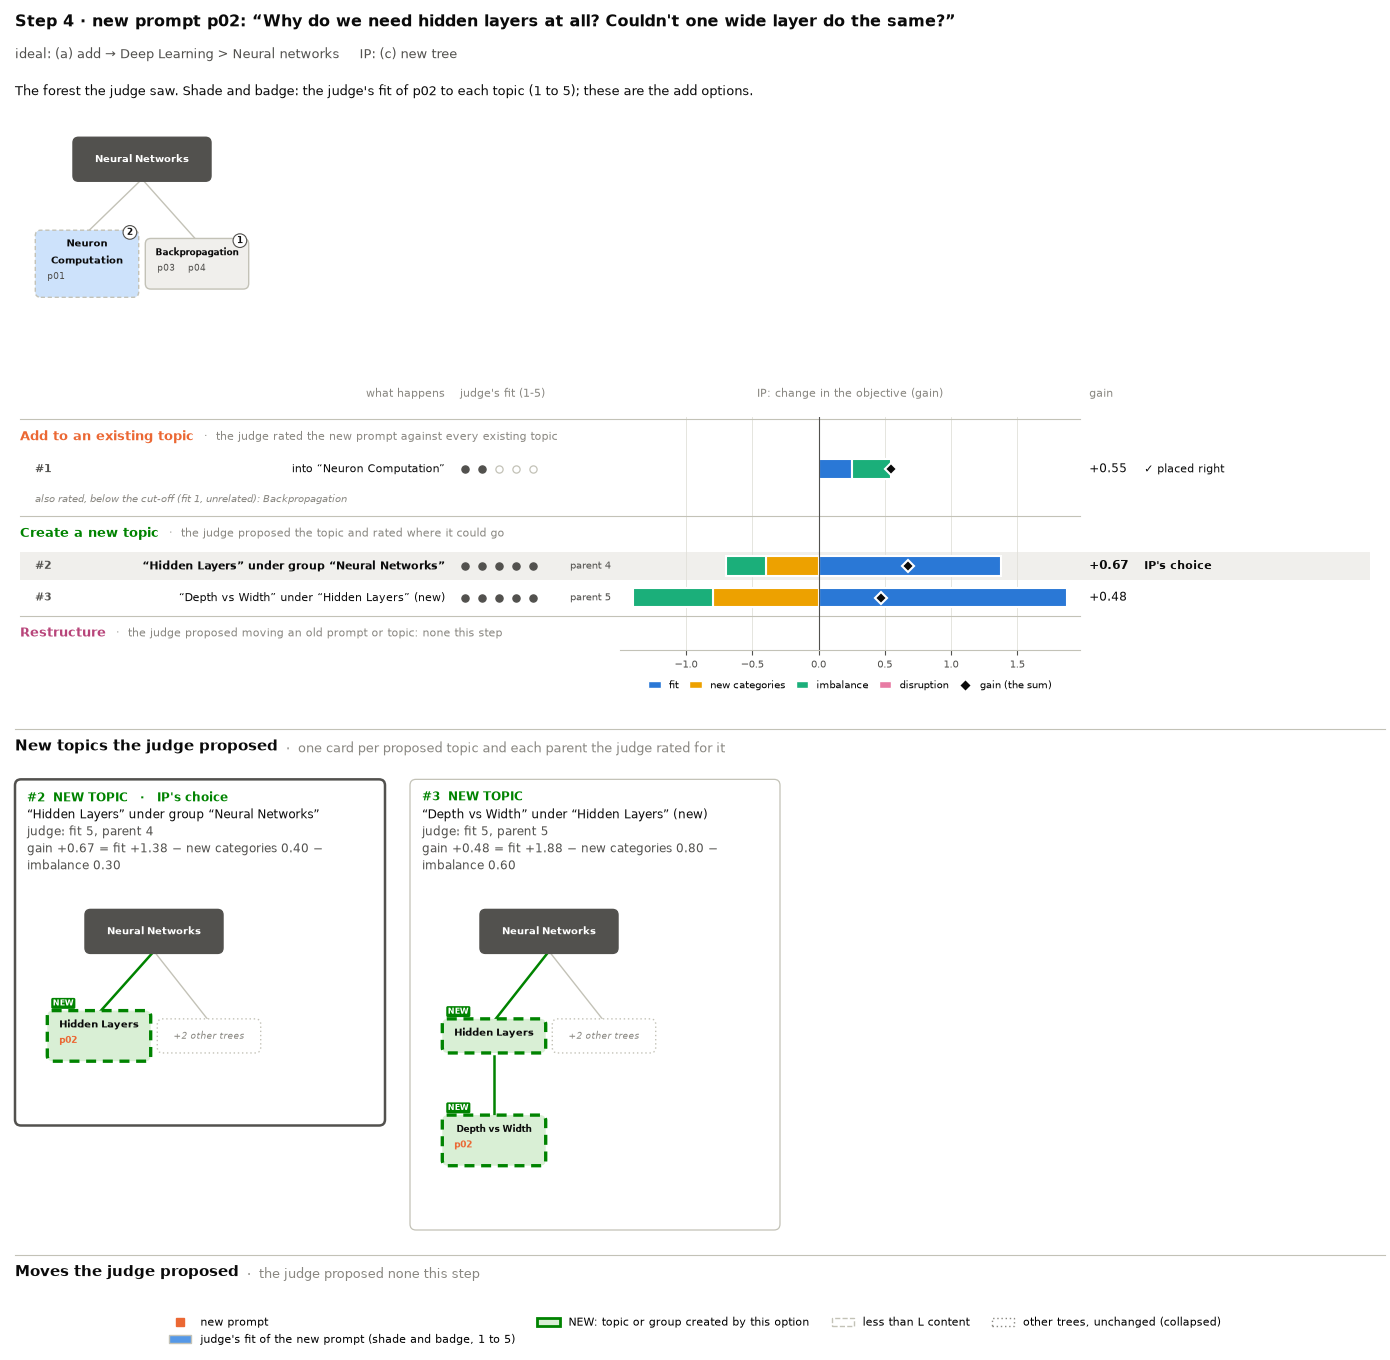

#### Step 5 of 25

| | |
|---|---|
| **input** | new prompt **p05**: “Why does backprop go backwards through the network instead of forwards?”<br>forest before: 1 group, 3 trees, 3 topics, 4 prompts |
| **judge** | fits: Backpropagation (5), Neuron Computation (2); 1 more at (1)<br>proposes: new topic “Forward vs Reverse Mode” (fit 5) under Backpropagation (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p05 → Neural Networks > Backpropagation, with p03, p04 ✓<br>rejected proposals: “Forward vs Reverse Mode”<br>objective: fit +6.00, new categories +0.00, imbalance -0.60, disruption +0.00 → total 5.40 |
| **ideal** | (a) add: p05 → Deep Learning > Neural networks > Backpropagation, with p03, p04 |
| **judge_argmax** | (a) add: p05 → Neural Networks > Backpropagation, with p03 ✗ |
| **chronological** | (a) add: p05 → Chat history > Prompts 1-5, with p01, p03, p04, p02 ✗ |

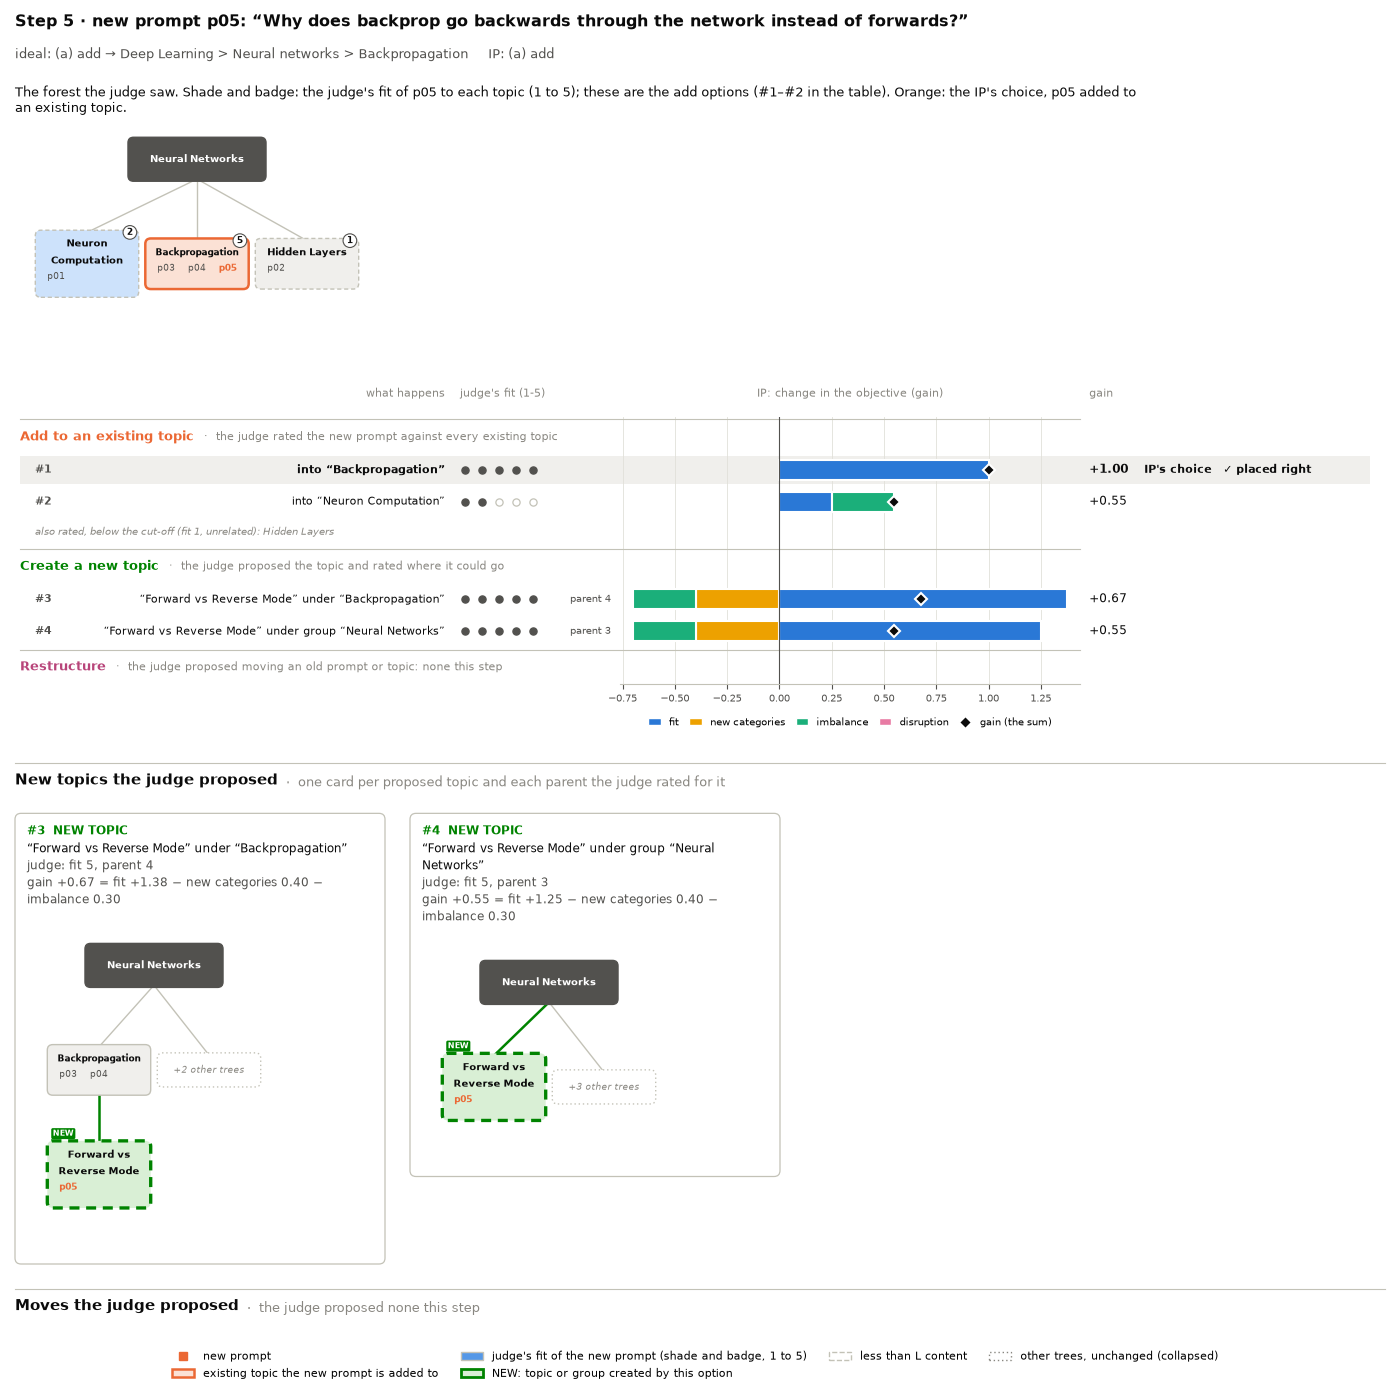

#### Step 6 of 25

| | |
|---|---|
| **input** | new prompt **p10**: “Our net trains fine with 3 layers but with 10 layers the loss barely moves. Is that vanishing gradients?”<br>forest before: 1 group, 3 trees, 3 topics, 5 prompts |
| **judge** | fits: Backpropagation (4), Hidden Layers (3), Neuron Computation (2)<br>proposes: new topic “Vanishing Gradients” (fit 5) under Backpropagation (parent fit 4) or Hidden Layers (parent fit 3)<br>moves: none |
| **output (IP)** | (b) new branch: p10 → Neural Networks > Hidden Layers > Vanishing Gradients (new), alone ✓<br>objective: fit +7.25, new categories -0.40, imbalance -0.60, disruption +0.00 → total 6.25 |
| **ideal** | (b) new branch: p10 → Deep Learning > Neural networks > Training problems > Vanishing gradients, alone<br>why: vanishing gradients after several backprop prompts: a new branch |
| **judge_argmax** | (b) new branch: p10 → Neural Networks > Backpropagation > Vanishing Gradients (new), alone ✓ |
| **chronological** | (c) new tree: p10 → Chat history > Prompts 6-10 (new), alone ✓ |

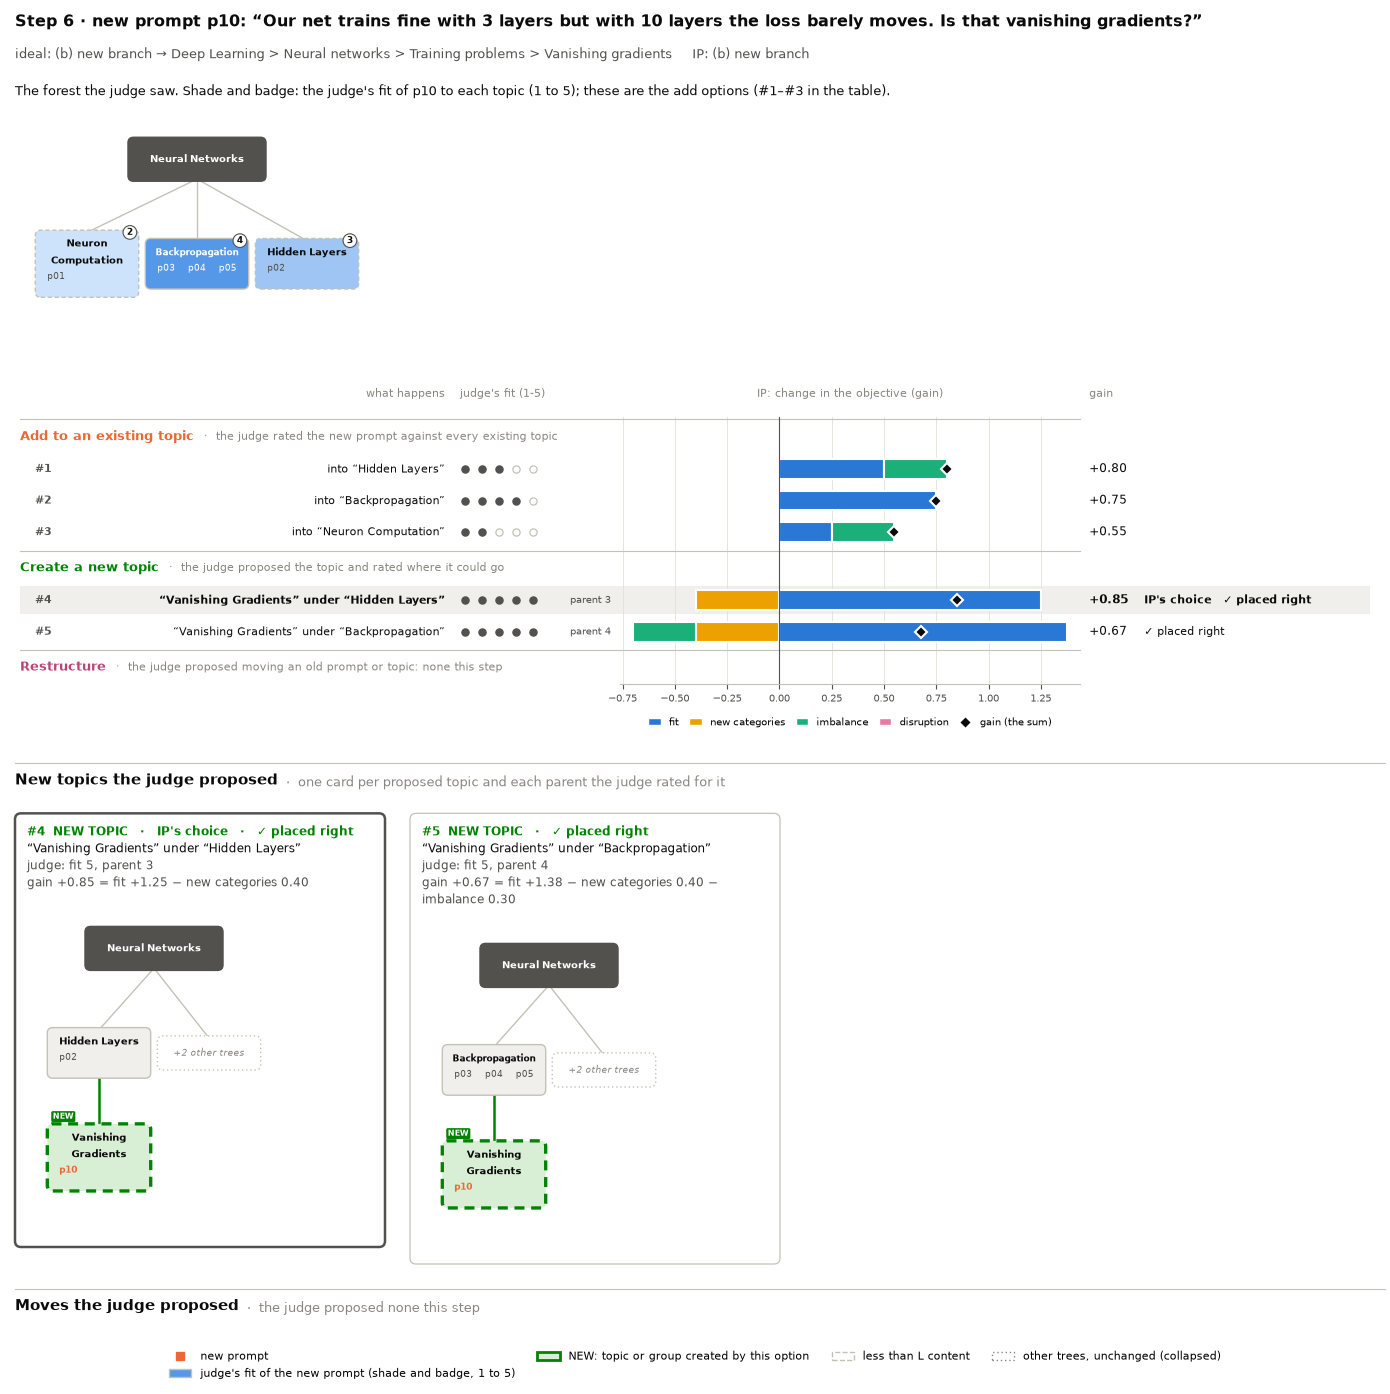

#### Step 7 of 25

| | |
|---|---|
| **input** | new prompt **p15**: “Should I use SGD or Adam for the exercise?”<br>forest before: 1 group, 3 trees, 4 topics, 6 prompts |
| **judge** | fits: Backpropagation (2), Vanishing Gradients (2); 2 more at (1)<br>proposes: new topic “Optimizers” (fit 5) under Neural Networks (group) (parent fit 4)<br>moves: none |
| **output (IP)** | (c) new tree: p15 → Neural Networks > Optimizers (new), alone ✓<br>objective: fit +8.62, new categories -0.40, imbalance -0.90, disruption +0.00 → total 7.33 |
| **ideal** | (c) new tree: p15 → Deep Learning > Optimizers > Adam vs SGD, alone<br>why: first optimizer prompt: a new tree |
| **judge_argmax** | (c) new tree: p15 → Neural Networks > Gradient Descent Optimizers (new), alone ✓ |
| **chronological** | (a) add: p15 → Chat history > Prompts 6-10, with p10 ✗ |

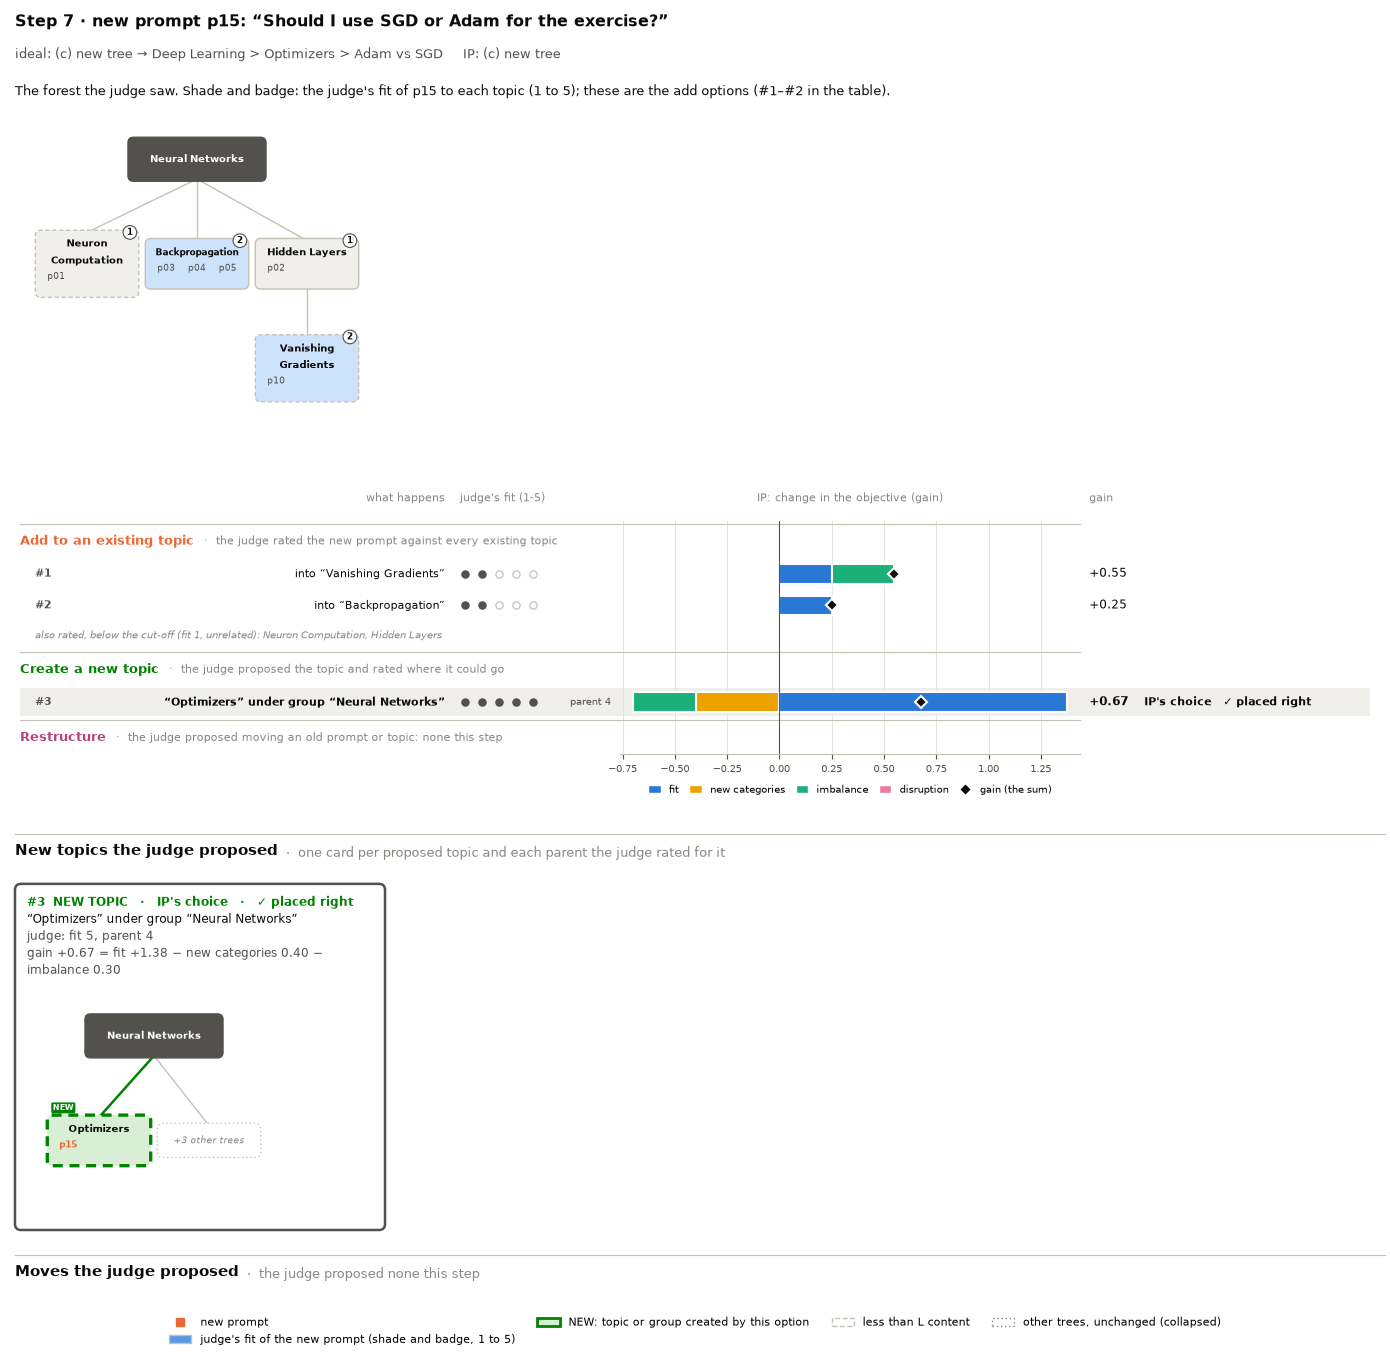

#### Step 8 of 25

| | |
|---|---|
| **input** | new prompt **p13**: “My training loss keeps going down but the validation loss goes up after epoch 5. What is happening?”<br>forest before: 1 group, 4 trees, 5 topics, 7 prompts |
| **judge** | fits: Hidden Layers (2), Optimizers (2); 3 more at (1)<br>proposes: new topic “Overfitting” (fit 5) under Neural Networks (group) (parent fit 4) or Hidden Layers (parent fit 2); new topic “Early Stopping” (fit 2) under “Overfitting” (proposed) (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p13 → Neural Networks > Optimizers, with p15 ✗<br>rejected proposals: “Overfitting”, “Early Stopping”<br>objective: fit +8.88, new categories +0.00, imbalance -0.60, disruption +0.00 → total 8.27 |
| **ideal** | (b) new branch: p13 → Deep Learning > Neural networks > Training problems > Overfitting, alone<br>why: overfitting, before Training problems is obvious |
| **judge_argmax** | (c) new tree: p13 → Neural Networks > Overfitting (new), alone ✓ |
| **chronological** | (a) add: p13 → Chat history > Prompts 6-10, with p10, p15 ✗ |

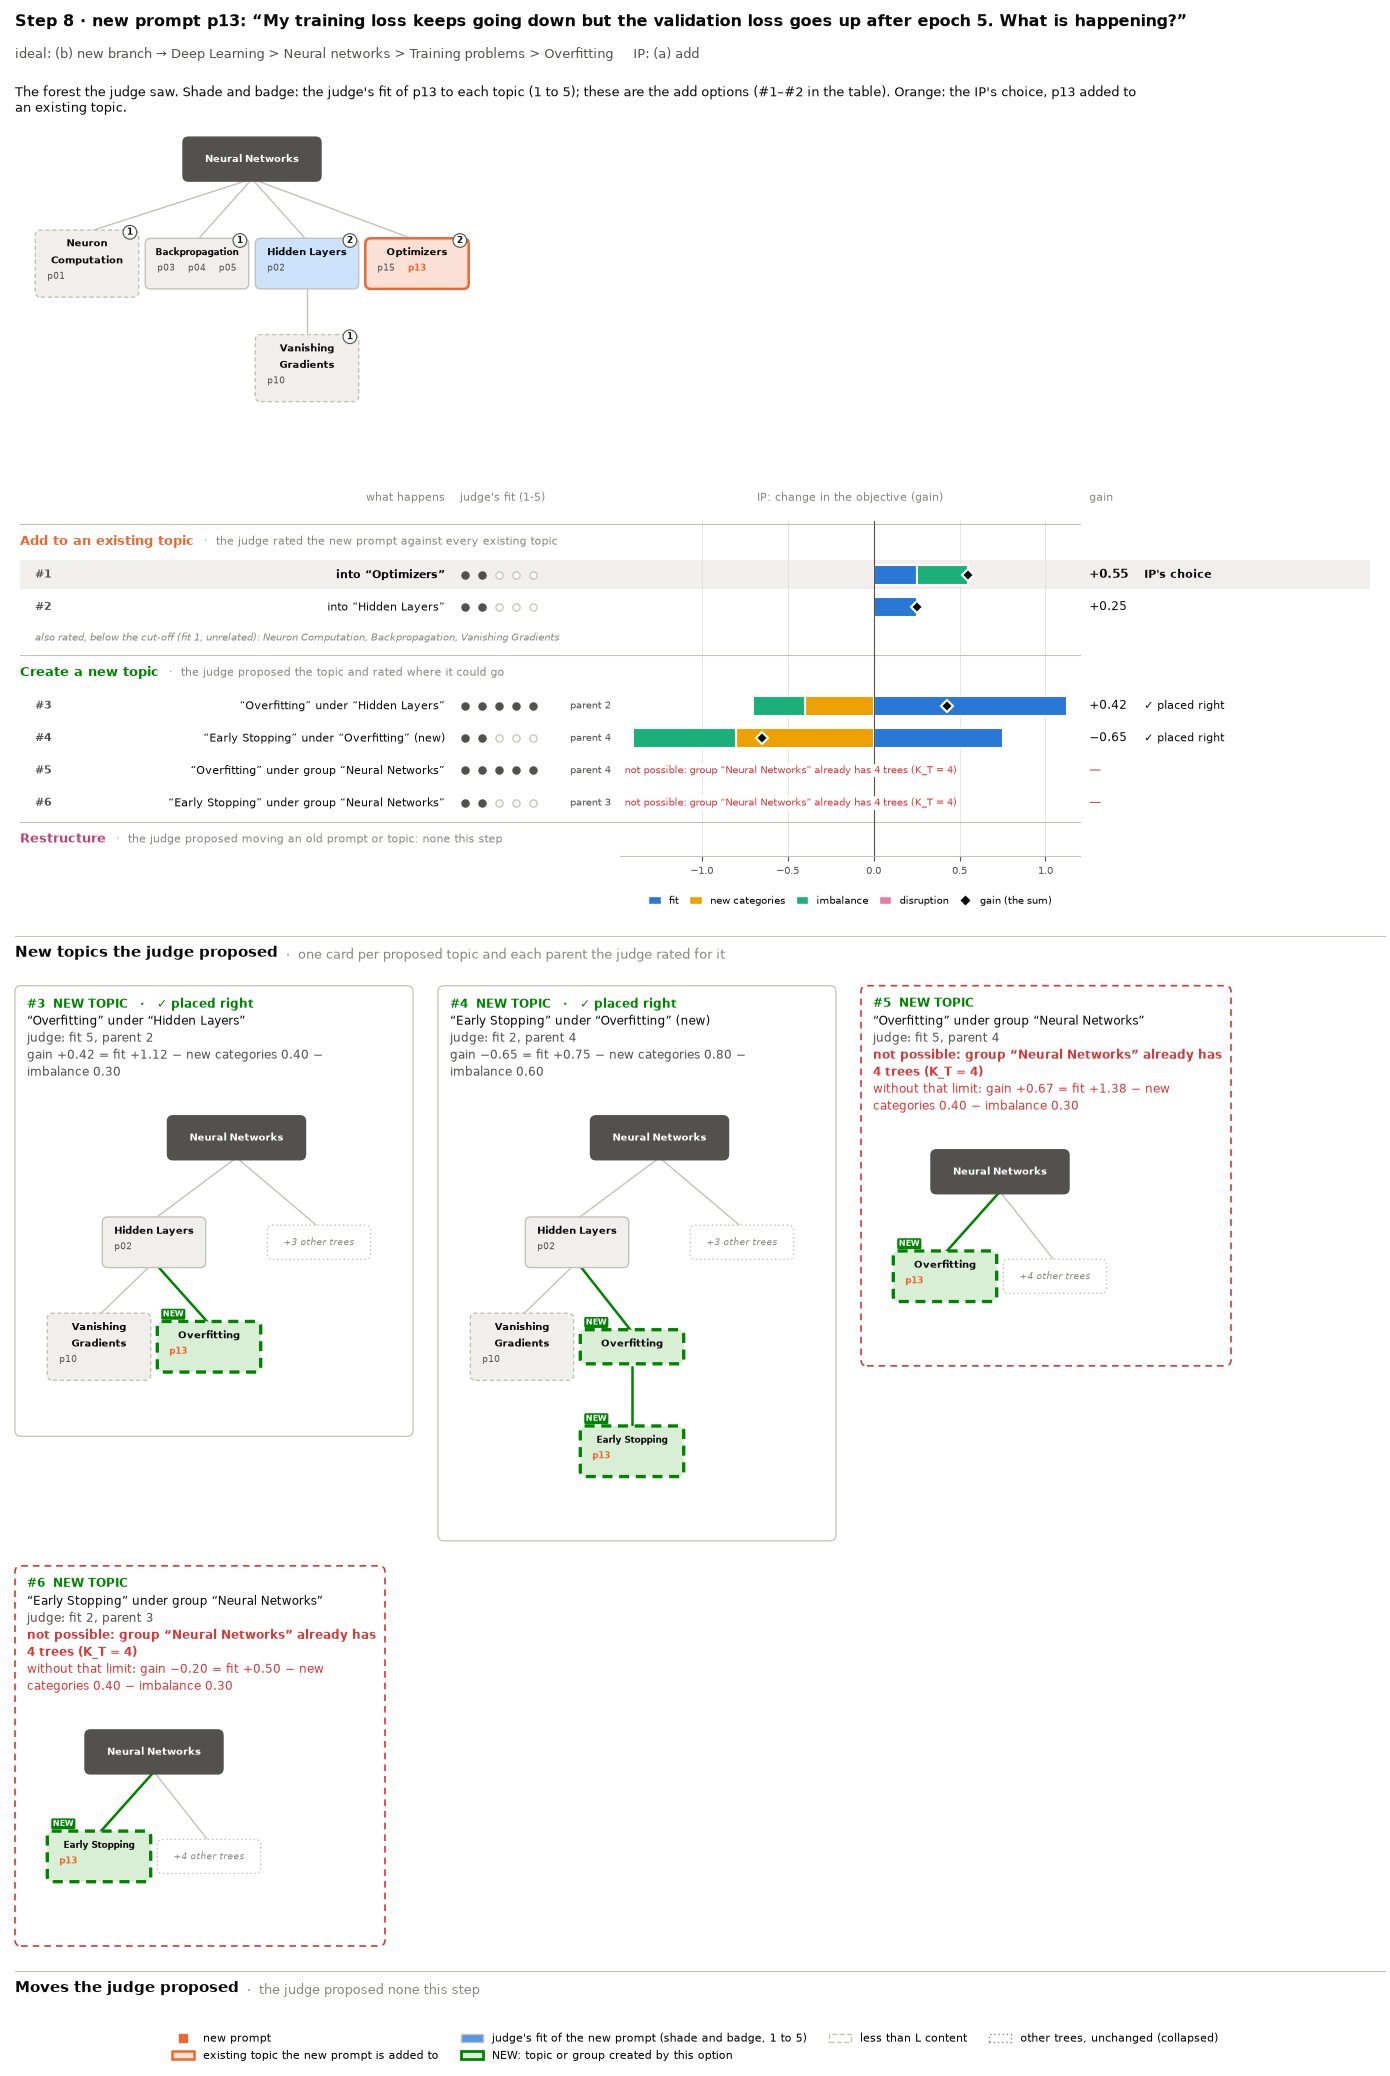

#### Step 9 of 25

| | |
|---|---|
| **input** | new prompt **p06**: “When I backprop through a max pooling layer, where does the gradient go?”<br>forest before: 1 group, 4 trees, 5 topics, 8 prompts |
| **judge** | fits: Backpropagation (4), Neuron Computation (2), Vanishing Gradients (2), Hidden Layers (2); 1 more at (1)<br>proposes: new topic “Max Pooling” (fit 5) under Hidden Layers (parent fit 3) or Backpropagation (parent fit 4)<br>moves: none |
| **output (IP)** | (a) add: p06 → Neural Networks > Backpropagation, with p03, p04, p05 ✓<br>rejected proposals: “Max Pooling”<br>objective: fit +9.62, new categories +0.00, imbalance -0.60, disruption +0.00 → total 9.02 |
| **ideal** | (a) add: p06 → Deep Learning > Neural networks > Backpropagation, with p03, p04, p05 |
| **judge_argmax** | (b) new branch: p06 → Neural Networks > Hidden Layers > Pooling Layers > Max Pooling Backprop (new), alone ✗ |
| **chronological** | (a) add: p06 → Chat history > Prompts 6-10, with p10, p15, p13 ✗ |

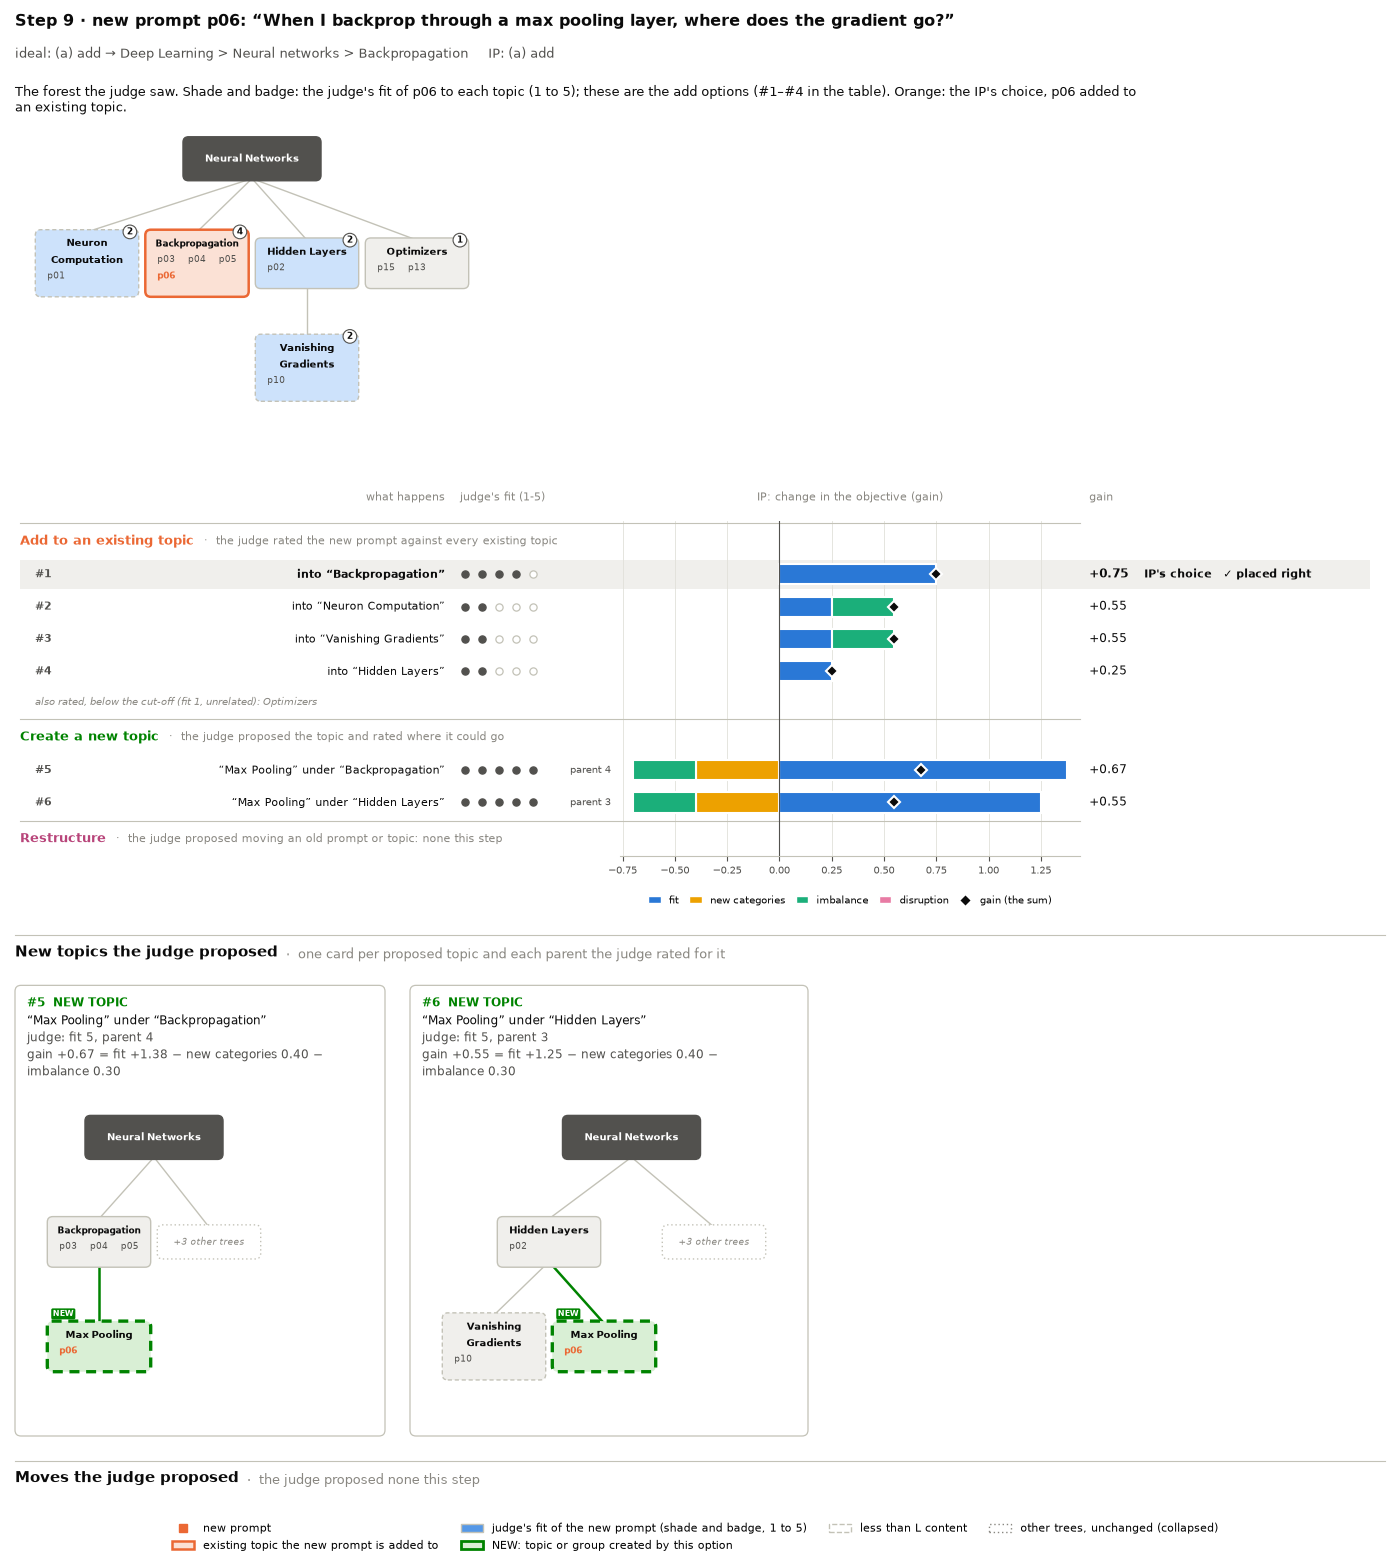

#### Step 10 of 25

| | |
|---|---|
| **input** | new prompt **p11**: “Why does the gradient shrink layer by layer with sigmoid activations?”<br>forest before: 1 group, 4 trees, 5 topics, 9 prompts |
| **judge** | fits: Vanishing Gradients (5), Backpropagation (4), Hidden Layers (3), Neuron Computation (2); 1 more at (1)<br>proposes: new topic “Activation Functions” (fit 4) under Neuron Computation (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p11 → Neural Networks > Hidden Layers > Vanishing Gradients, with p10 ✓<br>rejected proposals: “Activation Functions”<br>objective: fit +10.62, new categories +0.00, imbalance -0.30, disruption +0.00 → total 10.32 |
| **ideal** | (a) add: p11 → Deep Learning > Neural networks > Training problems > Vanishing gradients, with p10<br>why: vanishing gradients |
| **judge_argmax** | (a) add: p11 → Neural Networks > Backpropagation > Vanishing Gradients, with p10 ✓ |
| **chronological** | (a) add: p11 → Chat history > Prompts 6-10, with p10, p15, p13, p06 ✗ |

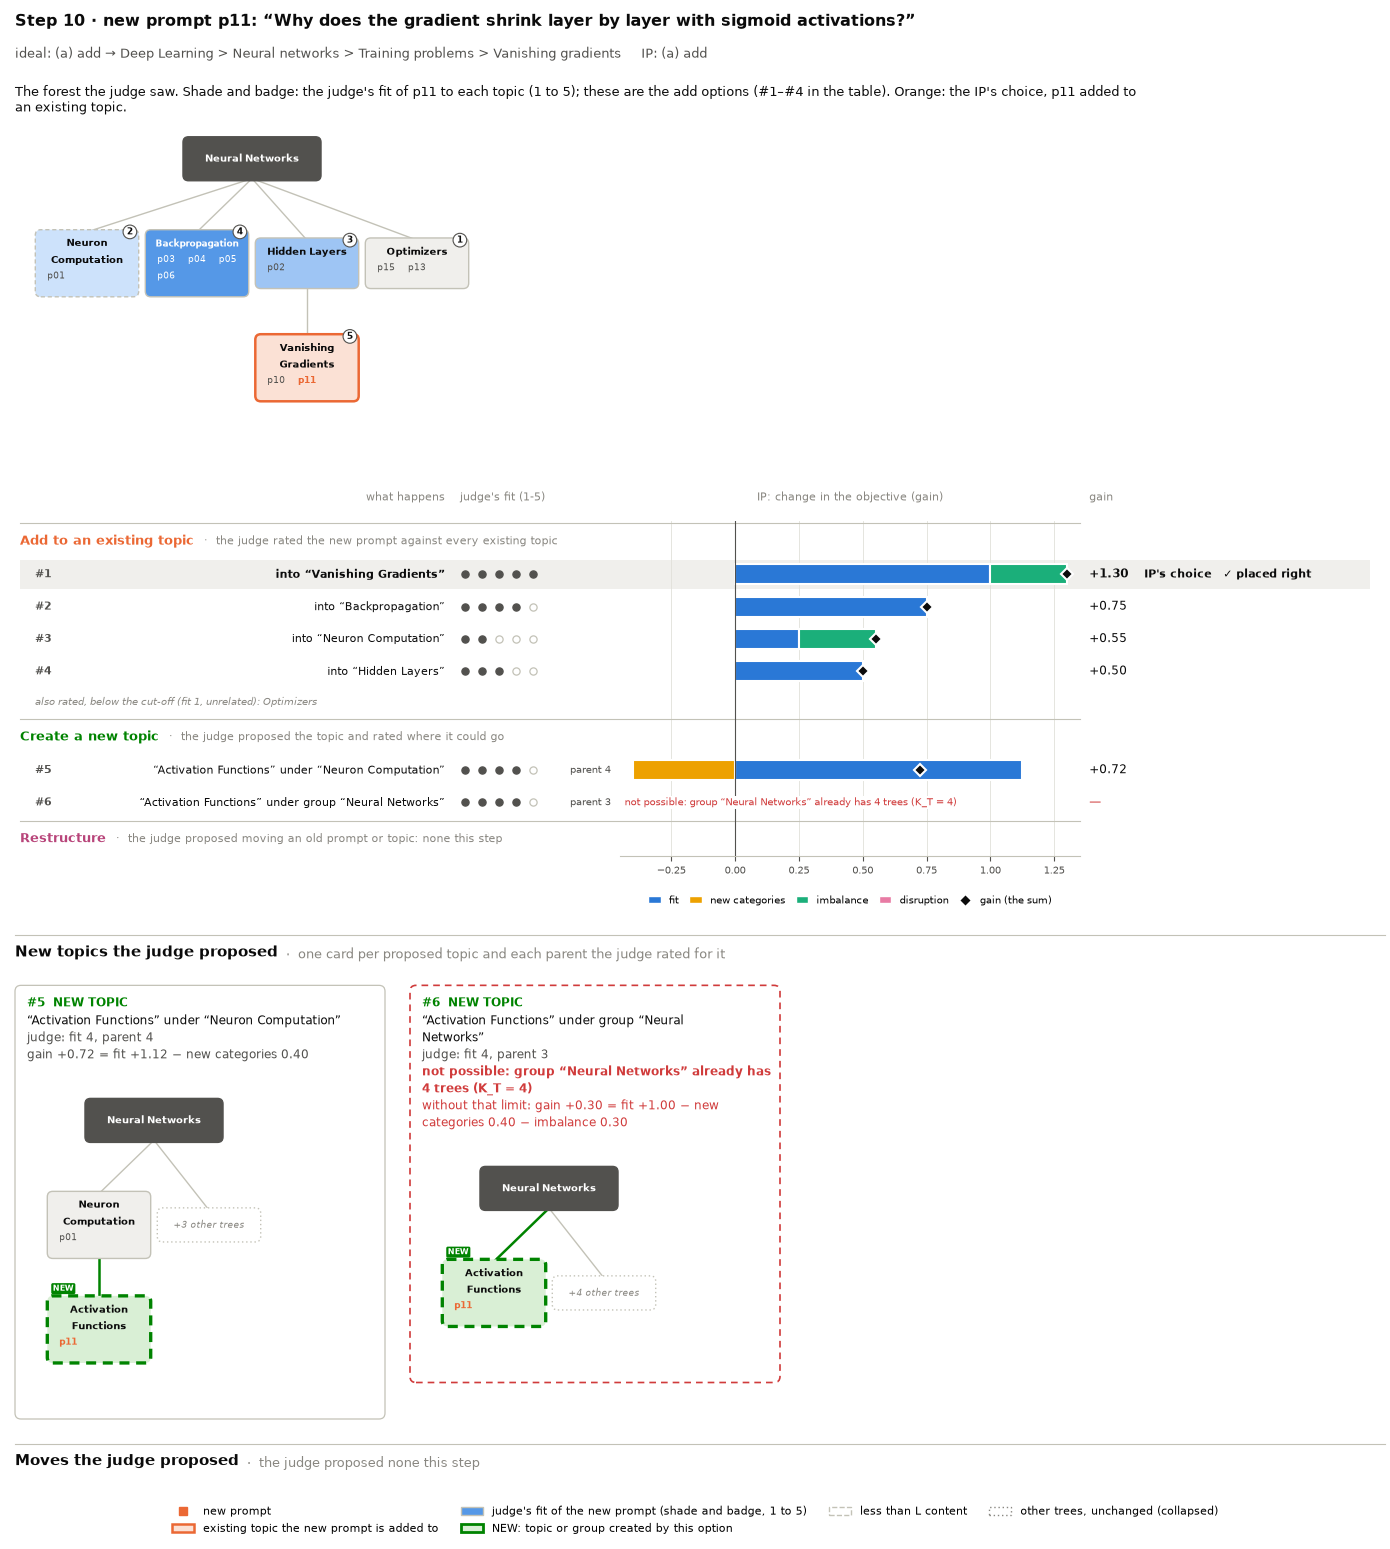

#### Step 11 of 25

| | |
|---|---|
| **input** | new prompt **p21**: “How do I find the eigenvalues of a 2x2 matrix?”<br>forest before: 1 group, 4 trees, 5 topics, 10 prompts |
| **judge** | fits: Neuron Computation (2), Vanishing Gradients (2), Backpropagation (2); 2 more at (1)<br>proposes: new topic “Eigenvalues” (fit 5) under new group “Linear Algebra” (parent fit 4)<br>moves: none |
| **output (IP)** | (a) add: p21 → Neural Networks > Neuron Computation, with p01 ✗<br>rejected proposals: “Eigenvalues”<br>objective: fit +10.88, new categories +0.00, imbalance +0.00, disruption +0.00 → total 10.88 |
| **ideal** | (d) new group: p21 → Linear Algebra > Eigenvalues, alone<br>why: first linear algebra prompt, mid-session: a new group |
| **judge_argmax** | (d) new group: p21 → Linear Algebra > Eigenvalues (new), alone ✓ |
| **chronological** | (c) new tree: p21 → Chat history > Prompts 11-15 (new), alone ✓ |

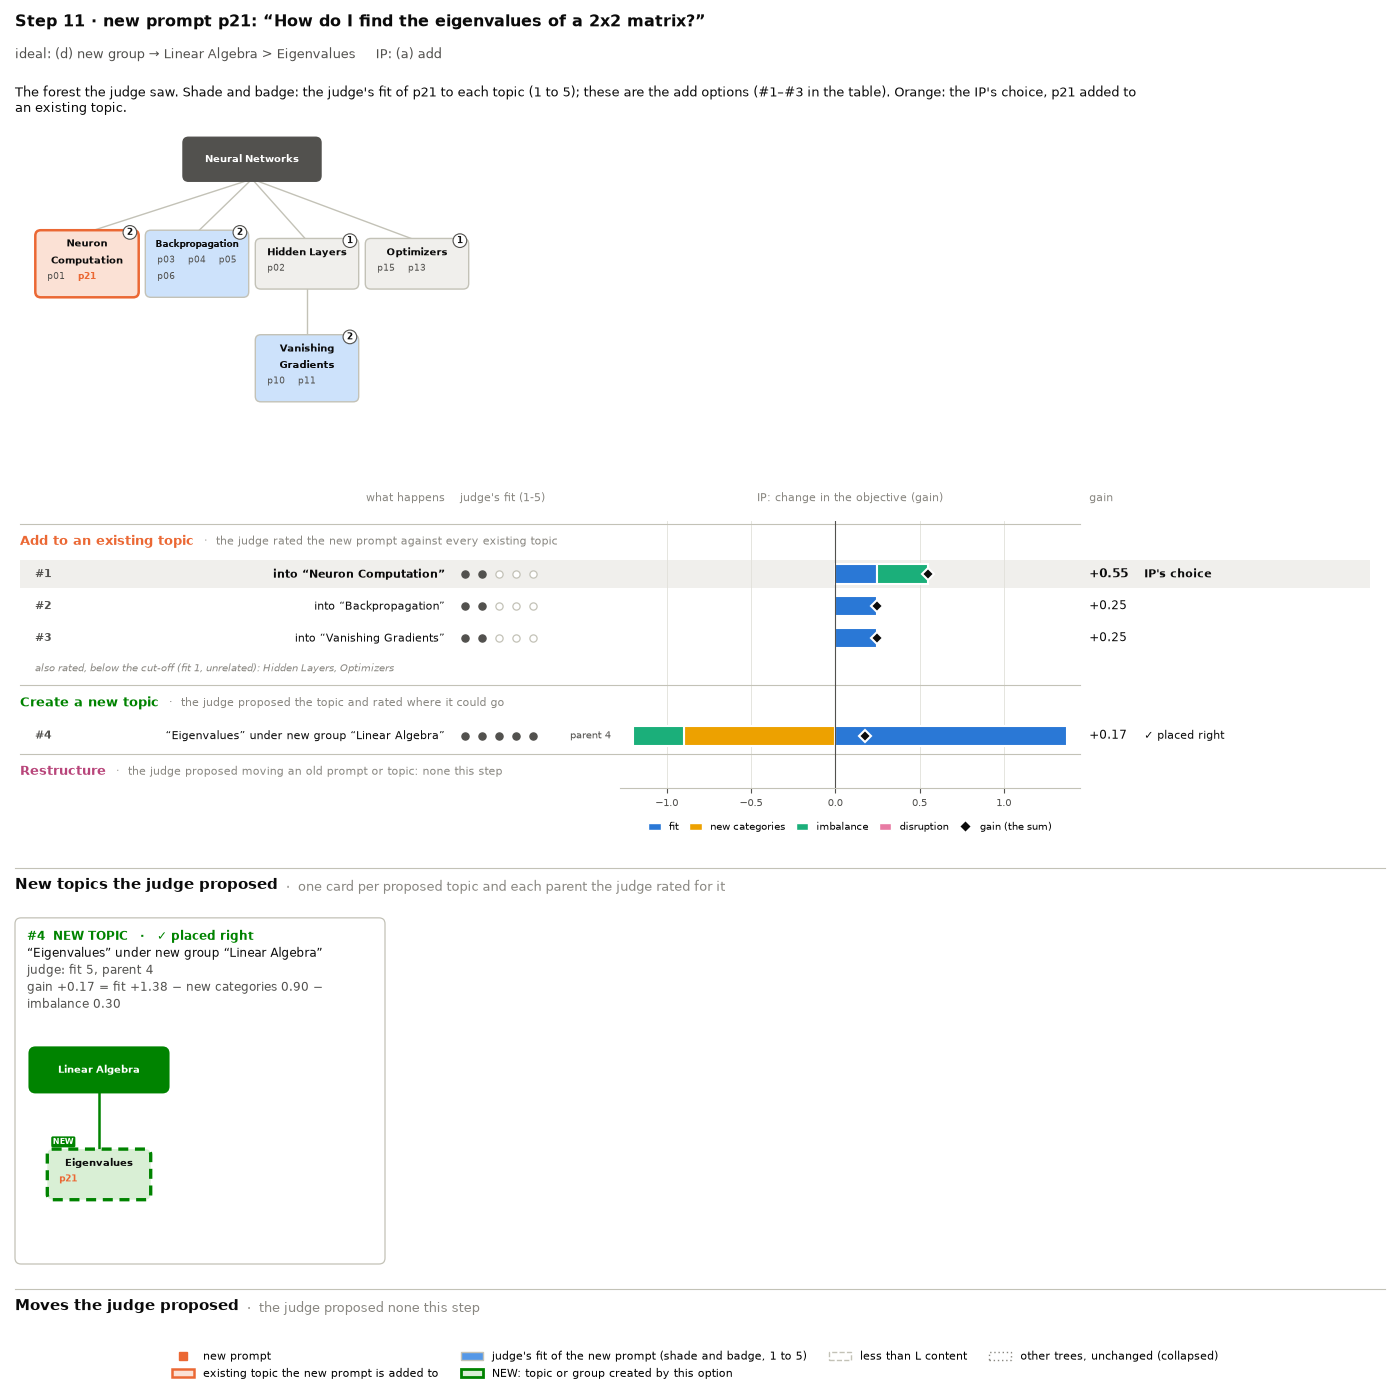

#### Step 12 of 25

| | |
|---|---|
| **input** | new prompt **p14**: “How does dropout reduce overfitting?”<br>forest before: 1 group, 4 trees, 5 topics, 11 prompts |
| **judge** | fits: Optimizers (2), Backpropagation (2), Hidden Layers (2); 2 more at (1)<br>proposes: new topic “Regularization” (fit 4) under Neural Networks (group) (parent fit 5); new topic “Dropout” (fit 5) under “Regularization” (proposed) (parent fit 5)<br>moves: p13 → “Regularization” (proposed) (4) |
| **output (IP)** | (a) add: p14 → Neural Networks > Optimizers, with p15, p13 ✗<br>rejected moves: p13 → “Regularization” (proposed)<br>rejected proposals: “Regularization”, “Dropout”<br>objective: fit +11.12, new categories +0.00, imbalance +0.00, disruption +0.00 → total 11.12 |
| **ideal** | (a) add: p14 → Deep Learning > Neural networks > Training problems > Overfitting, with p13<br>why: overfitting |
| **judge_argmax** | (b) new branch: p14 → Neural Networks > Overfitting > Dropout (new), alone ✗ |
| **chronological** | (a) add: p14 → Chat history > Prompts 11-15, with p21 ✗ |

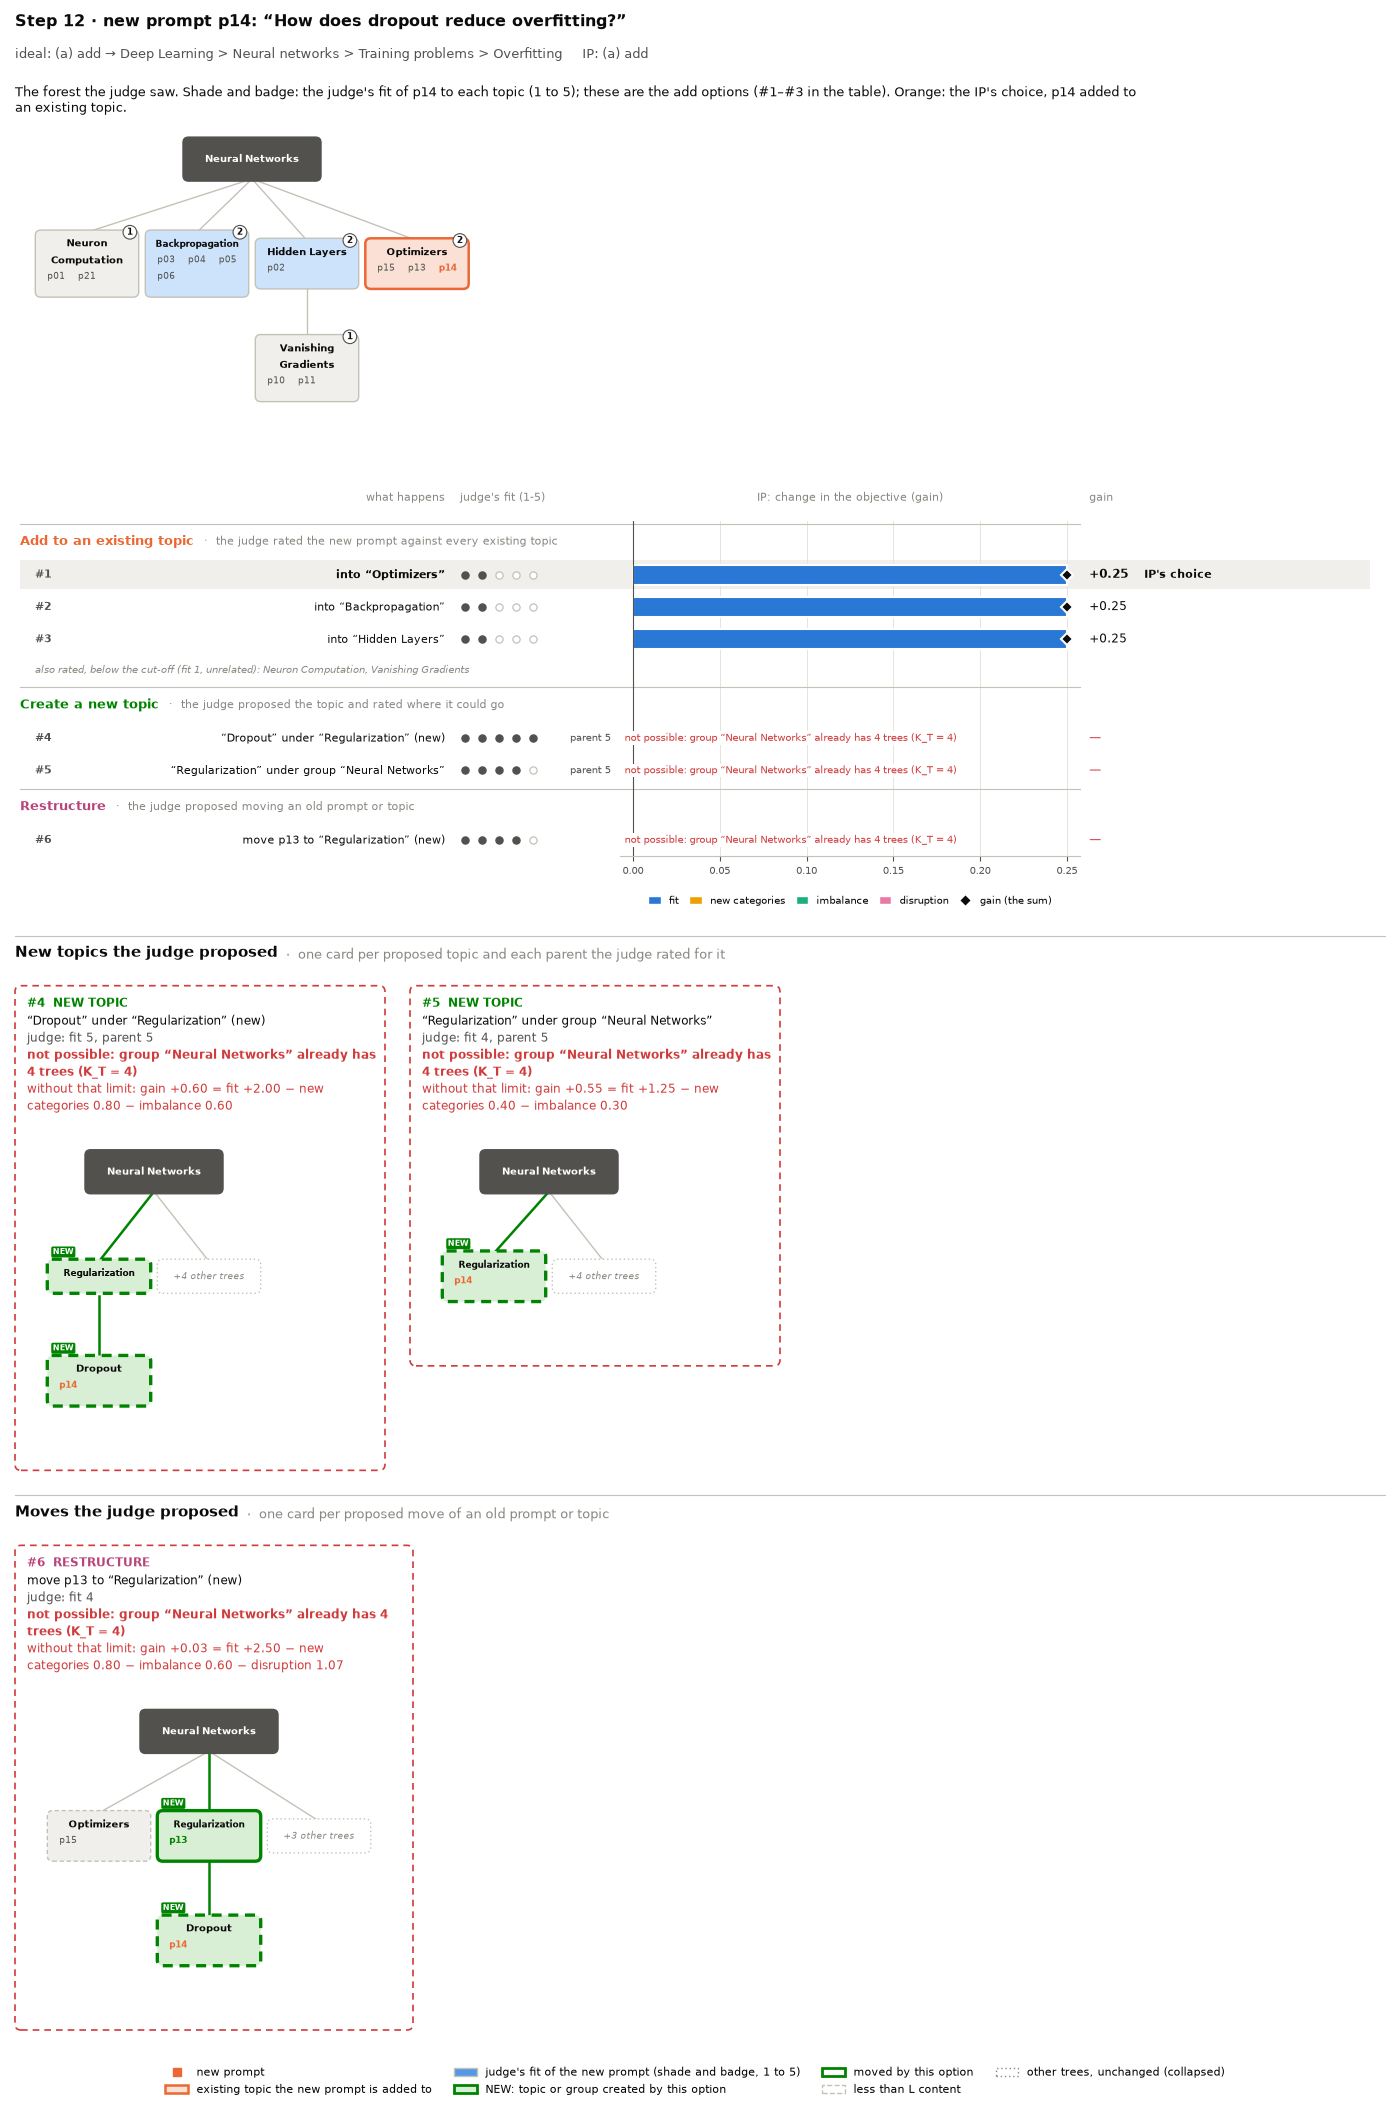

#### Step 13 of 25

| | |
|---|---|
| **input** | new prompt **p09**: “What usually goes wrong when training a deep network, and how do I tell which problem I have?”<br>forest before: 1 group, 4 trees, 5 topics, 12 prompts |
| **judge** | fits: Backpropagation (3), Optimizers (3), Vanishing Gradients (3), Neuron Computation (2), Hidden Layers (2)<br>proposes: new topic “Training Failure Modes” (fit 5) under Neural Networks (group) (parent fit 4) or Optimizers (parent fit 2)<br>moves: p13 → “Training Failure Modes” (proposed) (4); topic Vanishing Gradients → “Training Failure Modes” (proposed) (3) |
| **output (IP)** | (a) add: p09 → Neural Networks > Backpropagation, with p03, p04, p05, p06 ✗<br>rejected moves: p13 → “Training Failure Modes” (proposed); topic Vanishing Gradients → “Training Failure Modes” (proposed)<br>rejected proposals: “Training Failure Modes”<br>objective: fit +11.62, new categories +0.00, imbalance +0.00, disruption +0.00 → total 11.62 |
| **ideal** | (e) restructure: p09 → Deep Learning > Neural networks > Training problems, alone<br>why: Training problems becomes obvious: insert it above vanishing gradients and overfitting |
| **judge_argmax** | (c) new tree: p09 → Neural Networks > Training Failure Modes (new), alone ✓ |
| **chronological** | (a) add: p09 → Chat history > Prompts 11-15, with p21, p14 ✗ |

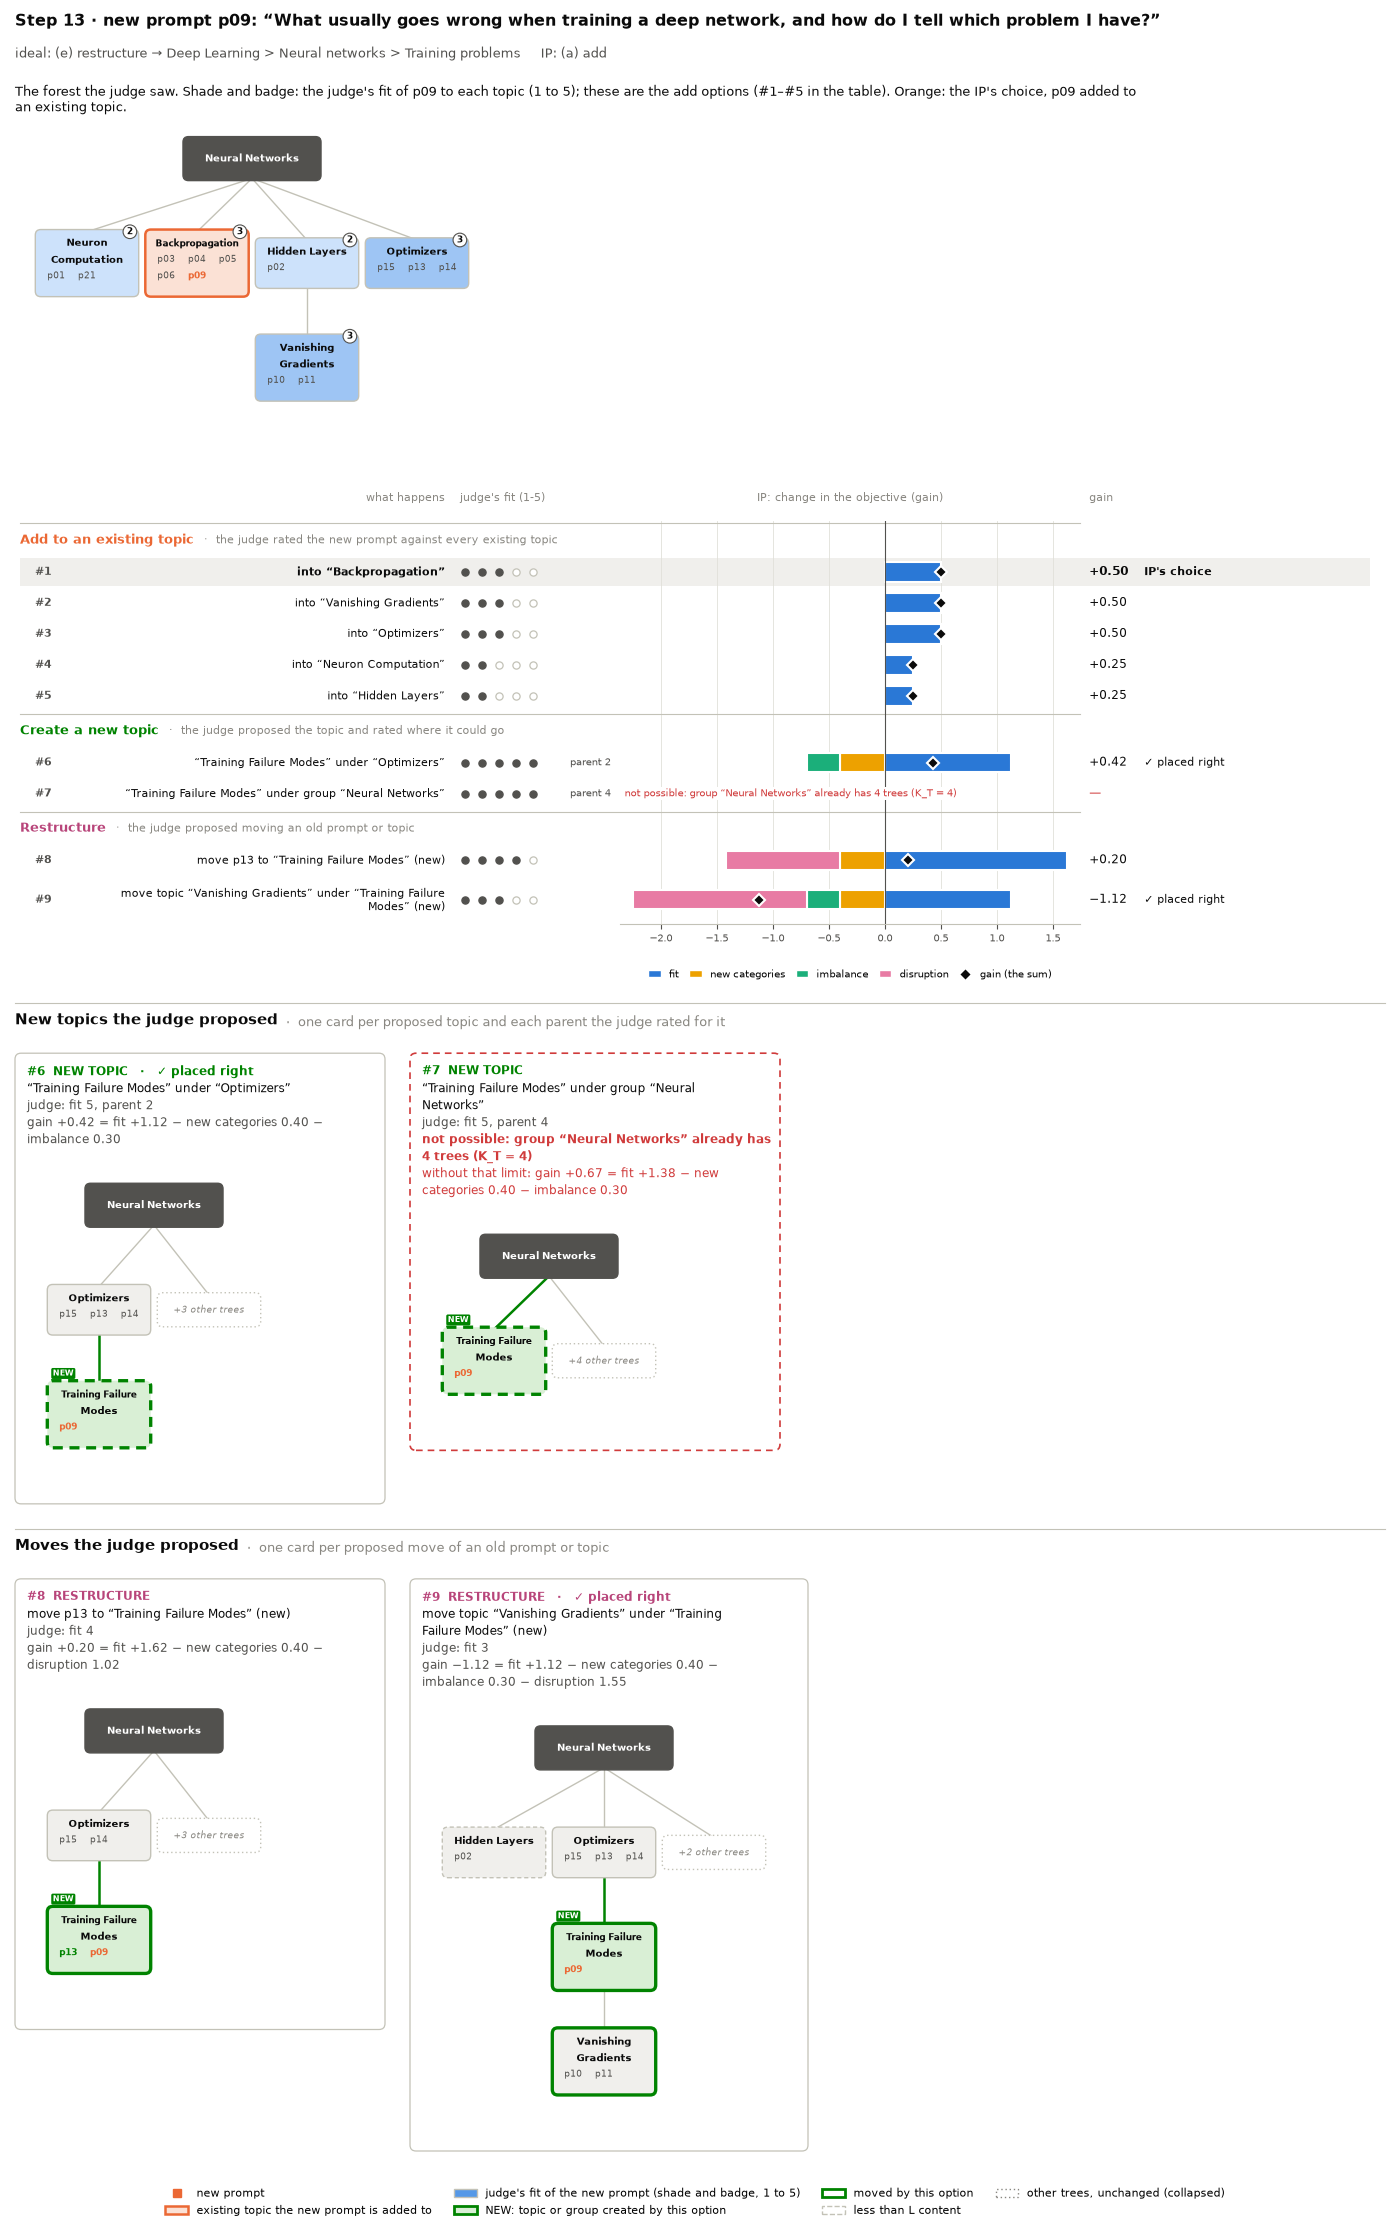

#### Step 14 of 25

| | |
|---|---|
| **input** | new prompt **p16**: “What does momentum add to plain SGD?”<br>forest before: 1 group, 4 trees, 5 topics, 13 prompts |
| **judge** | fits: Optimizers (5), Backpropagation (2), Vanishing Gradients (2); 2 more at (1)<br>proposes: new topic “Momentum” (fit 5) under Optimizers (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p16 → Neural Networks > Optimizers, with p15, p13, p14 ✗<br>rejected proposals: “Momentum”<br>objective: fit +12.62, new categories +0.00, imbalance +0.00, disruption +0.00 → total 12.62 |
| **ideal** | (a) add: p16 → Deep Learning > Optimizers > Adam vs SGD, with p15 |
| **judge_argmax** | (b) new branch: p16 → Neural Networks > Gradient Descent Optimizers > Momentum (new), alone ✗ |
| **chronological** | (a) add: p16 → Chat history > Prompts 11-15, with p21, p14, p09 ✗ |

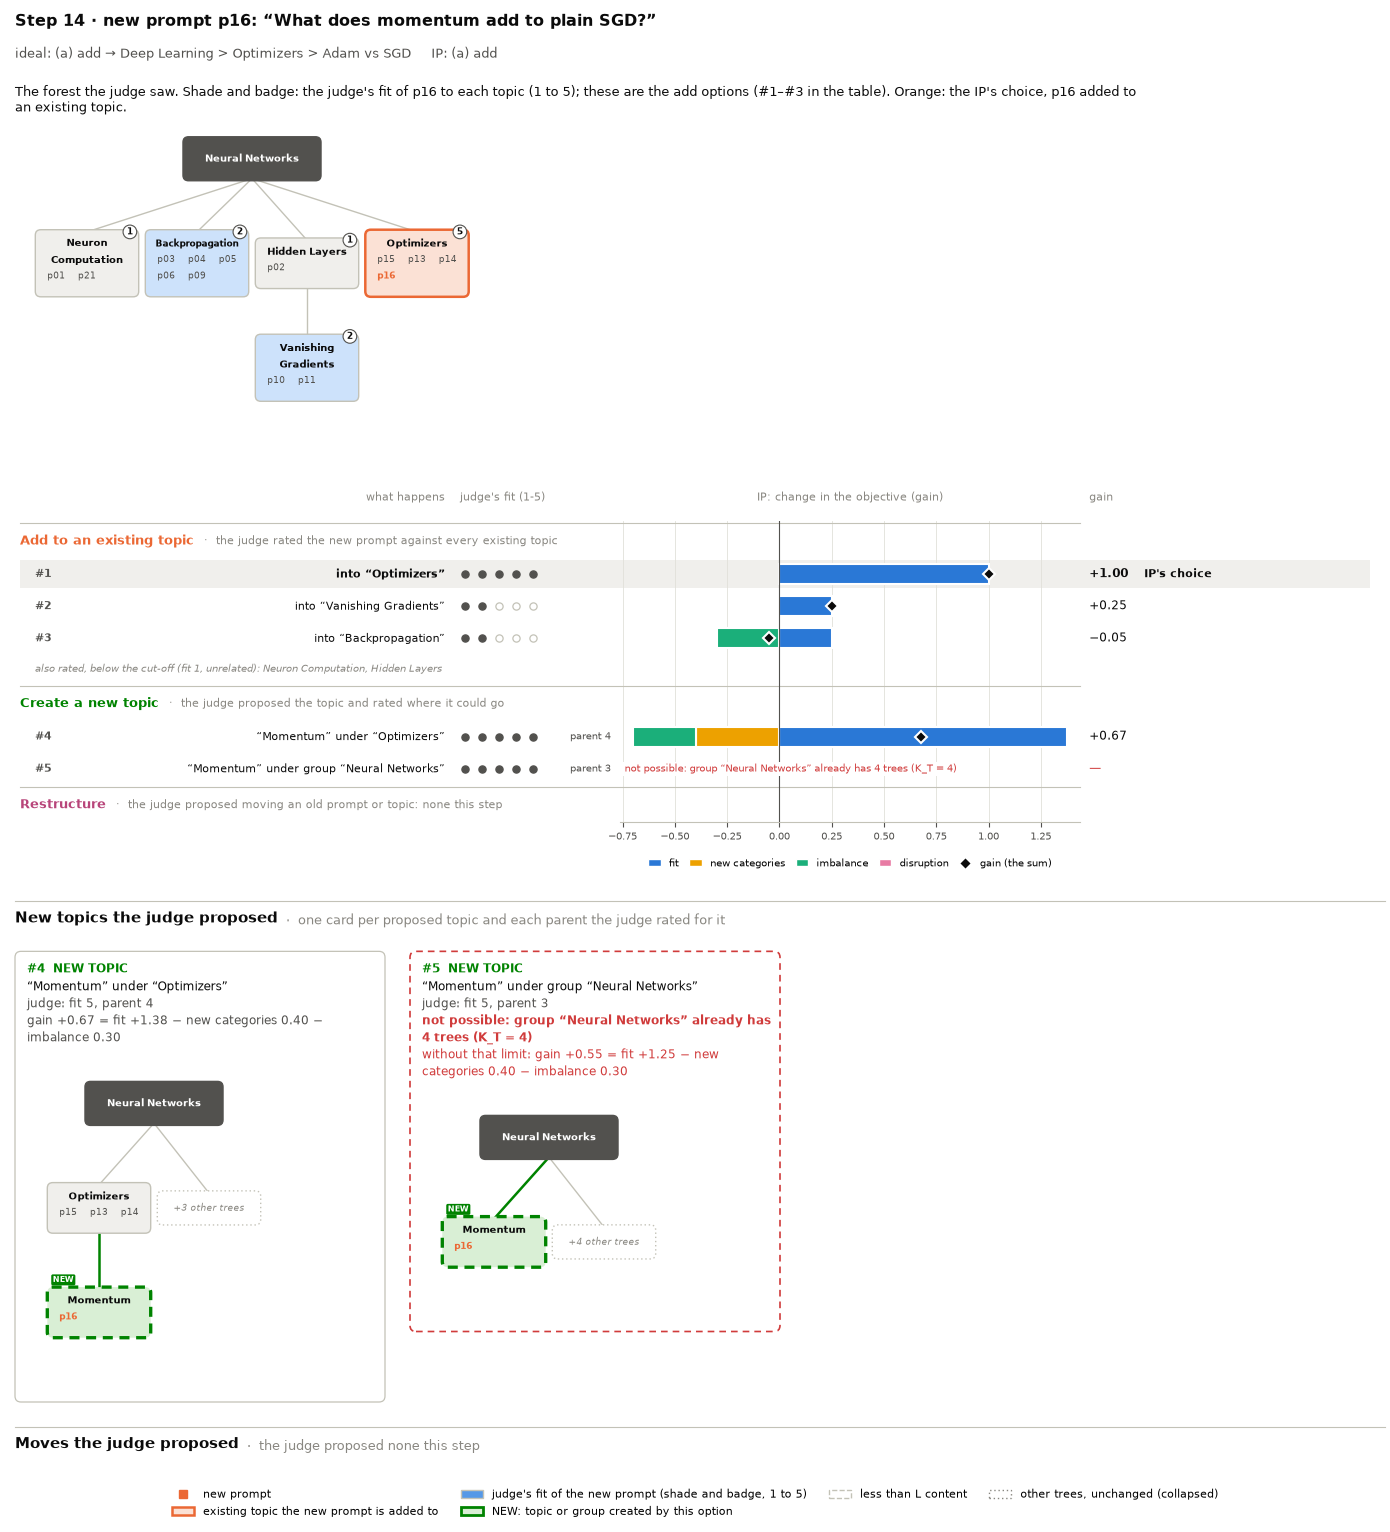

#### Step 15 of 25

| | |
|---|---|
| **input** | new prompt **p18**: “My loss explodes with learning rate 0.1 and barely moves with 0.001. How do I pick it?”<br>forest before: 1 group, 4 trees, 5 topics, 14 prompts |
| **judge** | fits: Optimizers (4), Vanishing Gradients (2), Backpropagation (2); 2 more at (1)<br>proposes: new topic “Learning Rate Tuning” (fit 5) under Optimizers (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p18 → Neural Networks > Optimizers, with p15, p13, p14, p16 ✗<br>rejected proposals: “Learning Rate Tuning”<br>objective: fit +13.38, new categories +0.00, imbalance +0.00, disruption +0.00 → total 13.38 |
| **ideal** | (a) add: p18 → Deep Learning > Optimizers > Learning rate, alone<br>why: learning rate goes into the optimizer topic for now |
| **judge_argmax** | (b) new branch: p18 → Neural Networks > Gradient Descent Optimizers > Learning Rate (new), alone ✓ |
| **chronological** | (a) add: p18 → Chat history > Prompts 11-15, with p21, p14, p09, p16 ✗ |

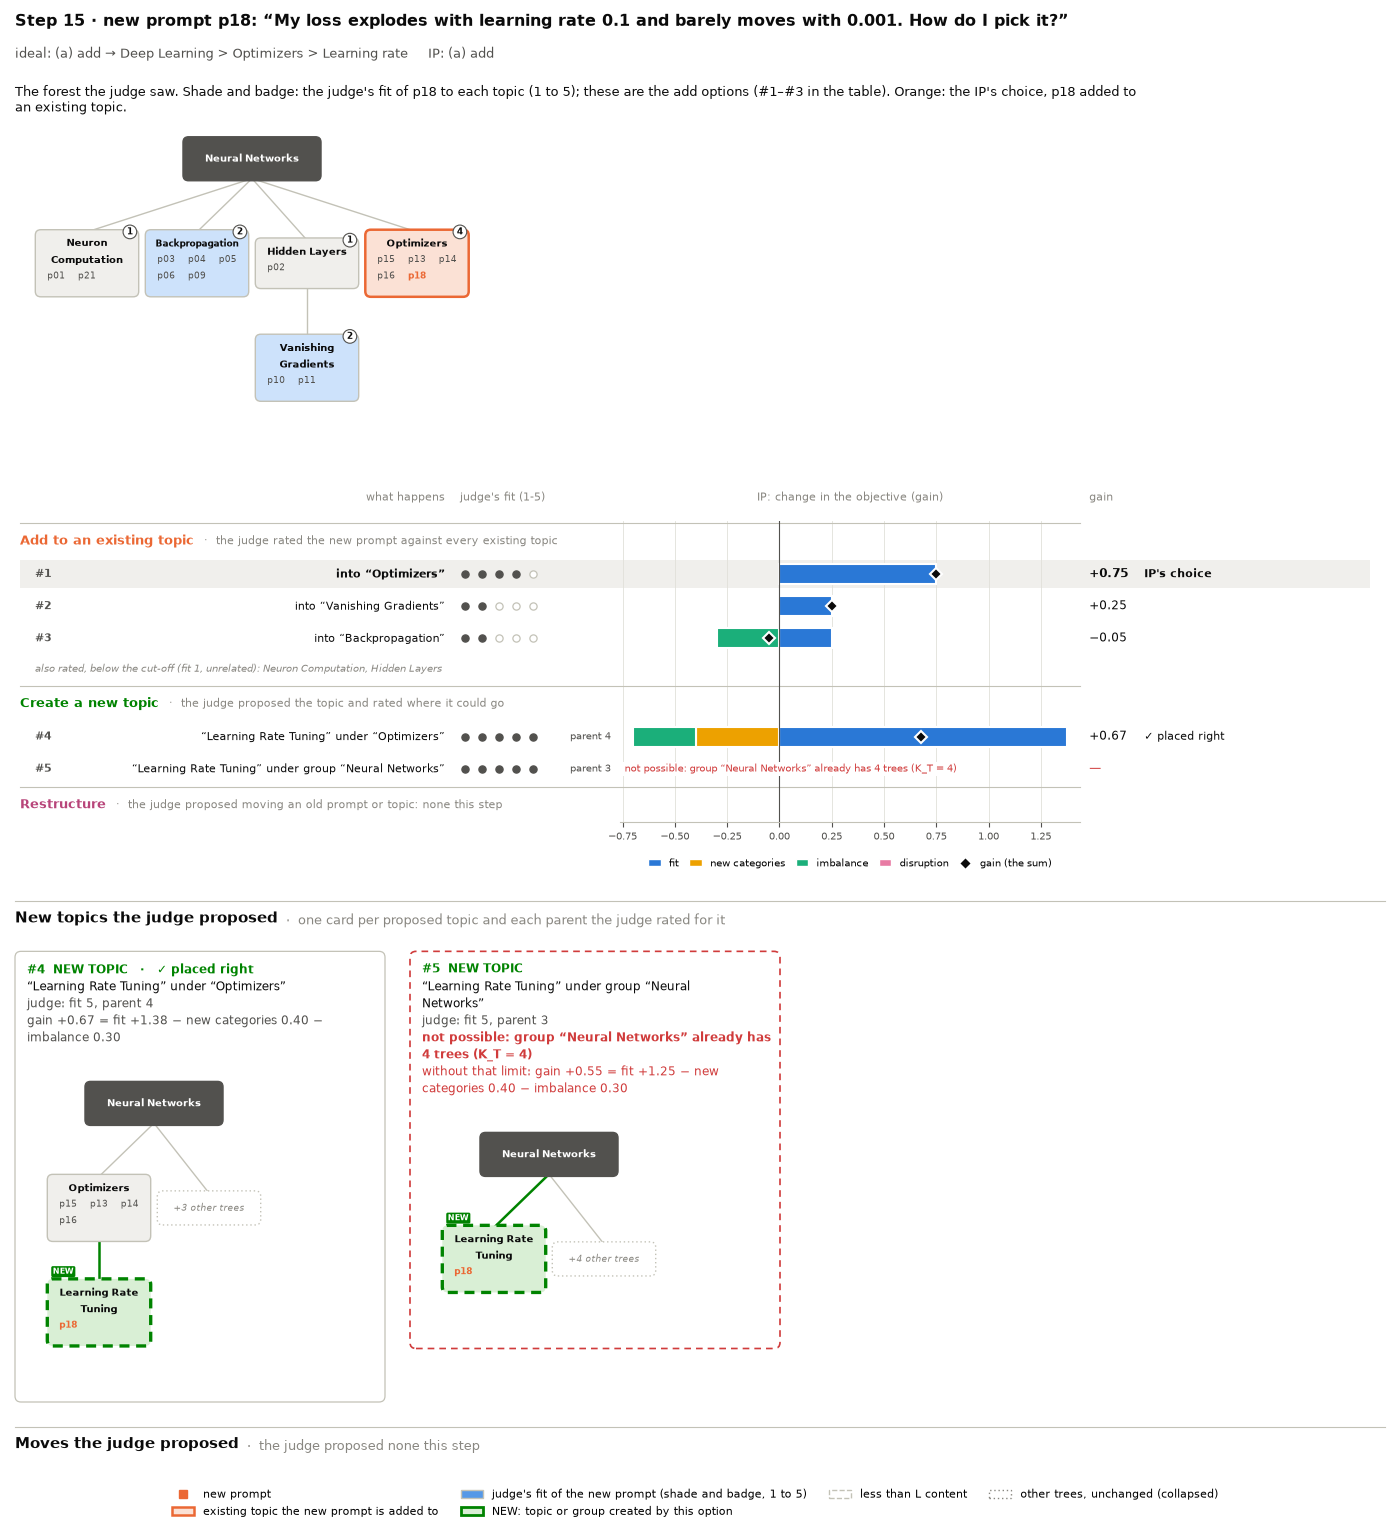

#### Step 16 of 25

| | |
|---|---|
| **input** | new prompt **p07**: “Should the bias gradient be summed or averaged over the batch?”<br>forest before: 1 group, 4 trees, 5 topics, 15 prompts |
| **judge** | fits: Backpropagation (4), Optimizers (3), Neuron Computation (2); 2 more at (1)<br>proposes: new topic “Batch Gradient Aggregation” (fit 5) under Backpropagation (parent fit 4) or Optimizers (parent fit 3) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (b) new branch: p07 → Neural Networks > Backpropagation > Batch Gradient Aggregation (new), alone ✗<br>objective: fit +14.75, new categories -0.40, imbalance -0.30, disruption +0.00 → total 14.05 |
| **ideal** | (a) add: p07 → Deep Learning > Neural networks > Backpropagation, with p03, p04, p05, p06 |
| **judge_argmax** | (b) new branch: p07 → Neural Networks > Backpropagation > MLP Weight Gradients > Bias Gradients (new), alone ✗ |
| **chronological** | (c) new tree: p07 → Chat history > Prompts 16-20 (new), alone ✗ |

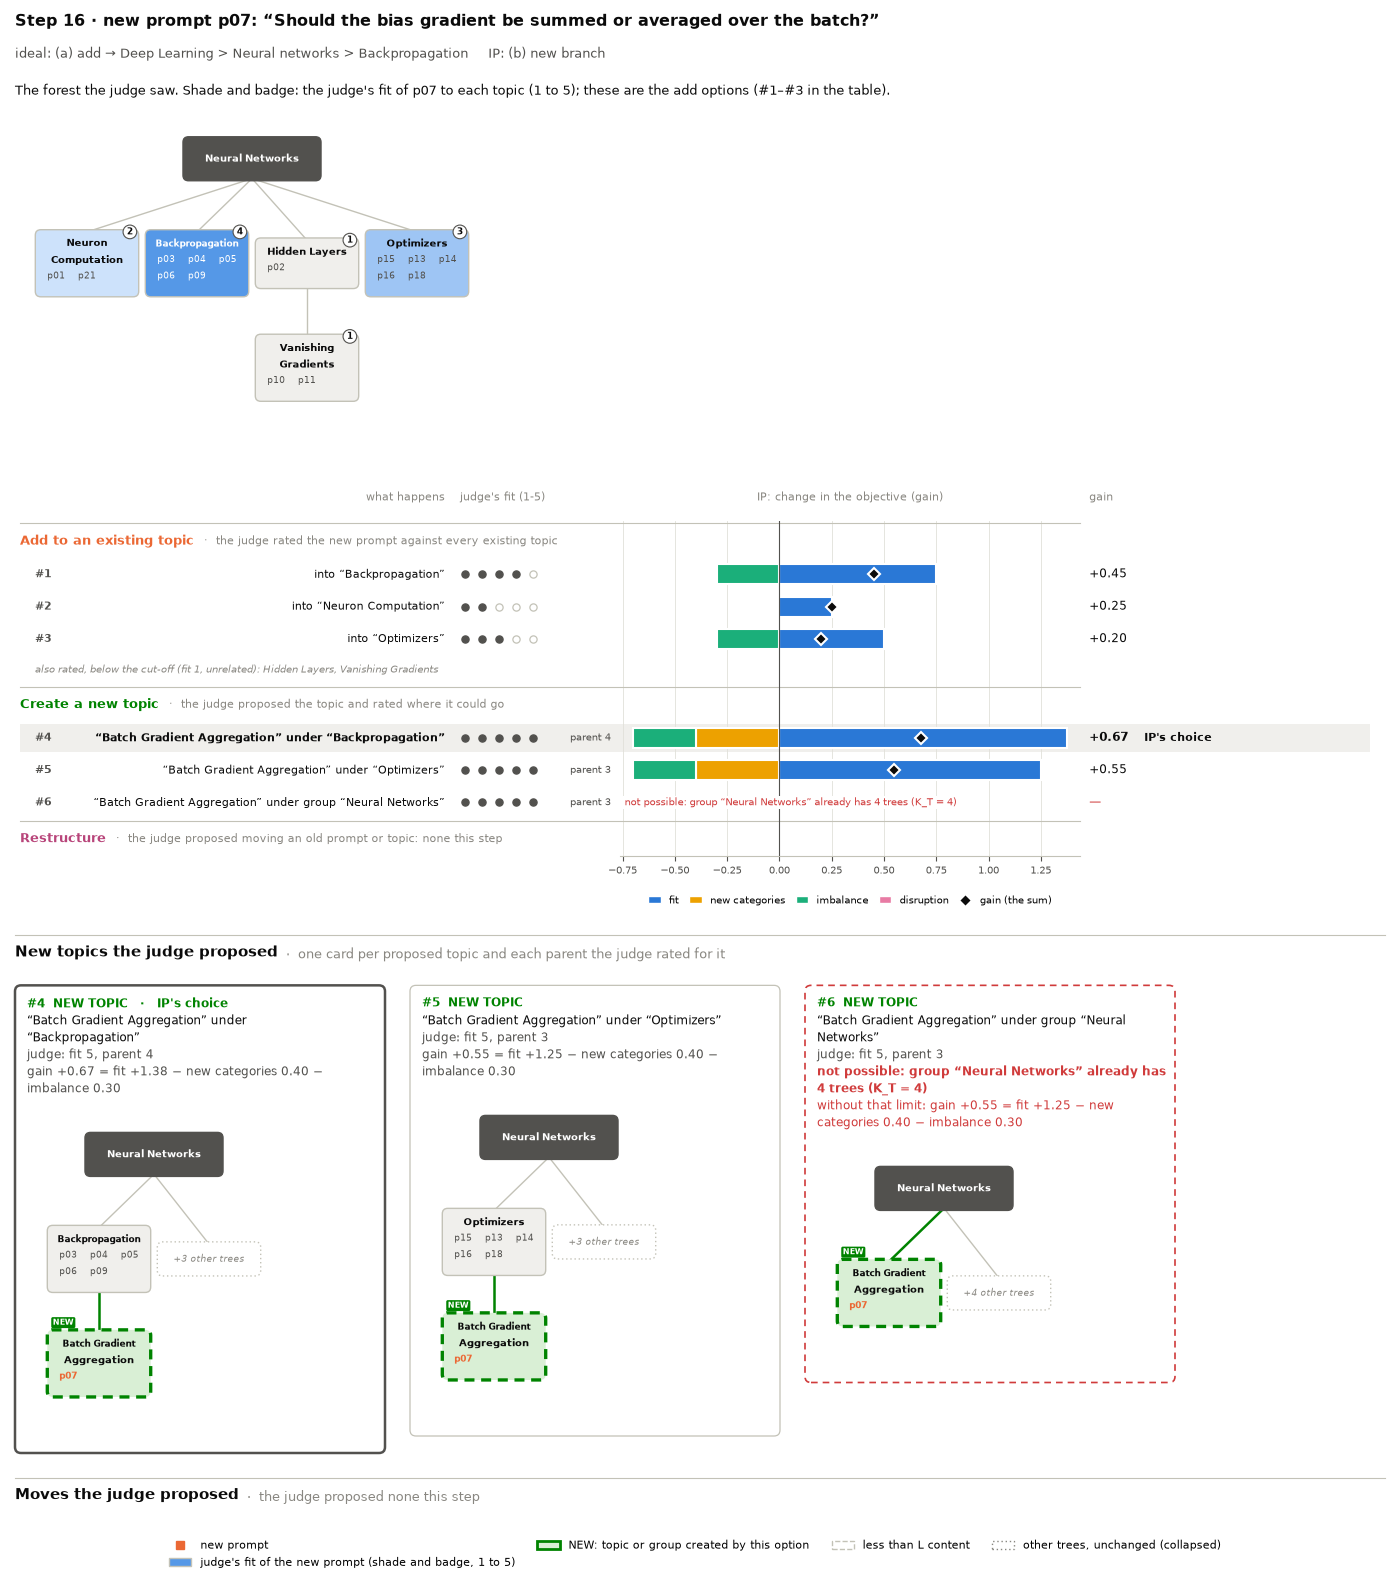

#### Step 17 of 25

| | |
|---|---|
| **input** | new prompt **p22**: “What does it mean geometrically that a vector is an eigenvector?”<br>forest before: 1 group, 4 trees, 6 topics, 16 prompts |
| **judge** | fits: all 6 at (1)<br>proposes: new topic “Eigenvectors” (fit 5) under new group “Linear Algebra” (parent fit 5) or Neural Networks (group) (parent fit 1); new topic “Eigenvalues” (fit 2) under “Eigenvectors” (proposed) (parent fit 4) or new group “Linear Algebra” (parent fit 4) or Neural Networks (group) (parent fit 1)<br>moves: p21 → “Eigenvalues” (proposed) (5) |
| **output (IP)** | (d) new group: p22 → Linear Algebra > Eigenvectors (new), alone ✗<br>rejected moves: p21 → “Eigenvalues” (proposed)<br>rejected proposals: “Eigenvalues”<br>objective: fit +16.25, new categories -0.90, imbalance -0.60, disruption +0.00 → total 14.75 |
| **ideal** | (a) add: p22 → Linear Algebra > Eigenvalues, with p21 |
| **judge_argmax** | (b) new branch: p22 → Linear Algebra > Eigenvalues > Eigenvector Geometry (new), alone ✗ |
| **chronological** | (a) add: p22 → Chat history > Prompts 16-20, with p07 ✗ |

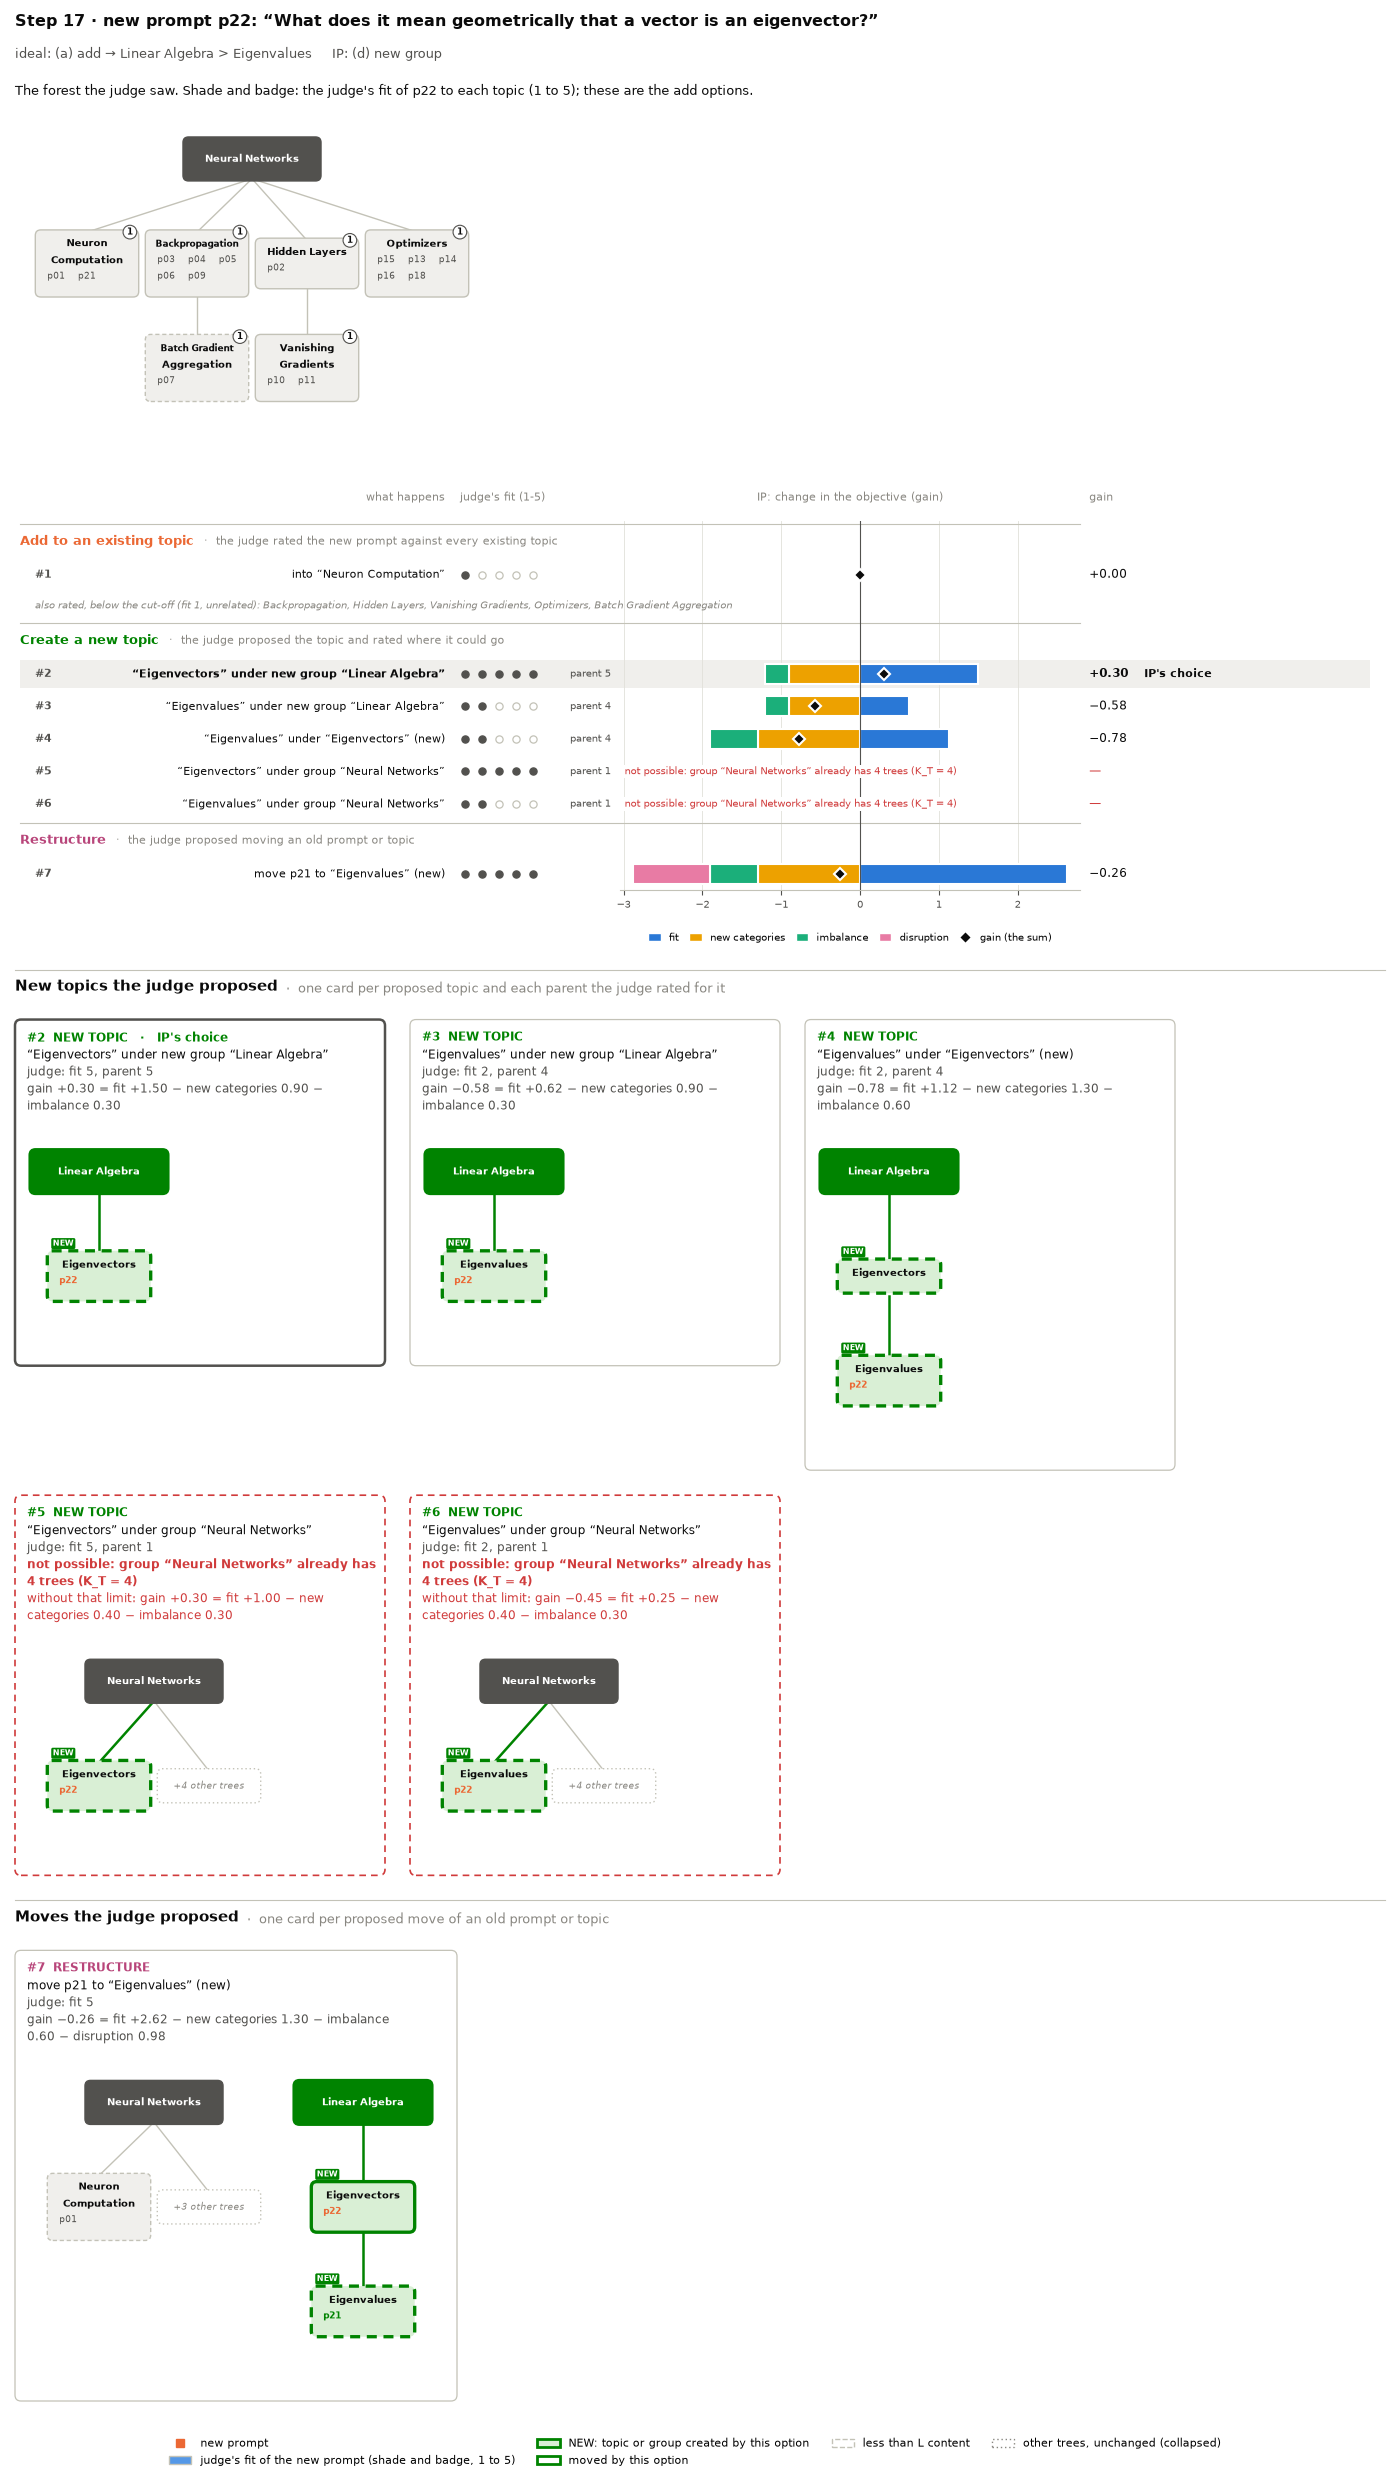

#### Step 18 of 25

| | |
|---|---|
| **input** | new prompt **p19**: “Is a cosine learning rate schedule better than step decay?”<br>forest before: 2 groups, 5 trees, 7 topics, 17 prompts |
| **judge** | fits: Optimizers (4), Backpropagation (2), Vanishing Gradients (2); 4 more at (1)<br>proposes: new topic “Learning Rate Schedules” (fit 5) under Optimizers (parent fit 4) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (b) new branch: p19 → Neural Networks > Optimizers > Learning Rate Schedules (new), alone ✗<br>objective: fit +17.62, new categories -0.40, imbalance -0.90, disruption +0.00 → total 16.32 |
| **ideal** | (a) add: p19 → Deep Learning > Optimizers > Learning rate, with p18<br>why: a second learning-rate prompt: the optimizer topic fills up |
| **judge_argmax** | (b) new branch: p19 → Neural Networks > Gradient Descent Optimizers > Learning Rate > Learning Rate Schedules (new), alone ✗ |
| **chronological** | (a) add: p19 → Chat history > Prompts 16-20, with p07, p22 ✗ |

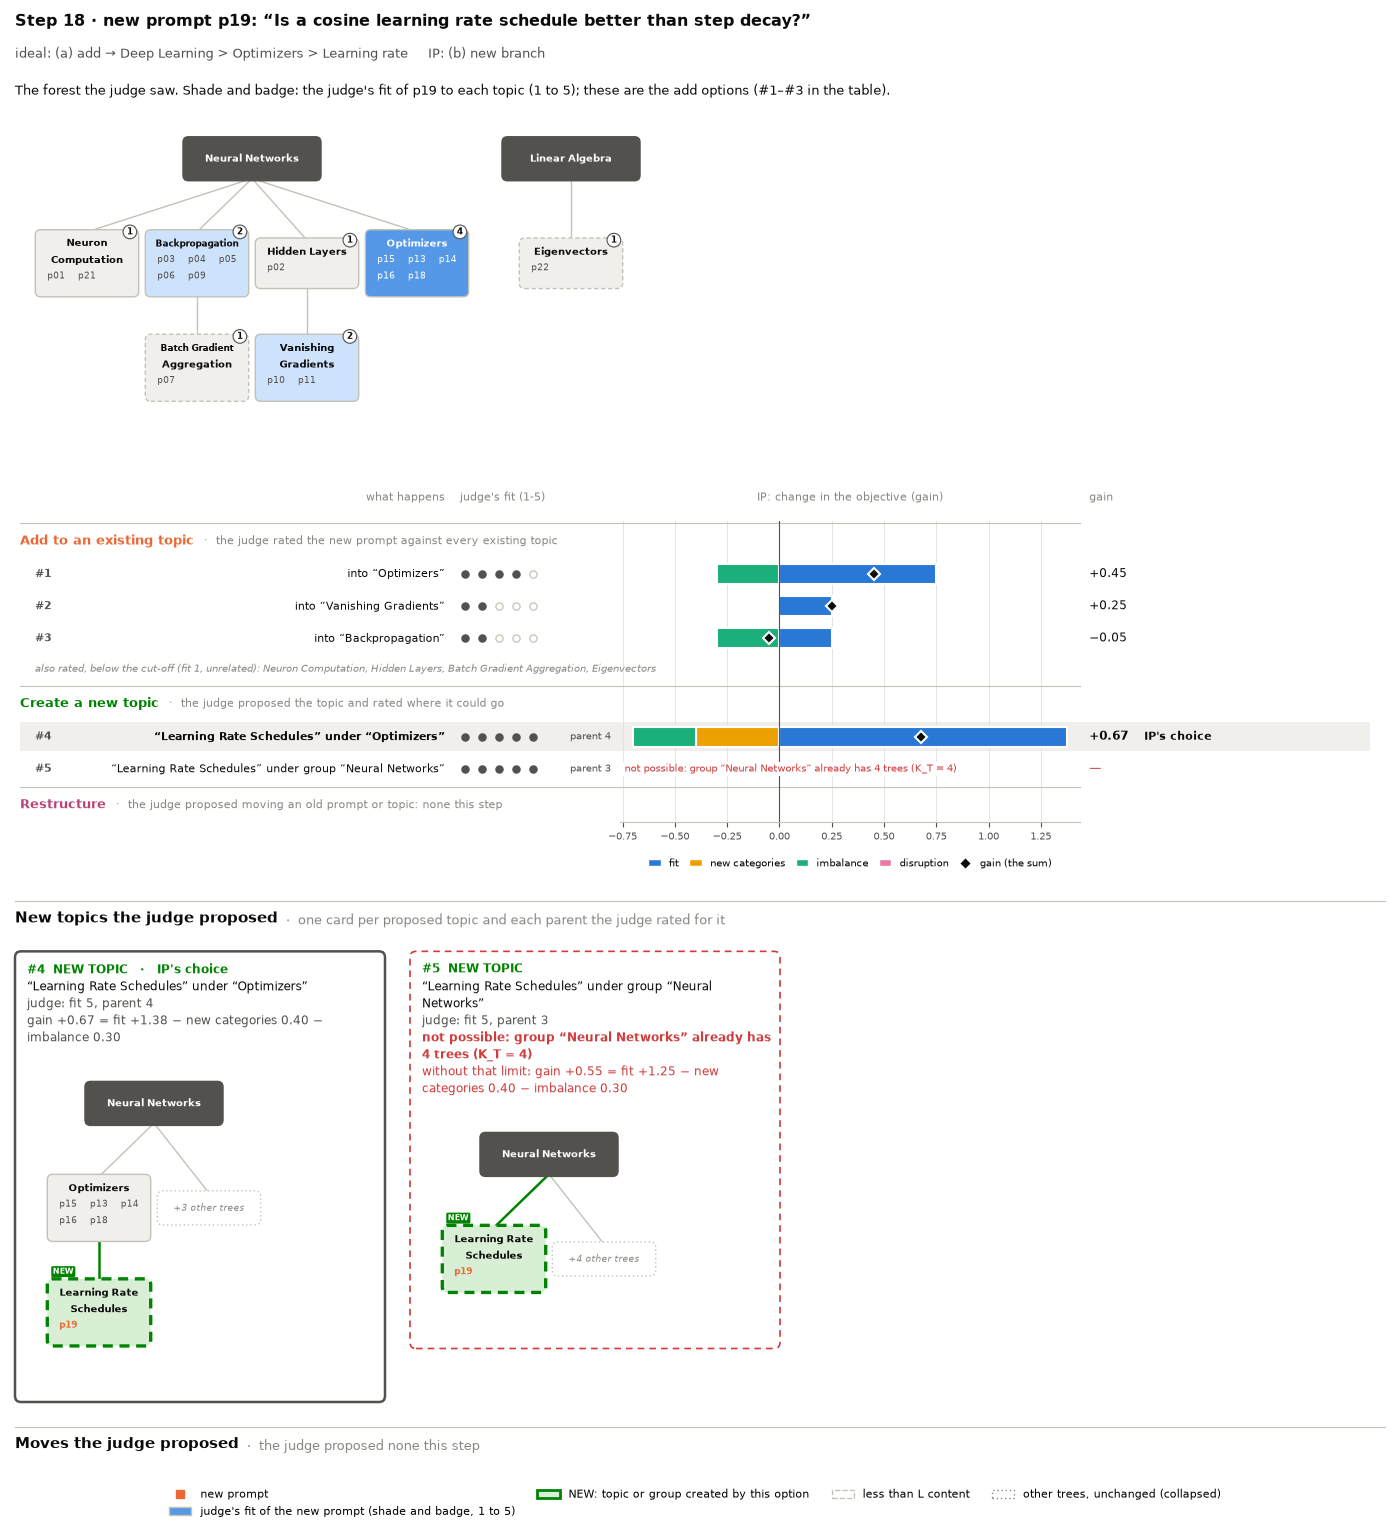

#### Step 19 of 25

| | |
|---|---|
| **input** | new prompt **p17**: “Why does Adam need a bias correction in the first steps?”<br>forest before: 2 groups, 5 trees, 8 topics, 18 prompts |
| **judge** | fits: Optimizers (4), Learning Rate Schedules (2); 6 more at (1)<br>proposes: new topic “Adam Optimizer” (fit 5) under Optimizers (parent fit 5) or Neural Networks (group) (parent fit 3)<br>moves: p21 → Eigenvectors (4) |
| **output (IP)** | (b) new branch: p17 → Neural Networks > Optimizers > Adam Optimizer (new), alone ✗<br>rejected moves: p21 → Eigenvectors<br>objective: fit +19.12, new categories -0.40, imbalance -1.20, disruption +0.00 → total 17.52 |
| **ideal** | (a) add: p17 → Deep Learning > Optimizers > Adam vs SGD, with p15, p16 |
| **judge_argmax** | (b) new branch: p17 → Neural Networks > Gradient Descent Optimizers > Adam Optimizer > Adam Bias Correction (new), alone ✗ |
| **chronological** | (a) add: p17 → Chat history > Prompts 16-20, with p07, p22, p19 ✗ |

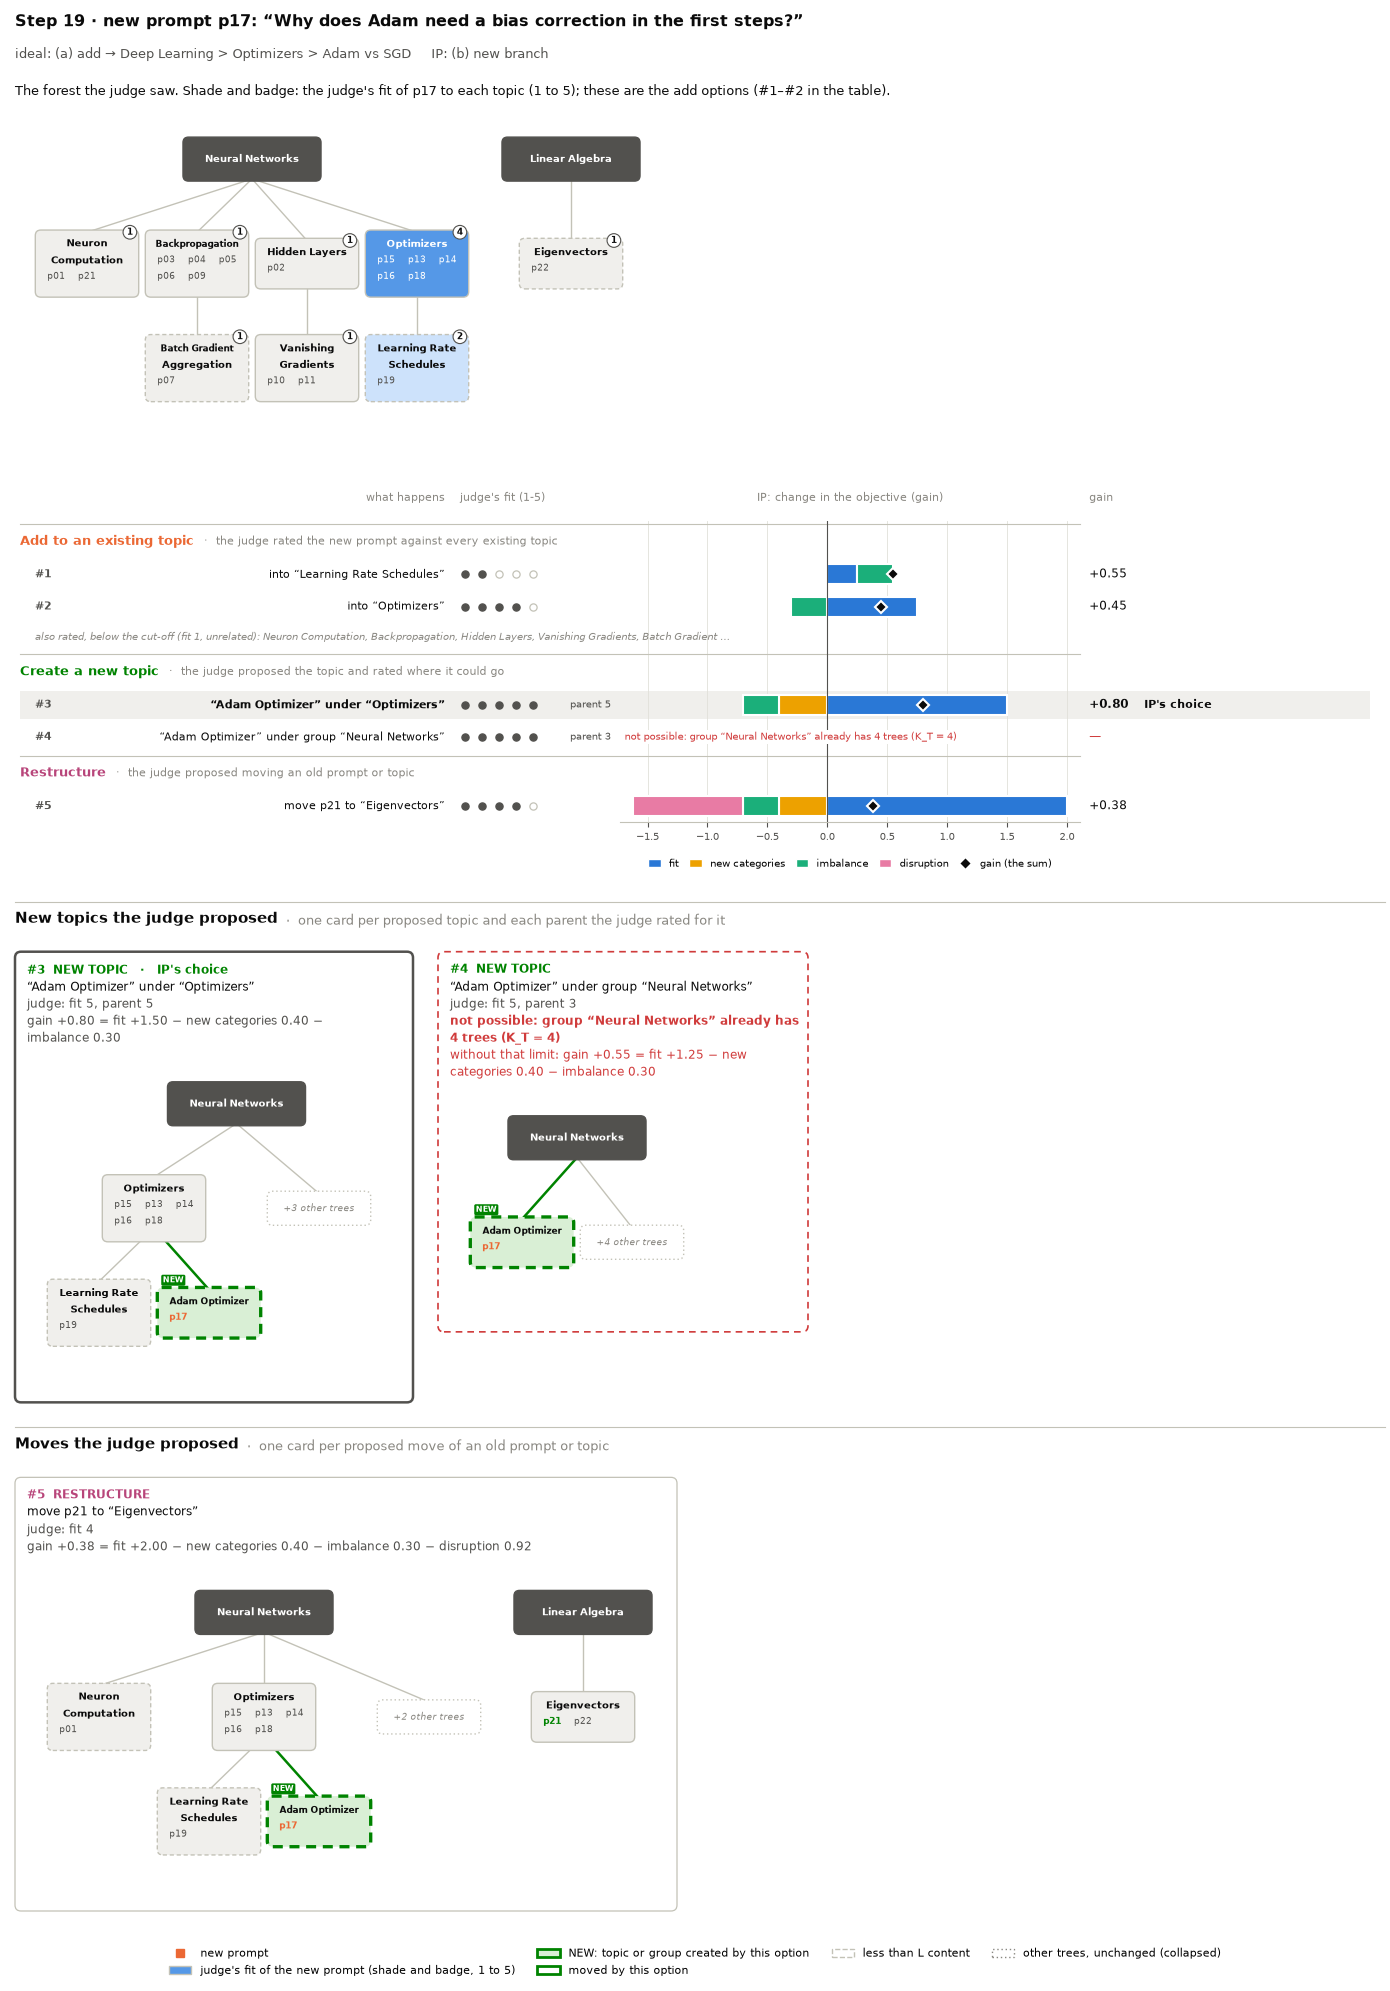

#### Step 20 of 25

| | |
|---|---|
| **input** | new prompt **p20**: “Why do people use a learning rate warmup?”<br>forest before: 2 groups, 5 trees, 9 topics, 19 prompts |
| **judge** | fits: Learning Rate Schedules (5), Optimizers (4), Adam Optimizer (3), Vanishing Gradients (2), Backpropagation (2); 4 more at (1)<br>proposes: nothing<br>moves: none |
| **output (IP)** | (a) add: p20 → Neural Networks > Optimizers > Learning Rate Schedules, with p19 ✗<br>objective: fit +20.12, new categories +0.00, imbalance -0.90, disruption +0.00 → total 19.22 |
| **ideal** | (e) restructure: p20 → Deep Learning > Optimizers > Learning rate, with p18, p19<br>why: the optimizer topic is overloaded: split Learning rate off and move the earlier prompts |
| **judge_argmax** | (b) new branch: p20 → Neural Networks > Gradient Descent Optimizers > Learning Rate > Learning Rate Warmup (new), alone ✗ |
| **chronological** | (a) add: p20 → Chat history > Prompts 16-20, with p07, p22, p19, p17 ✗ |

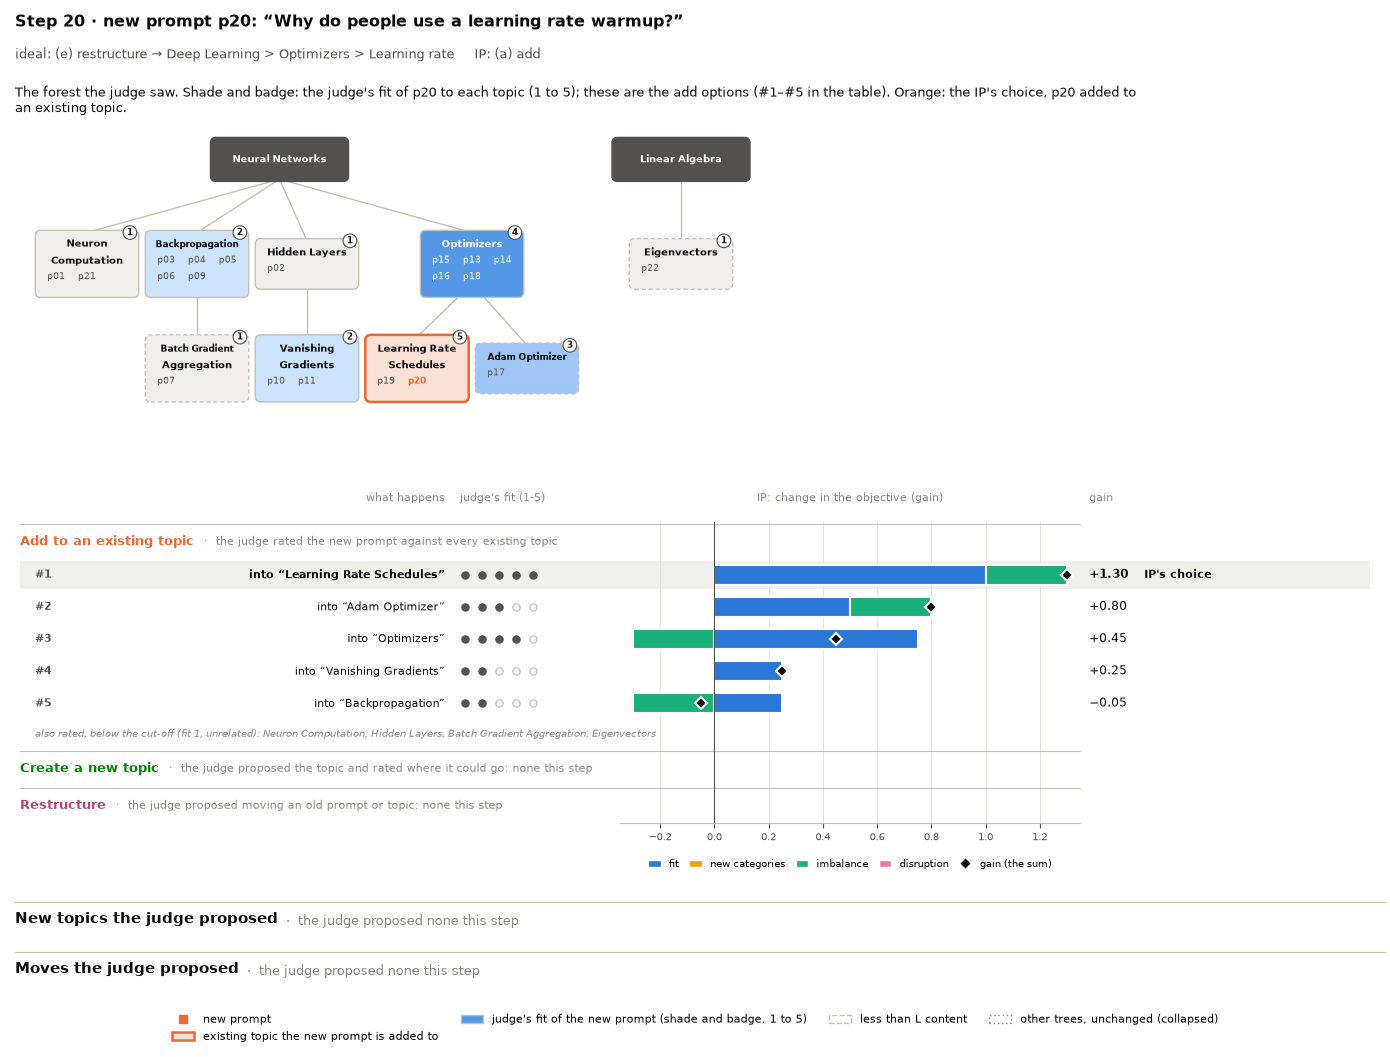

#### Step 21 of 25

| | |
|---|---|
| **input** | new prompt **p08**: “In the computational graph for f = (x + y) * z, what are the local gradients?”<br>forest before: 2 groups, 5 trees, 9 topics, 20 prompts |
| **judge** | fits: Backpropagation (4), Neuron Computation (2), Batch Gradient Aggregation (2); 6 more at (1)<br>proposes: new topic “Computational Graphs” (fit 5) under Backpropagation (parent fit 4) or Neural Networks (group) (parent fit 3); new topic “Local Gradients” (fit 5) under “Computational Graphs” (proposed) (parent fit 4) or Backpropagation (parent fit 3)<br>moves: p21 → Eigenvectors (4) |
| **output (IP)** | (b) new branch: p08 → Neural Networks > Backpropagation > Computational Graphs (new), alone ✗<br>rejected moves: p21 → Eigenvectors<br>rejected proposals: “Local Gradients”<br>objective: fit +21.50, new categories -0.40, imbalance -1.20, disruption +0.00 → total 19.90 |
| **ideal** | (a) add: p08 → Deep Learning > Neural networks > Backpropagation, with p03, p04, p05, p06, p07<br>why: Backpropagation goes above U, with no better place |
| **judge_argmax** | (b) new branch: p08 → Neural Networks > Backpropagation > Computational Graph > Local Gradients (new), alone ✗ |
| **chronological** | (c) new tree: p08 → Chat history > Prompts 21-25 (new), alone ✗ |

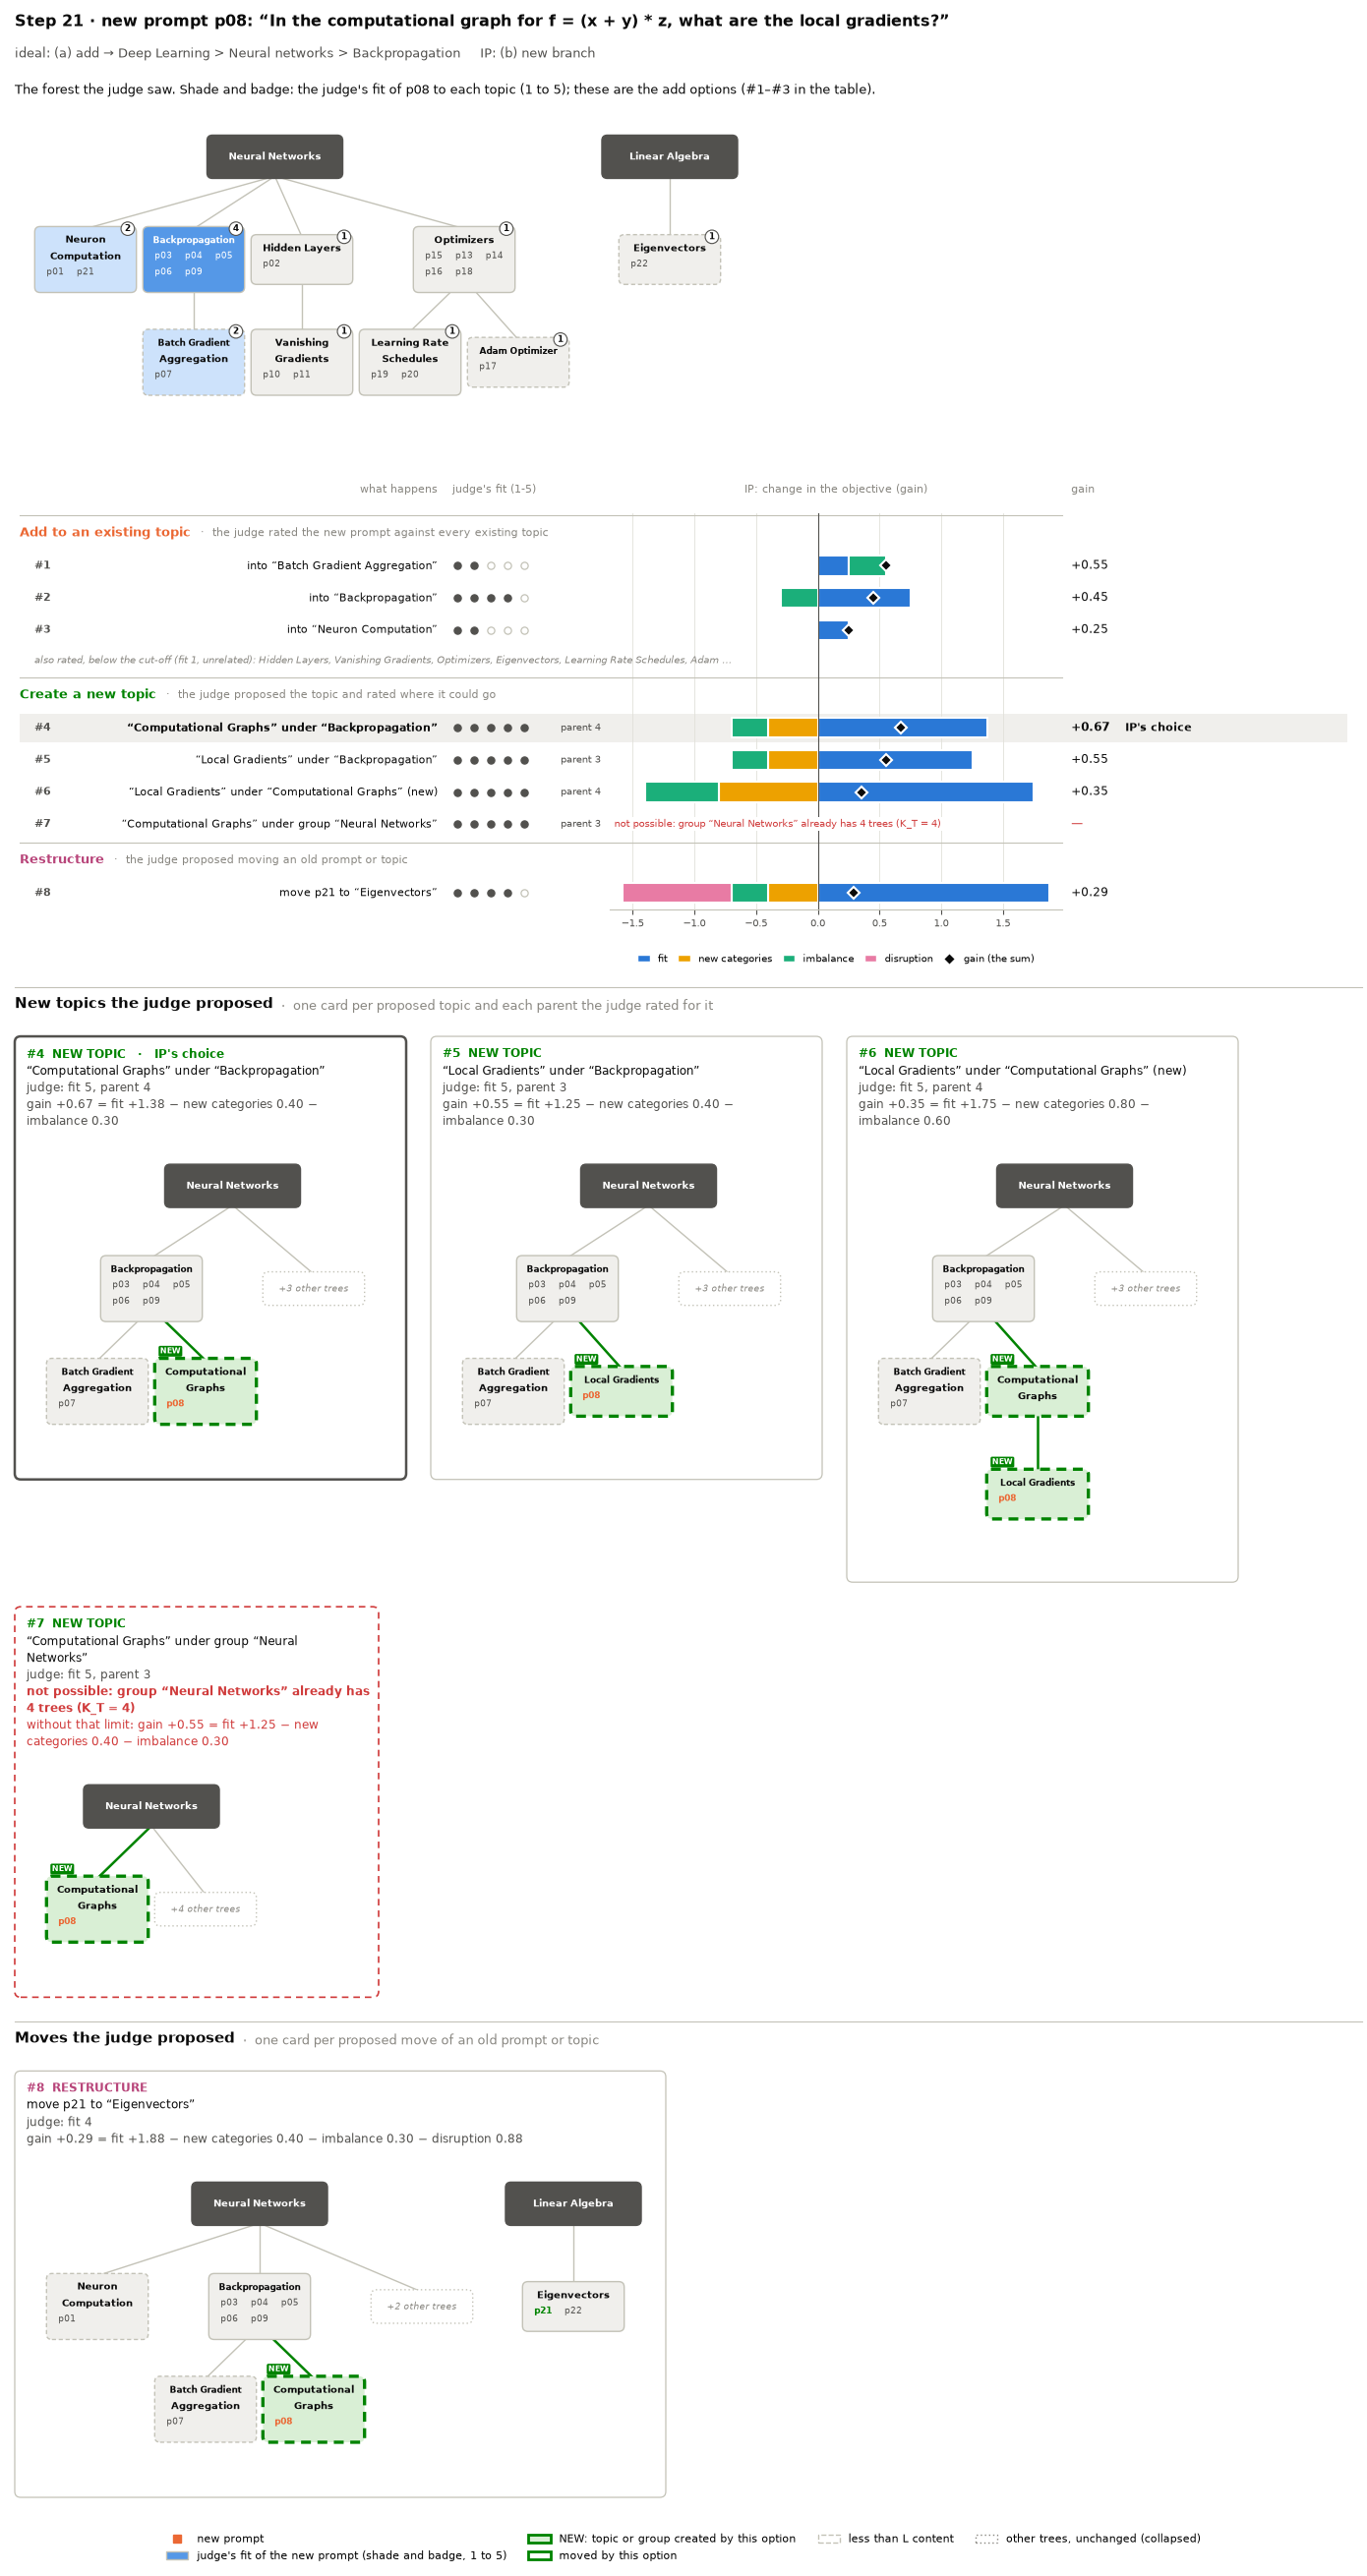

#### Step 22 of 25

| | |
|---|---|
| **input** | new prompt **p24**: “What is the difference between the SVD and an eigendecomposition?”<br>forest before: 2 groups, 5 trees, 10 topics, 21 prompts |
| **judge** | fits: Eigenvectors (3); 9 more at (1)<br>proposes: new topic “Matrix Decompositions” (fit 4) under Linear Algebra (group) (parent fit 5); new topic “Singular Value Decomposition” (fit 5) under “Matrix Decompositions” (proposed) (parent fit 5) or Eigenvectors (parent fit 3) or Linear Algebra (group) (parent fit 4)<br>moves: p21 → Eigenvectors (4); topic Eigenvectors → “Matrix Decompositions” (proposed) (3) |
| **output (IP)** | (b) new branch: p24 → Linear Algebra > Eigenvectors > Singular Value Decomposition (new), alone ✓<br>rejected moves: p21 → Eigenvectors; topic Eigenvectors → “Matrix Decompositions” (proposed)<br>rejected proposals: “Matrix Decompositions”<br>objective: fit +22.75, new categories -0.40, imbalance -1.20, disruption +0.00 → total 21.15 |
| **ideal** | (c) new tree: p24 → Linear Algebra > SVD, alone<br>why: SVD, a new tree in Linear Algebra |
| **judge_argmax** | (c) new tree: p24 → Linear Algebra > Singular Value Decomposition (new), alone ✓ |
| **chronological** | (a) add: p24 → Chat history > Prompts 21-25, with p08 ✗ |

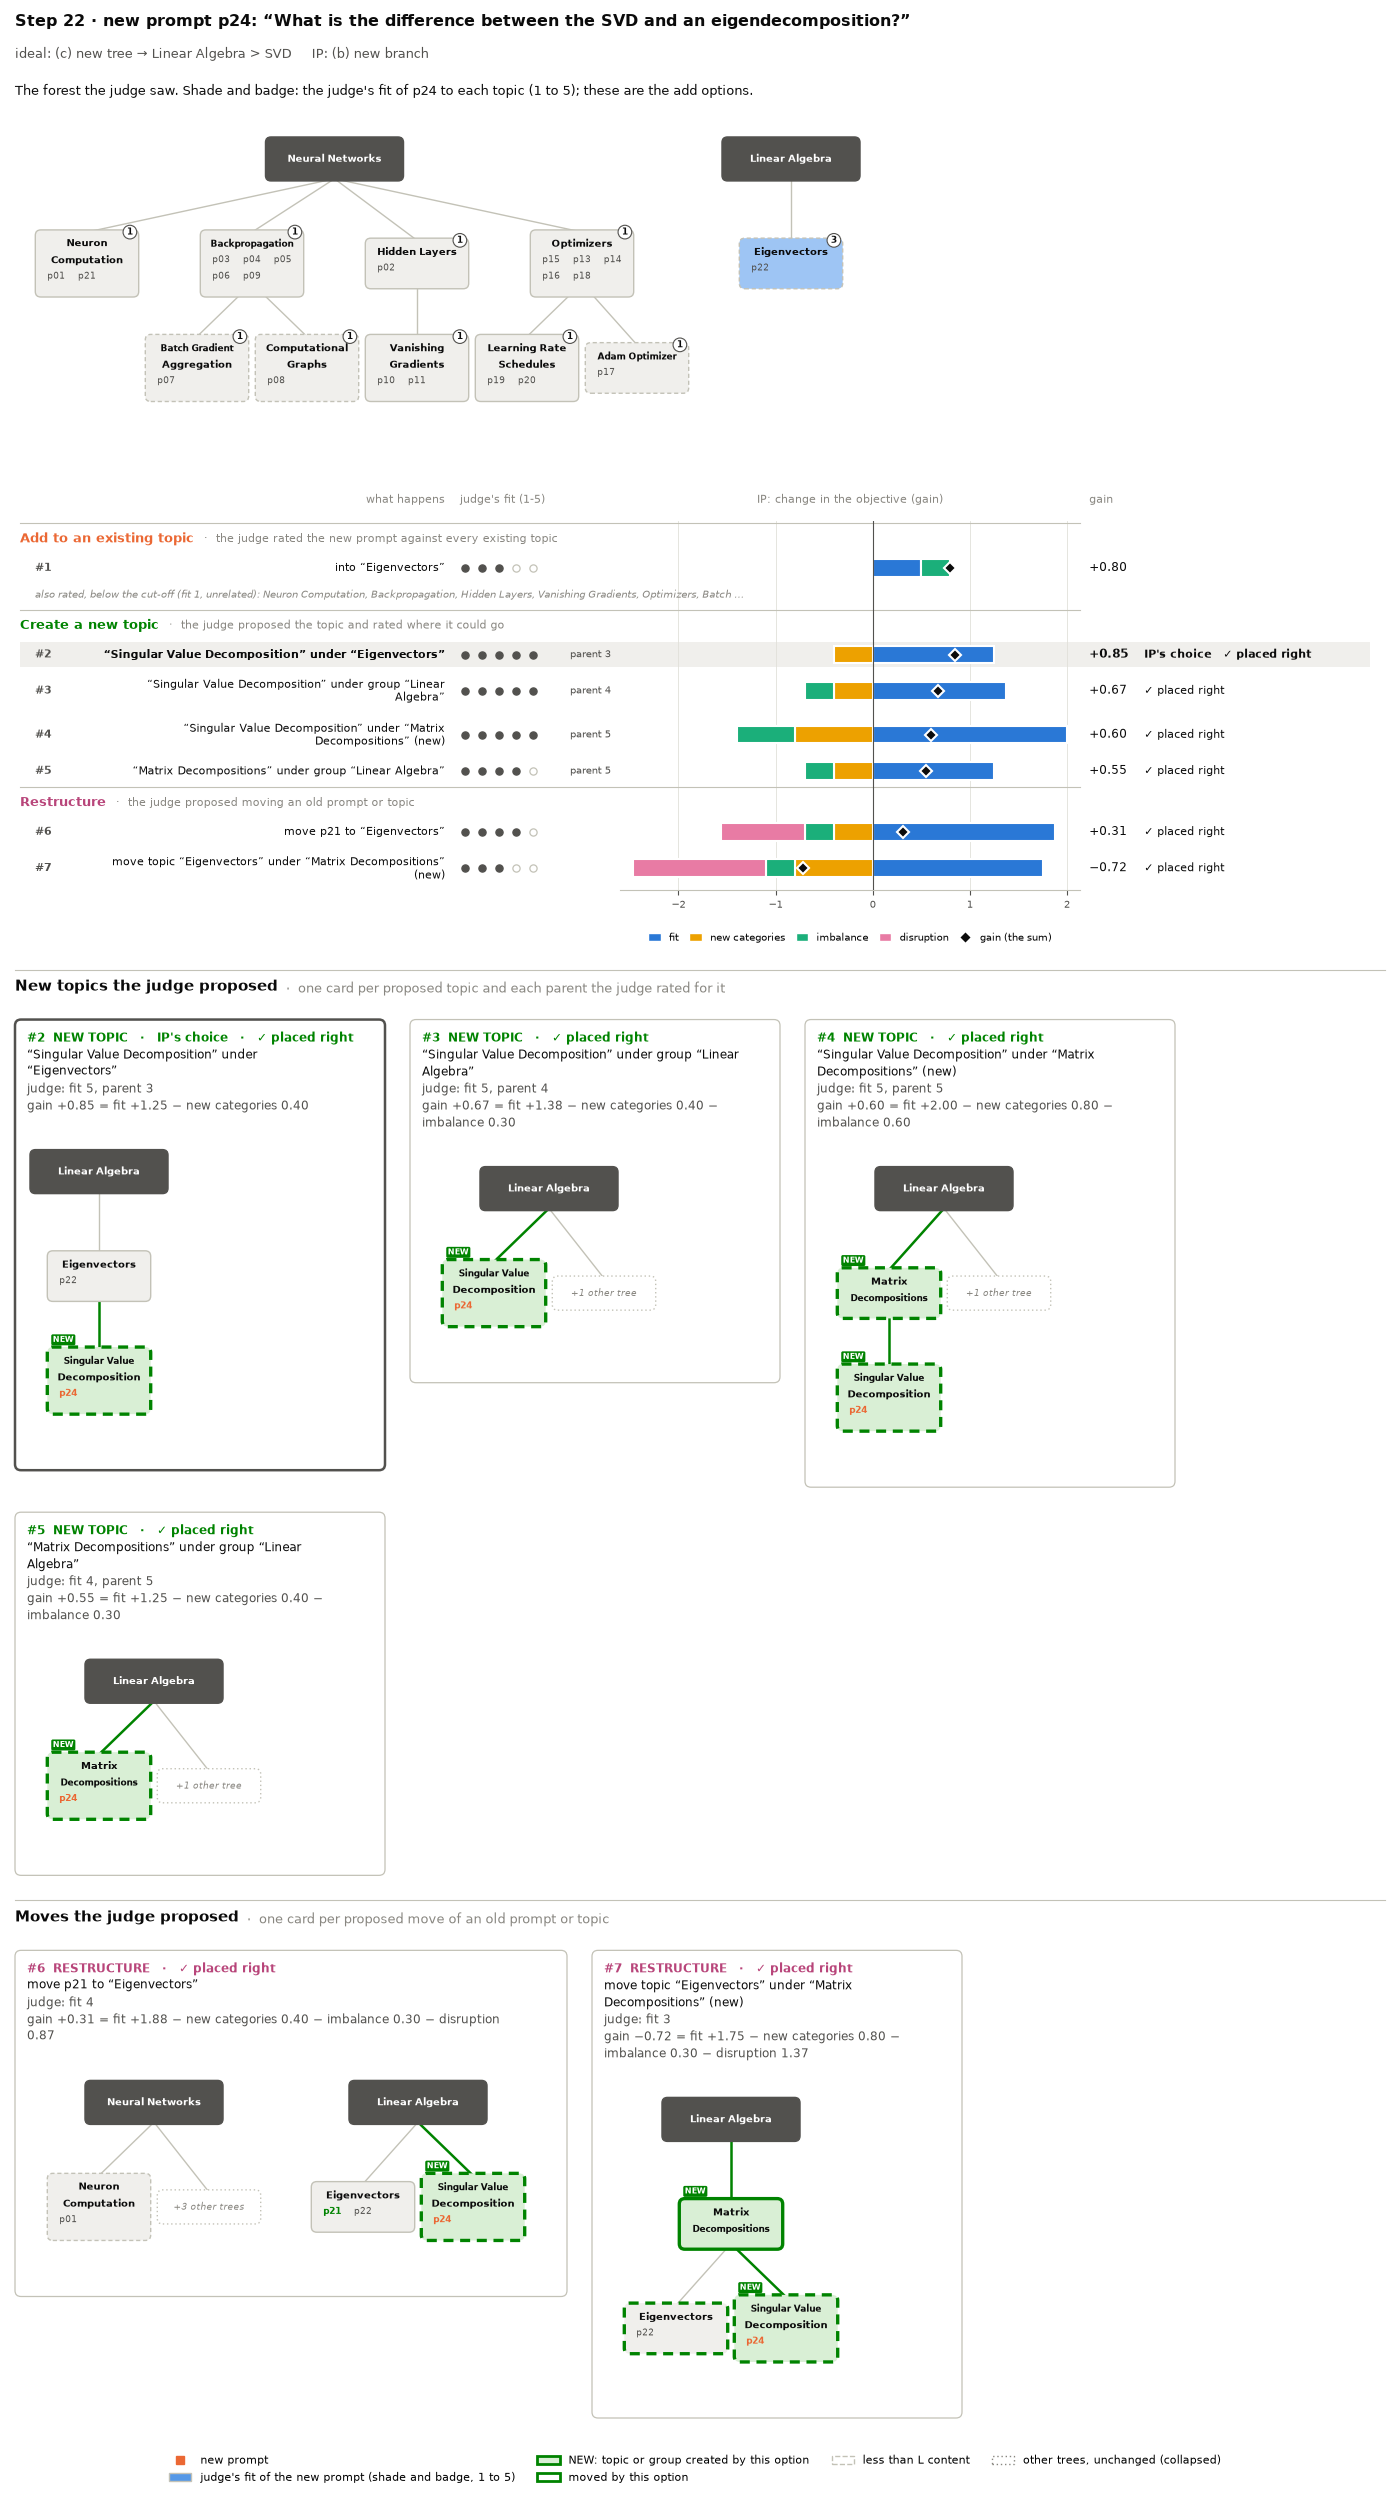

#### Step 23 of 25

| | |
|---|---|
| **input** | new prompt **p12**: “Do residual connections help against vanishing gradients?”<br>forest before: 2 groups, 5 trees, 11 topics, 22 prompts |
| **judge** | fits: Vanishing Gradients (5), Hidden Layers (3), Backpropagation (3), Optimizers (2), Computational Graphs (2); 6 more at (1)<br>proposes: new topic “Residual Connections” (fit 5) under Vanishing Gradients (parent fit 4) or Hidden Layers (parent fit 3) or Neural Networks (group) (parent fit 3)<br>moves: none |
| **output (IP)** | (a) add: p12 → Neural Networks > Hidden Layers > Vanishing Gradients, with p10, p11 ✓<br>rejected proposals: “Residual Connections”<br>objective: fit +23.75, new categories +0.00, imbalance -1.20, disruption +0.00 → total 22.55 |
| **ideal** | (a) add: p12 → Deep Learning > Neural networks > Training problems > Vanishing gradients, with p10, p11<br>why: vanishing gradients |
| **judge_argmax** | (a) add: p12 → Neural Networks > Backpropagation > Vanishing Gradients, with p10, p11 ✓ |
| **chronological** | (a) add: p12 → Chat history > Prompts 21-25, with p08, p24 ✗ |

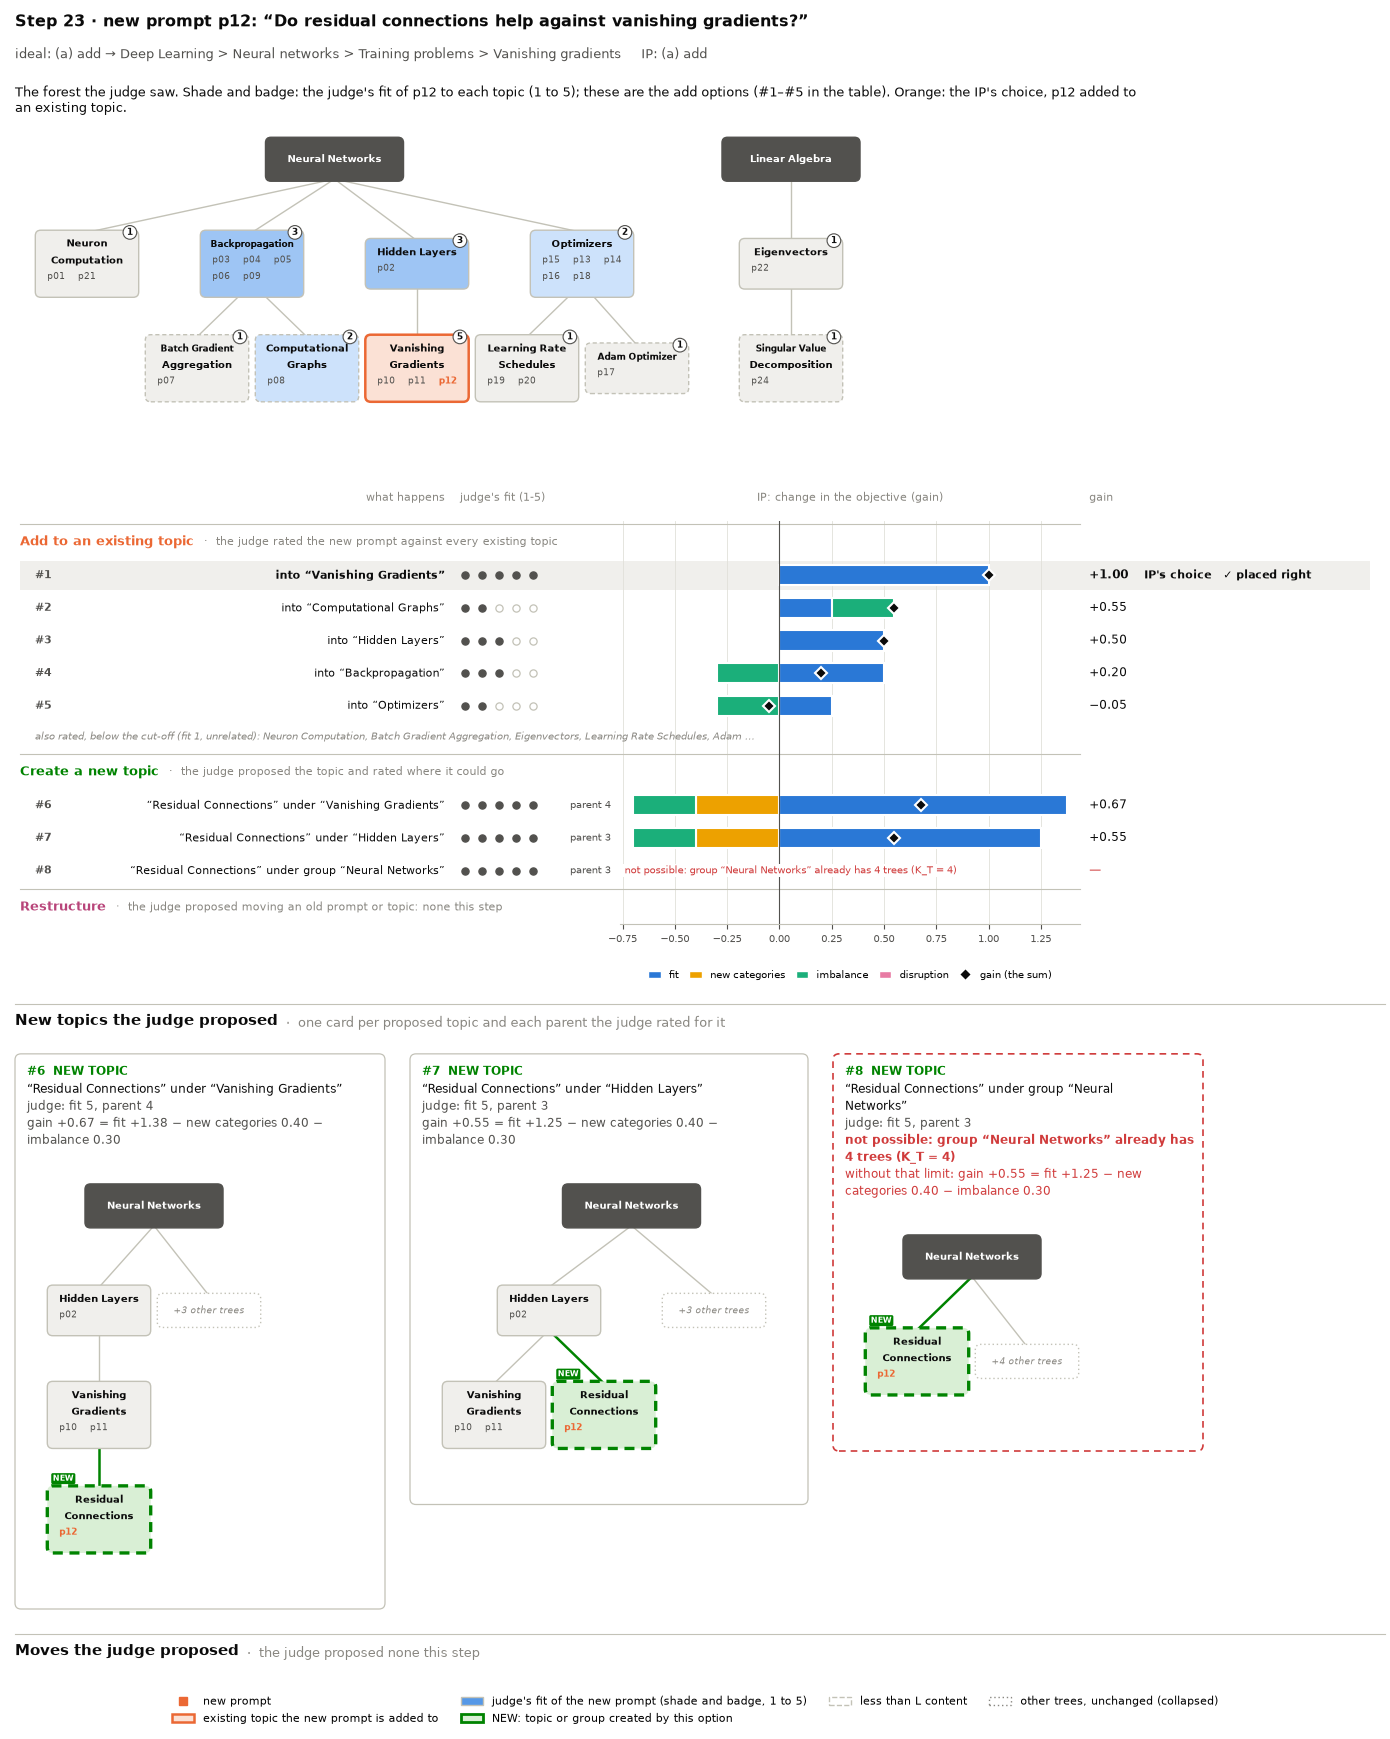

#### Step 24 of 25

| | |
|---|---|
| **input** | new prompt **p23**: “If a matrix has an eigenvalue 0, is it still invertible?”<br>forest before: 2 groups, 5 trees, 11 topics, 23 prompts |
| **judge** | fits: Eigenvectors (4), Neuron Computation (2), Singular Value Decomposition (2); 8 more at (1)<br>proposes: new topic “Invertible Matrices” (fit 5) under Eigenvectors (parent fit 4) or Linear Algebra (group) (parent fit 3)<br>moves: p21 → Eigenvectors (4) |
| **output (IP)** | (a) add: p23 → Linear Algebra > Eigenvectors, with p22 ✗<br>rejected moves: p21 → Eigenvectors<br>rejected proposals: “Invertible Matrices”<br>objective: fit +24.50, new categories +0.00, imbalance -1.20, disruption +0.00 → total 23.30 |
| **ideal** | (a) add: p23 → Linear Algebra > Eigenvalues, with p21, p22 |
| **judge_argmax** | (b) new branch: p23 → Linear Algebra > Eigenvalues > Matrix Invertibility (new), alone ✗ |
| **chronological** | (a) add: p23 → Chat history > Prompts 21-25, with p08, p24, p12 ✗ |

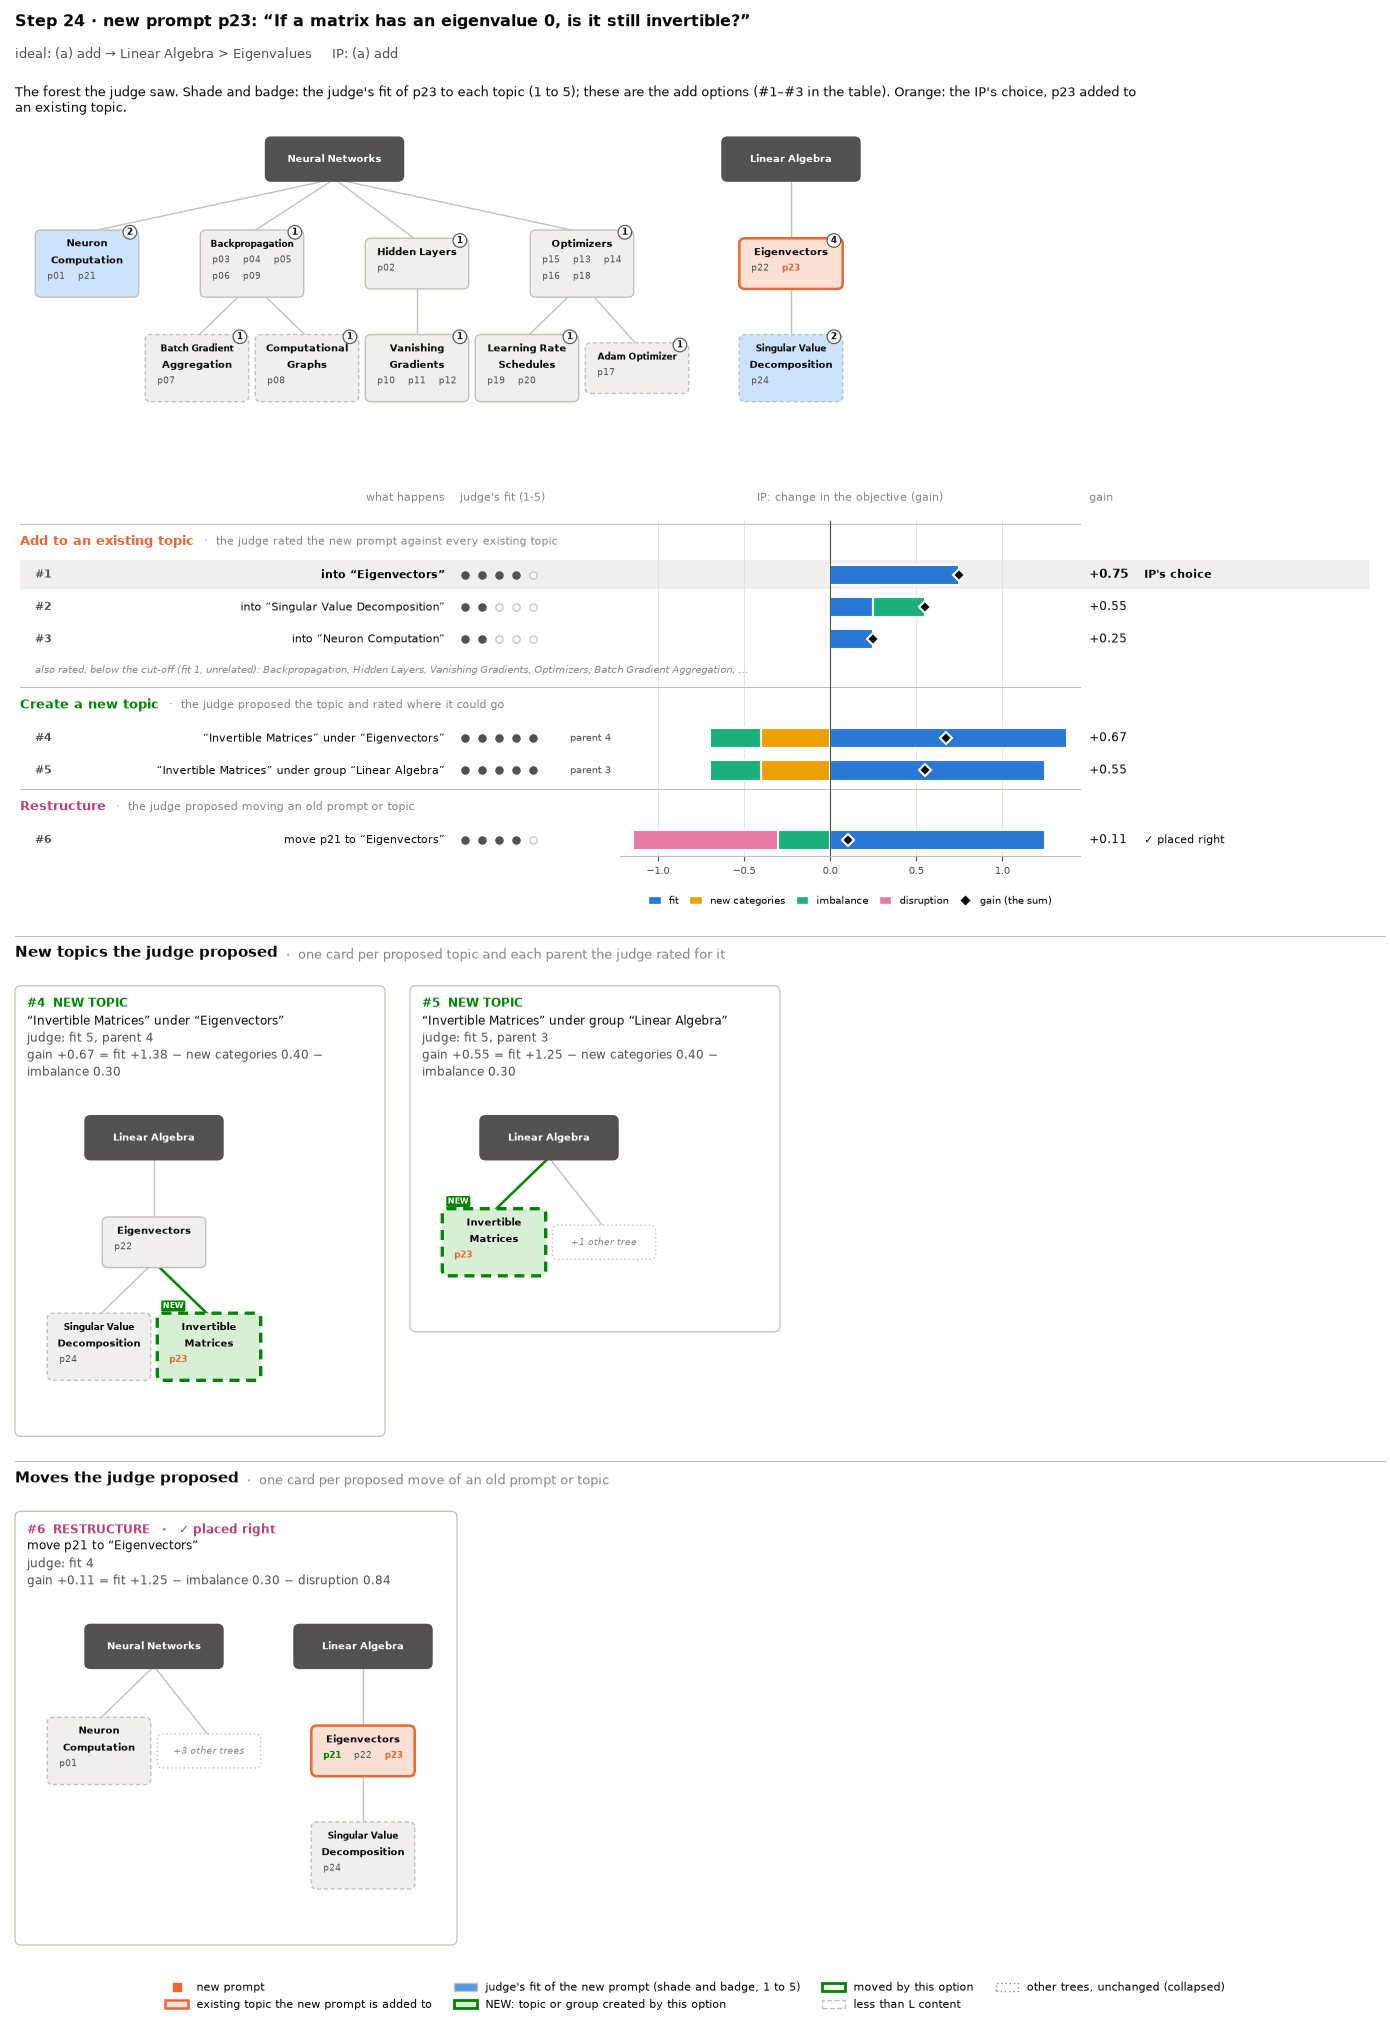

#### Step 25 of 25

| | |
|---|---|
| **input** | new prompt **p25**: “How is the SVD used for a low-rank approximation?”<br>forest before: 2 groups, 5 trees, 11 topics, 24 prompts |
| **judge** | fits: Singular Value Decomposition (5), Hidden Layers (2), Eigenvectors (2); 8 more at (1)<br>proposes: new topic “Low-Rank Approximation” (fit 5) under Singular Value Decomposition (parent fit 5) or Linear Algebra (group) (parent fit 3)<br>moves: p21 → Eigenvectors (4); topic Singular Value Decomposition → Linear Algebra (group) (4) |
| **output (IP)** | (a) add: p25 → Linear Algebra > Eigenvectors > Singular Value Decomposition, with p24 ✓<br>rejected moves: p21 → Eigenvectors; topic Singular Value Decomposition → Linear Algebra (group)<br>rejected proposals: “Low-Rank Approximation”<br>objective: fit +25.50, new categories +0.00, imbalance -0.90, disruption +0.00 → total 24.60 |
| **ideal** | (a) add: p25 → Linear Algebra > SVD, with p24 |
| **judge_argmax** | (a) add: p25 → Linear Algebra > Singular Value Decomposition, with p24 ✓ |
| **chronological** | (a) add: p25 → Chat history > Prompts 21-25, with p08, p24, p12, p23 ✗ |

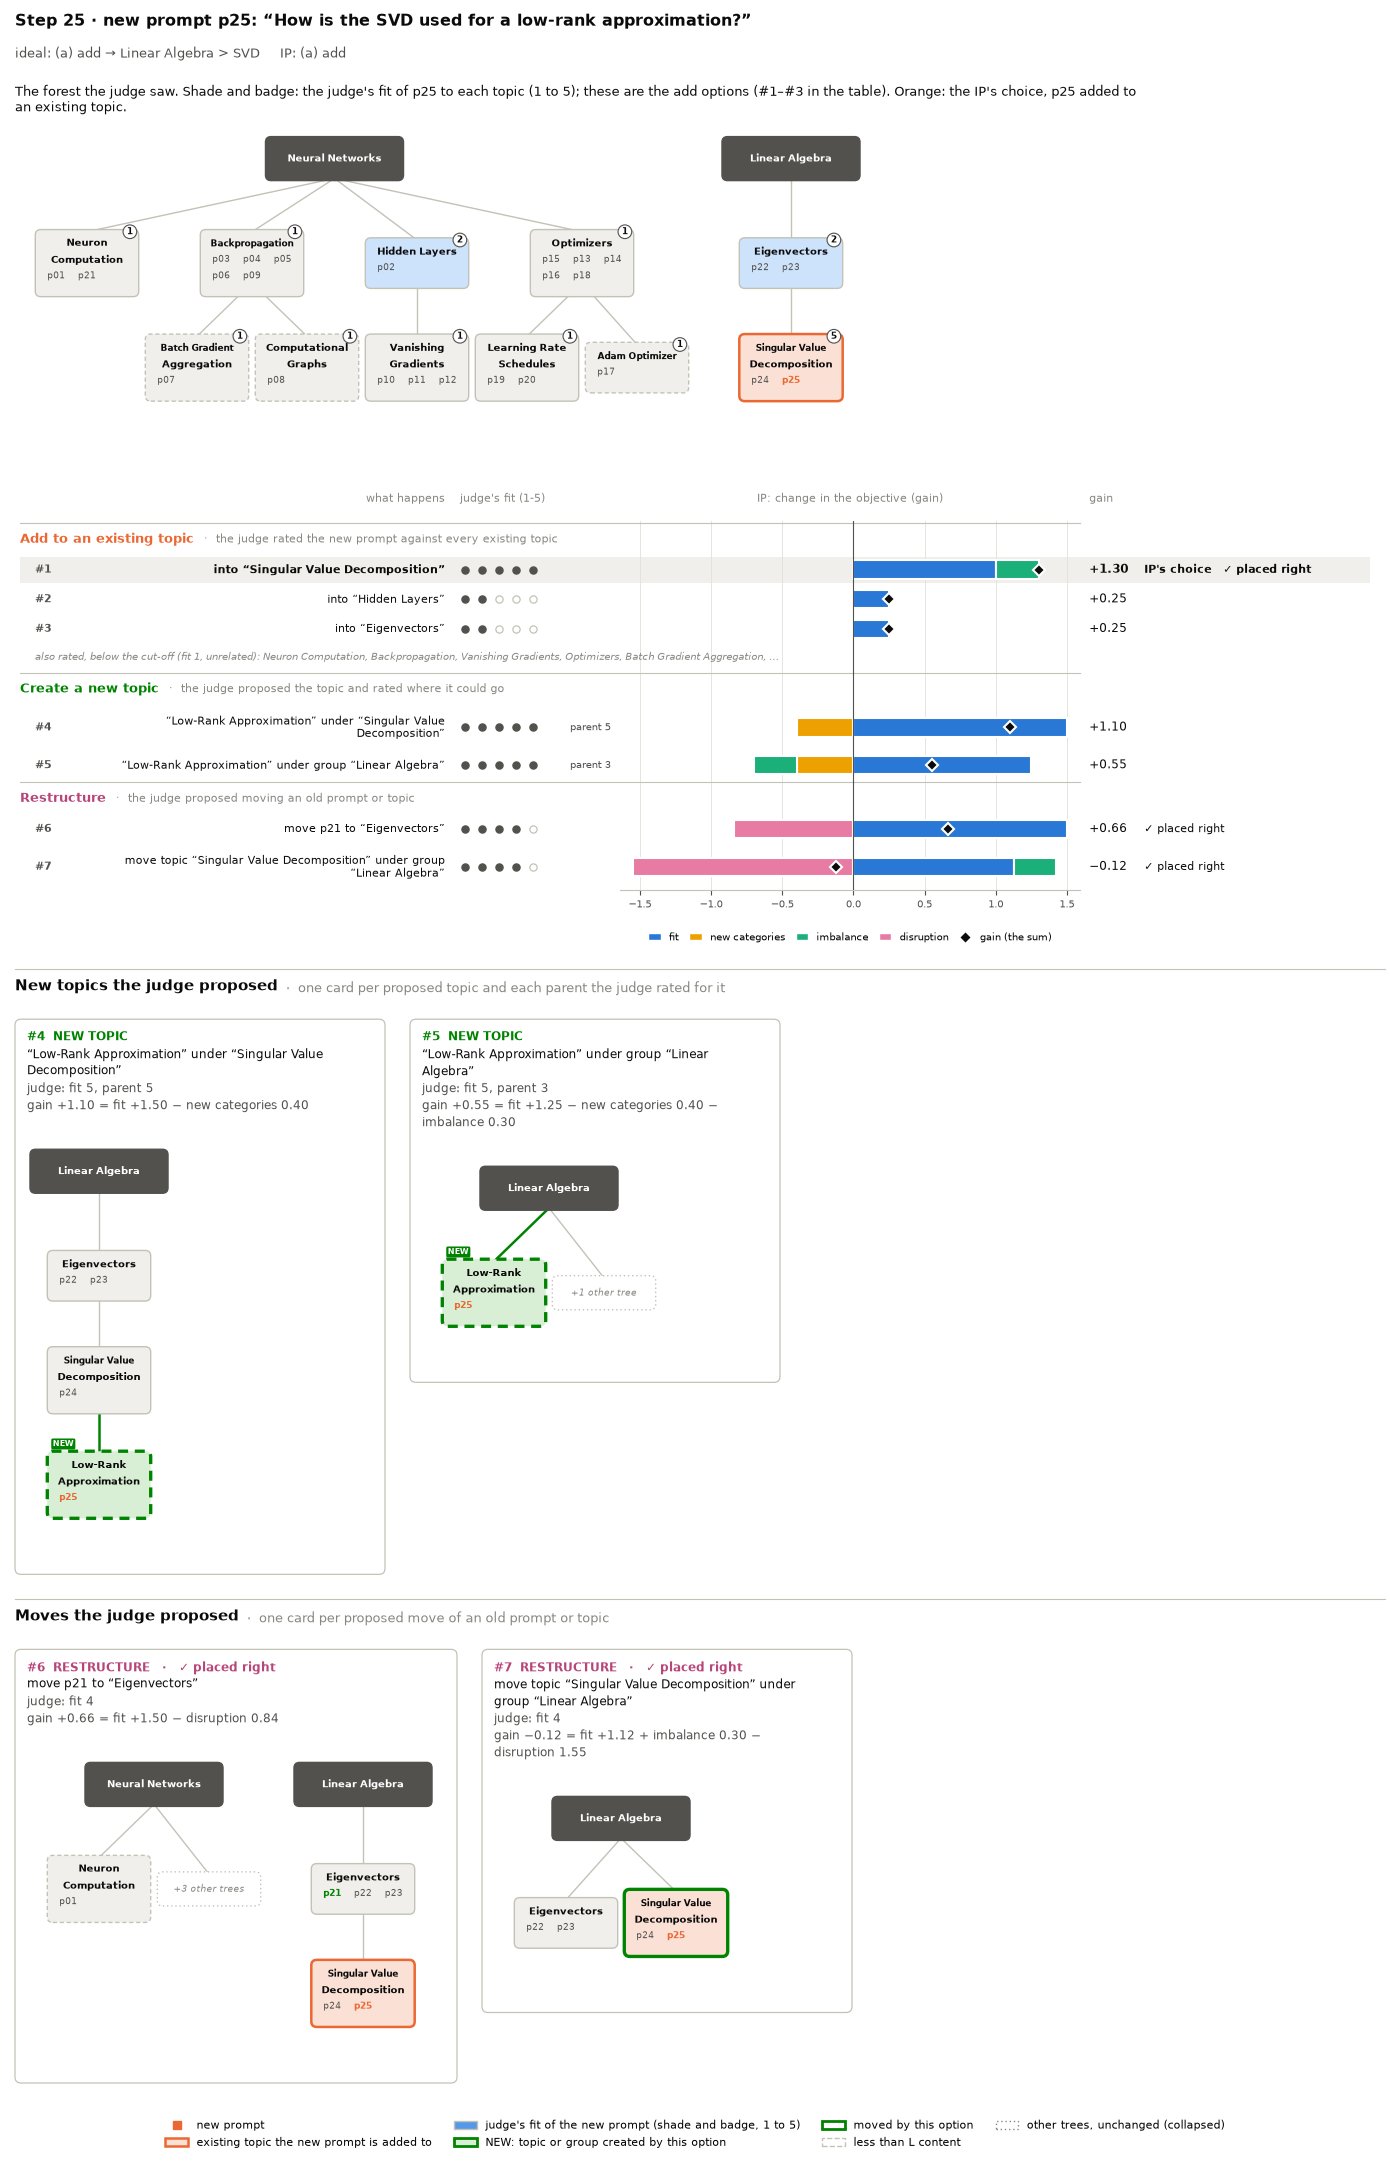

In [5]:
for i, s in enumerate(ip.steps):
    display(Markdown(viz.step_card(s, ideal, {m: r.steps[i] for m, r in main.items() if m != "ip"})))
    viz.step_explainer(s, ideal, P)
    plt.show()

## 5. Comparing the approaches
Per step: the action each approach took, ✓ or ✗ as above, and whether the IP put the new prompt
somewhere other than the judge's top option.

In [6]:
mark = lambda s: f"({s.decision.action}) {'✓' if s.metrics['placed_right'] else '✗'}"
pd.DataFrame({"prompt": [s.prompt.id for s in ip.steps], "ideal": [f"({s.intended})" for s in ip.steps],
              **{m: [mark(s) for s in r.steps] for m, r in main.items()},
              "IP differs from judge's top": [s.differs for s in ip.steps]},
             index=pd.Index(range(1, len(ip.steps) + 1), name="step"))

,prompt,ideal,ip,judge_argmax,chronological,IP differs from judge's top
step,,,,,,
1,p01,(d),(d) ✓,(d) ✓,(d) ✓,False
2,p03,(b),(c) ✓,(c) ✓,(a) ✗,False
3,p04,(a),(a) ✓,(b) ✗,(a) ✗,True
4,p02,(a),(c) ✗,(c) ✗,(a) ✗,False
5,p05,(a),(a) ✓,(a) ✗,(a) ✗,False
6,p10,(b),(b) ✓,(b) ✓,(c) ✓,True
7,p15,(c),(c) ✓,(c) ✓,(a) ✗,False
8,p13,(b),(a) ✗,(c) ✓,(a) ✗,True
9,p06,(a),(a) ✓,(b) ✗,(a) ✗,True


The totals for the three approaches. `placed right` is the share of steps with ✓;
`final f1 topic` is the pairwise F1 against the ideal forest after the last step (Section 6).

In [7]:
runs = list(main.values())
summary(runs).drop(columns=["max vars"]).round(3)

,run,method,judge,final f1 topic,final f1 tree,placed right,moved prompts (w),moved topics,deleted,restructures,over U (final),under L (final),differs from argmax,max constrs,actions
0,ip_llm(claude-haiku-5-5),ip,llm(claude-haiku-5-5),0.491,0.523,0.44,0,0,0,0,0,3,0.4,234.0,a:14 b:6 c:3 d:2
1,judge_argmax_llm(claude-haiku-5-5),judge_argmax,llm(claude-haiku-5-5),0.286,0.616,0.48,0,0,0,0,0,15,NaN,NaN,a:4 b:13 c:6 d:2
2,chronological,chronological,none,0.175,0.288,0.12,0,0,0,0,0,0,NaN,NaN,a:20 c:4 d:1


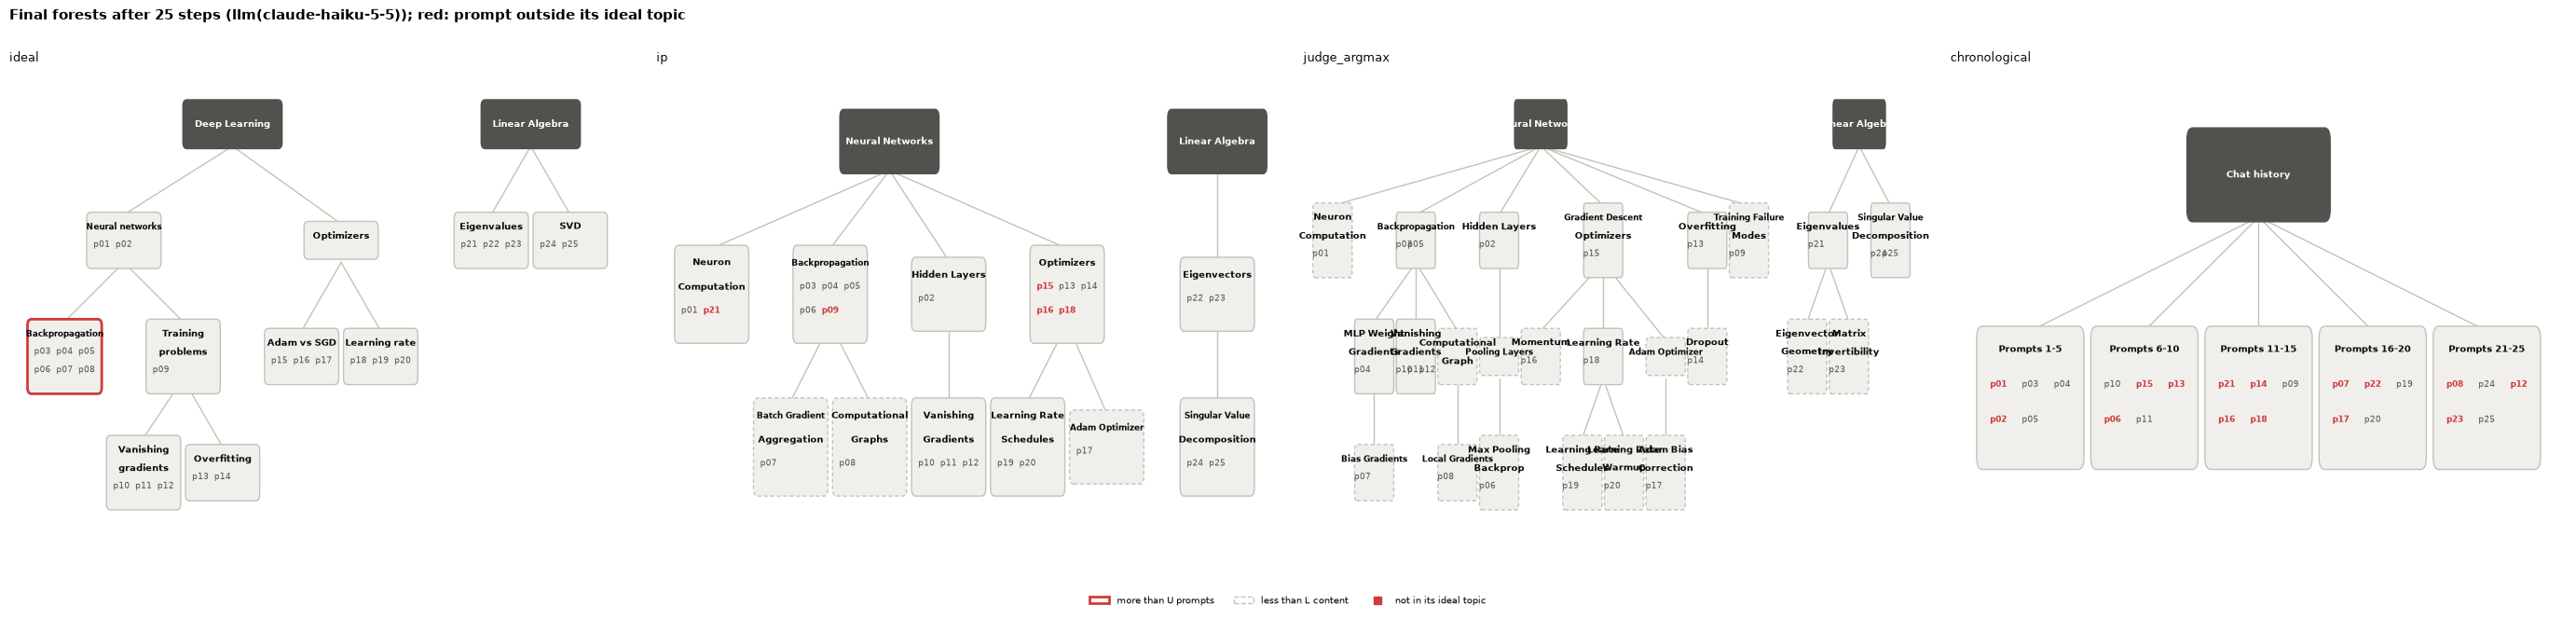

In [8]:
fig = viz.compare_view({"ideal": ideal.forest, **{m: r.final for m, r in main.items()}}, ideal, P,
                       title=f"Final forests after {len(ip.steps)} steps ({judge.name}); red: prompt outside its ideal topic")
plt.show()

## 6. Graphs and diagrams
**Agreement and disruption over the session.** Pairwise F1: over all pairs of placed prompts, how
well "these two share a topic" matches the ideal forest (1 is a perfect match, label-independent).
Weighted moved prompts: how much of what the student had already seen was moved, recent prompts
counting more. Colour: approach.

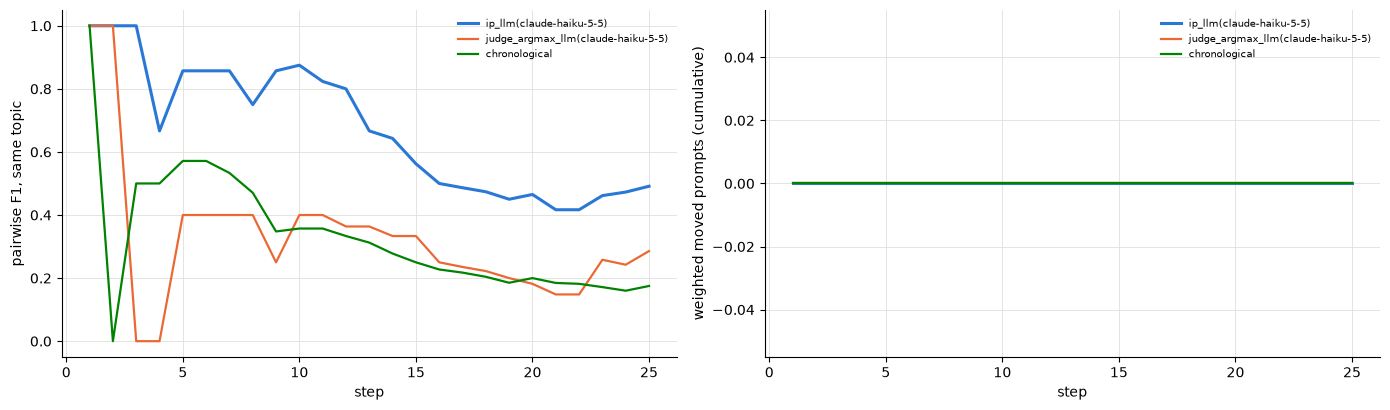

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
viz.line_runs(runs, "f1_topic", axes[0], "pairwise F1, same topic")
viz.line_runs(runs, "moved_prompts_w", axes[1], "weighted moved prompts (cumulative)", cumulative=True)
fig.tight_layout()
plt.show()

**The action per step.** One row per approach, one cell per step, coloured by the action: (a) add,
(b) new branch, (c) new tree, (d) new group, (e) restructure. The top row is the outcome the
session was written to need. Hatched: the new prompt did not land with its ideal topic-mates.
`chronological` follows a fixed pattern by design: (d) for its one group at step 1, (c) for a new
tree every 5 prompts, (a) otherwise. `judge_argmax` never restructures (it ignores proposed moves).

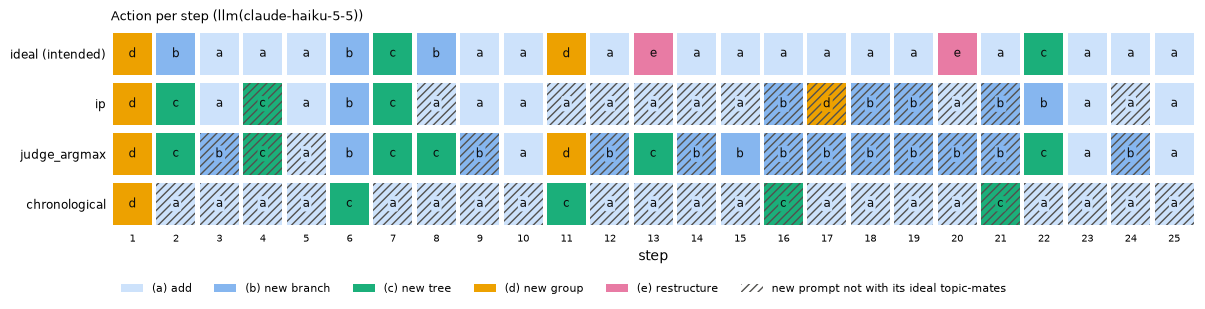

In [10]:
rows = {"ideal (intended)": [s.intended for s in ip.steps], **{m: [s.decision.action for s in r.steps] for m, r in main.items()}}
ok = {m: [s.metrics["placed_right"] for s in r.steps] for m, r in main.items()}
fig, ax = plt.subplots(figsize=(14, 2.6))
viz.action_timeline(rows, ok, ax, f"Action per step ({judge.name})")
plt.show()

**What-if: the stability weights.** Every step re-solved with its stored judge answer, for every pair
of `mu` (cost per moved prompt) and `F` (fixed cost of any restructure): the share of steps where the
new prompt is placed right, the steps whose decision is a restructure, and the chosen action at the
step that reacts most to the weights. Each step keeps the forest the IP built with the chosen
weights, so this shows each step's decision, not a whole new session (that would need new model
calls).

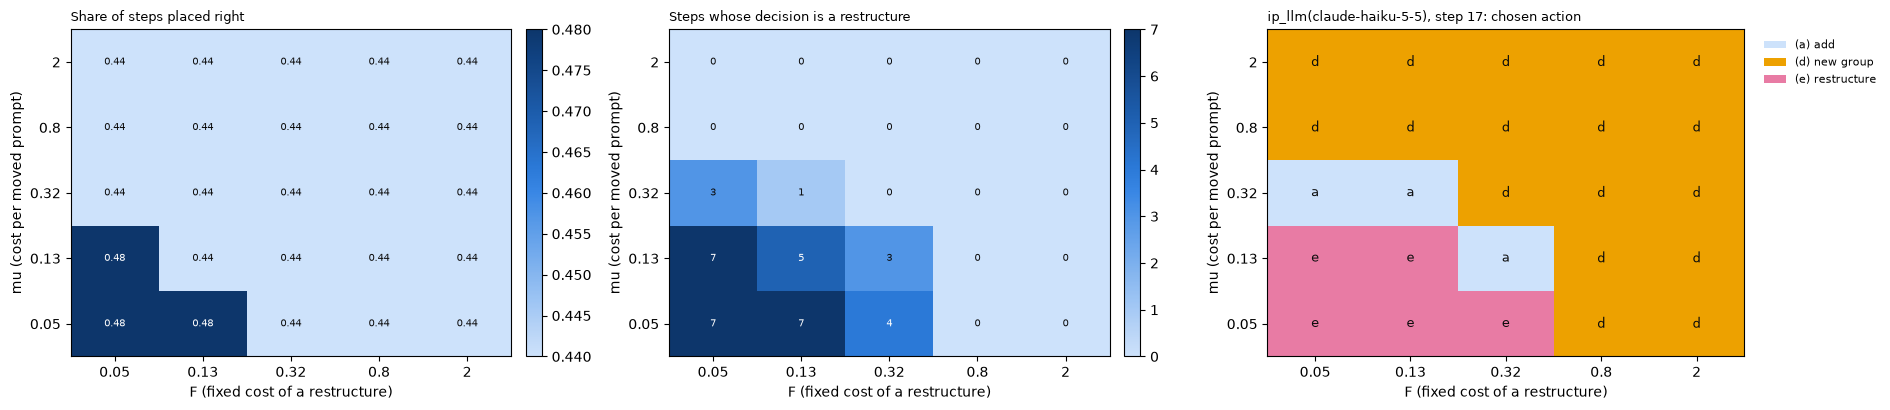

In [11]:
from forest.metrics import placed_right

GRID = [float(f"{v:.3g}") for v in np.geomspace(0.05, 2, 5)]
rows, acts = [], {}
for mu in GRID:
    for F_ in GRID:
        res = [solve(st.before, st.prompt, st.judge, st.step, P.replace(mu=mu, F=F_)) for st in ip.steps]
        for st, (_, dec) in zip(ip.steps, res):
            acts[(st.step, mu, F_)] = dec.action
        rows.append({"mu": mu, "F": F_,
                     "placed right": np.mean([placed_right(after, ideal, st.prompt.id) for st, (after, _) in zip(ip.steps, res)]),
                     "restructures": sum(dec.action == "e" for _, dec in res)})
sweep = pd.DataFrame(rows)
best = max(ip.steps, key=lambda st: (len({acts[(st.step, mu, F_)] for mu in GRID for F_ in GRID}), -st.step))
flip = pd.DataFrame([{"mu": mu, "F": F_, "action": acts[(best.step, mu, F_)]} for mu in GRID for F_ in GRID]
                    ).pivot(index="mu", columns="F", values="action")
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
viz.heatmap(sweep.pivot(index="mu", columns="F", values="placed right"), axes[0], "Share of steps placed right")
viz.heatmap(sweep.pivot(index="mu", columns="F", values="restructures"), axes[1], "Steps whose decision is a restructure", "{:.0f}")
viz.action_heatmap(flip, axes[2], f"{ip.name}, step {best.step}: chosen action")
fig.tight_layout()
plt.show()

## 7. Export for the prototype
The IP's forest after every step, as JSON (`outputs/forests/<run>/sequence.json`, one snapshot per
step next to it). This is the run with the LLM judge, the one for the prototype.

In [12]:
path = ROOT / "outputs" / "forests" / ip.slug / "sequence.json"
print(f"exported {ip.name}: {path.relative_to(ROOT)} ({len(ip.steps)} steps)")
print("LLM calls made by this notebook:", judge.calls)

exported ip_llm(claude-haiku-5-5): outputs/forests/ip_llm_claude-haiku-5-5/sequence.json (25 steps)
LLM calls made by this notebook: 0
